# Uber Daily Total Fare Forecasting


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
from scipy.stats import kstest
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

SEPARATOR = "=" * 50

## 1. Tinjauan Awal

In [58]:
df = pd.read_csv('uber.csv') 

print(SEPARATOR)
print("DIMENSI DATA")
print(SEPARATOR)
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}\n")

print("\n",SEPARATOR)
print("TAMPILAN 5 BARIS PERTAMA")
print(SEPARATOR)
display(df.head())

DIMENSI DATA
Jumlah Baris: 200000
Jumlah Kolom: 9


TAMPILAN 5 BARIS PERTAMA


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


### *Hasil Observasi: Tinjauan Awal*

**Temuan Data:**
Dataset tersebut memiliki ukuran **200.000 baris dan 9 kolom** dengan estimasi penggunaan memori sebesar 13.7+ MB. Setiap baris merepresentasikan satu transaksi perjalanan Uber, yang mencakup informasi biaya (`fare_amount`), waktu penjemputan (`pickup_datetime`), koordinat asal-tujuan, dan jumlah penumpang. Terdapat kolom indeks `Unnamed: 0` dan `key` yang berperan sebagai identifier transaksi mentah.

**Keputusan:**
Dataset memiliki volume yang cukup representatif untuk pemodelan prediktif. Namun, tipe data `pickup_datetime` yang masih berupa teks (*object*) dan kolom koordinat perlu divalidasi keabsahan nilainya sebelum dapat dimanfaatkan.

## 2. Statistika Deskriptif

In [59]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


### *Hasil Observasi: Statistika Deskriptif*

Ringkasan statistika di atas mengungkap bahwa data mentah memiliki **sejumlah nilai ekstrem yang perlu di tinjau lebih dalam terhadap logika bisnis yang ada**, antara lain:

1. **Tarif Tidak Logis (`fare_amount`):** Ditemukan tarif **bernilai minus (< $0)**, serta nilai ekstrem atas (mencapai **$499**) yang memerlukan validasi rasionalitas jarak tempuhnya.
2. **Kapasitas Penumpang (`passenger_count`):** Tercatat angka maksimum hingga **208 penumpang** menggambarkan kapasitas dalam satu kendaraan.
3. **Pelanggaran Koordinat GPS (`latitude` & `longitude`):** Terdapat nilai koordinat yang **melampaui batas fisik bumi (> 360°)**, titik koordinat *default* `(0, 0)` di lautan lepas, serta titik di luar wilayah operasional metropolitan New York City.

**Tindak Lanjut:** 
Temuan awal ini menjadi dasar investigasi mendalam pada bab-bab berikutnya: nilai koordinat akan ditangani melalui koreksi dan pembatasan wilayah *NYC Bounding Box* (**Bab 5**), sedangkan nilai tarif dan kapasitas penumpang akan disaring secara terukur pada tahap deteksi & pembersihan outlier (**Bab 10**).

## 3. Verifikasi Tipe Data

In [60]:
# [Deteksi]
print(SEPARATOR)
print("RINGKASAN TIPE DATA (PANDAS INFERENCE)")
print(SEPARATOR)
tipe_data_df = pd.DataFrame(df.dtypes, columns=['Tipe_Data'])
display(tipe_data_df)

print("\n", SEPARATOR)
print("POTENSI KESALAHAN TIPE DATA (HEURISTIC CHECK)")
print(SEPARATOR)

potensi_isu = False
for col in df.columns:
        # Cek ID numerik (Biasanya nama kolom mengandung 'id' tapi terbaca numerik)
        if 'id' in col.lower() and pd.api.types.is_numeric_dtype(df[col]):
                print(f"[!] Kolom '{col}' terbaca sebagai {df[col].dtype}. Jika ini identifier (ID), ubah menjadi object/string.")
                potensi_isu = True

        # Cek tanggal yang terbaca string (Biasanya nama kolom mengandung 'date', 'time', 'tgl')
        elif any(k in col.lower() for k in ['date', 'time', 'tgl', 'tanggal']) and pd.api.types.is_object_dtype(df[col]):
                print(f"[!] Kolom '{col}' terbaca sebagai {df[col].dtype}. Pastikan bukan format datetime yang gagal ter-parse.")
                potensi_isu = True

if not potensi_isu:
        print("Tidak terdeteksi anomali tipe data secara heuristik.")

RINGKASAN TIPE DATA (PANDAS INFERENCE)


,Tipe_Data
Unnamed: 0,int64
key,object
fare_amount,float64
pickup_datetime,object
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
passenger_count,int64



POTENSI KESALAHAN TIPE DATA (HEURISTIC CHECK)
[!] Kolom 'pickup_datetime' terbaca sebagai object. Pastikan bukan format datetime yang gagal ter-parse.


### *Penanganan: Konversi Tipe Data*

In [61]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], format='%Y-%m-%d %H:%M:%S %Z')

df.dtypes

Unnamed: 0                         int64
key                               object
fare_amount                      float64
pickup_datetime      datetime64[ns, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object

In [62]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


### *Hasil Observasi: Konversi Tipe Data*

Ditemuan pada Data terdapat penerapan tipe data yang mesih salah, yaitu Kolom `pickup_datetime` awalnya terbaca sebagai tipe `object`. Oleh karena itu, dilakukan konversi `pickup_datetime` menjadi format resmi `datetime64[ns, UTC]`. Ini adalah langkah fundamental yang memungkinkan kita mengekstrak fitur turunan waktu (*feature engineering*) seperti jam sibuk, hari dalam seminggu, bulan, dan kuartal.

## 4. Deteksi Inkonsistensi Data Kategorikal

In [63]:
# [Deteksi]
kolom_kotor = []
print(SEPARATOR)
print("DAFTAR NAMA KOLOM SAAT INI")
print(SEPARATOR)
print(df.columns.tolist())
print("\n")

print(SEPARATOR)
print("DETEKSI ANOMALI FORMAT NAMA KOLOM")
print(SEPARATOR)
for col in df.columns:
    isu = []
    if ' ' in col:
        isu.append("Mengandung spasi")
    if col != col.strip():
        isu.append("Terdapat spasi di awal/akhir (leading/trailing space)")
    if any(char.isupper() for char in col) and any(char.islower() for char in col):
        isu.append("Huruf kapital tidak konsisten")
    
    if isu:
        kolom_kotor.append(col)
        print(f"Kolom: '{col}' -> Isu: {', '.join(isu)}")

if not kolom_kotor:
    print("Tidak ditemukan anomali format (spasi/kapital) pada nama kolom.")

DAFTAR NAMA KOLOM SAAT INI
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']


DETEKSI ANOMALI FORMAT NAMA KOLOM
Kolom: 'Unnamed: 0' -> Isu: Mengandung spasi, Huruf kapital tidak konsisten


In [64]:
# [Deteksi]
print(SEPARATOR)
print("INSPEKSI NILAI UNIK (KOLOM OBJEK/STRING)")
print(SEPARATOR)

# Hanya memilih kolom dengan tipe data object atau category
cat_cols = df.select_dtypes(include=['object', 'category']).columns

if len(cat_cols) == 0:
        print("Tidak ada kolom kategorikal (object) dalam dataset.")
else:
        for col in cat_cols:
                unique_vals = df[col].dropna().unique()
                num_unique = len(unique_vals)
                
                print(f"\n--- Kolom: '{col}' ({num_unique} nilai unik) ---")
                
                # Jika nilai unik terlalu banyak, batasi tampilannya
                if num_unique > 15:
                        print(f"Top 10 nilai dengan frekuensi terbanyak:")
                        print(df[col].value_counts().head(10))
                        print(f"...dan {num_unique - 10} nilai lainnya.")
                else:
                        print("Distribusi nilai:")
                        print(df[col].value_counts())
                
                # Cek spasi tersembunyi
                whitespace_issues = [val for val in unique_vals if isinstance(val, str) and (val != val.strip())]
                if whitespace_issues:
                        print(f"[!] Terdeteksi spasi awal/akhir (whitespace) pada nilai berikut: {whitespace_issues[:5]}...")

INSPEKSI NILAI UNIK (KOLOM OBJEK/STRING)

--- Kolom: 'key' (200000 nilai unik) ---
Top 10 nilai dengan frekuensi terbanyak:
key
2015-05-07 19:52:06.0000003      1
2009-07-17 20:04:56.0000002      1
2009-08-24 21:45:00.00000061     1
2009-06-26 08:22:21.0000001      1
2014-08-28 17:47:00.000000188    1
2011-02-12 02:27:09.0000006      1
2014-10-12 07:04:00.0000002      1
2012-12-11 13:52:00.00000029     1
2012-02-17 09:32:00.00000043     1
2012-03-29 19:06:00.000000273    1
Name: count, dtype: int64
...dan 199990 nilai lainnya.


In [65]:
# [Penanganan] Standardisasi Nama Kolom & Tipe Data Identifier
if 'Unnamed: 0' in df.columns:
    df.rename(columns={'Unnamed: 0': 'order_id'}, inplace=True)
    df['order_id'] = df['order_id'].astype(str)
    print("Kolom 'Unnamed: 0' berhasil diubah menjadi 'order_id' (tipe data: object/string).")

print(f"Daftar kolom saat ini: {df.columns.tolist()}")

Kolom 'Unnamed: 0' berhasil diubah menjadi 'order_id' (tipe data: object/string).
Daftar kolom saat ini: ['order_id', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']


### *Hasil Observasi: Standarisasi Fitur Identifier*

Pemeriksaan pada struktur kolom mengindikasikan bahwa `Unnamed: 0` berperan sebagai atribut pengenal transaksi (*unique identifier*), namun penamaannya belum cukup representatif dan masih terbaca dalam format numerik. Sementara itu, kolom `key` berpotensi memiliki redundansi informasi terhadap atribut waktu penjemputan. Sebagai langkah standarisasi, kolom `Unnamed: 0` disesuaikan namanya menjadi `order_id` dan dikonversi ke tipe data *string/object* guna menjaga konsistensi identitas transaksi serta mencegah atribut pengenal tersebut dilibatkan dalam kalkulasi statistik kuantitatif.

## 5. Deteksi Inkonsistensi Data Geografis

**Fokus:**
1. **Pembuktian Geografis:** Membuktikan bahwa konsentrasi perjalanan taksi berada di wilayah metropolitan New York City (NYC) & sekitarnya berdasarkan kuantil koordinat.
2. **Deteksi Anomali Geospasial:**
   - Koordinat hilang/nol (`0.0, 0.0`).
   - Koordinat tertukar (*swapped coordinates* antara garis lintang dan bujur).
   - Koordinat di luar batas bumi & batas jangkauan operasional NYC (*Out of NYC Bounding Box*).
3. **Penanganan & Pembersihan:**
   - *Data Recovery*: Menukar kembali (*swap back*) koordinat yang posisinya terbalik agar data valid tidak terbuang.
   - *Bounding Box Filtering*: Memangkas koordinat di luar wilayah operasional NYC menggunakan batas domain (*Dilihat dari min dan max yang tinggi, seperti longitude = -1340.6 atau latitude = 1644.4. Nilai ini secara fisik mustahil untuk bumi*).
4. **Verifikasi Visual:** Memetakan sebaran titik pickup & dropoff untuk mengonfirmasi bahwa data yang tersisa sudah merepresentasikan kontur area New York secara akurat.

In [66]:
coord_cols = ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']
df[coord_cols].describe()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,200000.000000,200000.000000,199999.000000,199999.000000
mean,-72.527638,39.935885,-72.525292,39.923890
std,11.437787,7.720539,13.117408,6.794829
min,-1340.648410,-74.015515,-3356.666300,-881.985513
25%,-73.992065,40.734796,-73.991407,40.733823
50%,-73.981823,40.752592,-73.980093,40.753042
75%,-73.967154,40.767158,-73.963658,40.768001
max,57.418457,1644.421482,1153.572603,872.697628


### A. Pembuktian Konsentrasi Wilayah (New York City)
Sebelum melakukan pembersihan, kita perlu memahami domain geografis dari dataset ini. Kita menghitung kuantil koordinat non-nol untuk melihat titik pusat sebaran perjalanan.

In [67]:
# [Eksplorasi] Pembuktian Geografis Wilayah NYC
print(SEPARATOR)
print("DISTRIBUSI KUANTIL KOORDINAT")
print(SEPARATOR)

df_coords_nonzero = df[(df['pickup_longitude'] != 0) & (df['pickup_latitude'] != 0)]

kuantil_coords = df_coords_nonzero[coord_cols].quantile([0.25, 0.50, 0.75])
display(kuantil_coords)

DISTRIBUSI KUANTIL KOORDINAT


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0.25,-73.992269,40.736393,-73.991583,40.735188
0.50,-73.982101,40.753283,-73.980502,40.753700
0.75,-73.968310,40.767540,-73.965220,40.768312


**Insight Geografis**:
- Titik Median Pickup : Longitude -73.9821, Latitude 40.7533 
- Koordinat ini berpusat tepat di Midtown Manhattan, New York City: ~40.75 N, ~-73.98 W ([Referensi Batas Kota New York](https://id.wikipedia.org/wiki/Templat:Location_map_New_York_City))

### B. Deteksi Anomali Koordinat
Kita mengidentifikasi 3 kategori anomali koordinat:
1. **Koordinat 0.0** (*Null Island* / data koordinat tidak terekam oleh GPS).
2. **Koordinat Tertukar** (Latitude tercatat di kisaran -74 dan Longitude di kisaran 40).
3. **Koordinat di Luar Bounding Box NYC** (di luar batas wilayah operasional taksi/Uber metropolitan New York).

In [68]:
# [Deteksi] 1. Koordinat Bernilai 0.0
print(SEPARATOR)
print("1. DETEKSI KOORDINAT NOL (0.0)")
print(SEPARATOR)

cond_nol = (
    (df['pickup_longitude'] == 0) | (df['pickup_latitude'] == 0) | 
    (df['dropoff_longitude'] == 0) | (df['dropoff_latitude'] == 0)
)
total_nol = cond_nol.sum()

print(f"Jumlah baris koordinat bernilai 0.0 : {total_nol} baris")
print(f"Persentase terhadap total data      : {(total_nol / len(df)) * 100:.2f}%\n")
print("Contoh baris yang bernilai 0.0:")
display(df[cond_nol][coord_cols].head())

1. DETEKSI KOORDINAT NOL (0.0)
Jumlah baris koordinat bernilai 0.0 : 3968 baris
Persentase terhadap total data      : 1.98%

Contoh baris yang bernilai 0.0:


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
7,0.0,0.0,0.0,0.0
11,0.0,0.0,0.0,0.0
65,0.0,0.0,0.0,0.0
92,0.0,0.0,0.0,0.0
120,0.0,0.0,0.0,0.0


In [69]:
# [Deteksi] 2. Koordinat Tertukar (Swapped Latitude & Longitude)
print(SEPARATOR)
print("2. DETEKSI KOORDINAT TERTUKAR")
print(SEPARATOR)

cond_swapped_pickup = (df['pickup_latitude'].between(-75, -72)) & (df['pickup_longitude'].between(40, 42))
cond_swapped_dropoff = (df['dropoff_latitude'].between(-75, -72)) & (df['dropoff_longitude'].between(40, 42))
total_swapped = (cond_swapped_pickup | cond_swapped_dropoff).sum()

print(f"Jumlah baris koordinat tertukar : {total_swapped} baris")
print(f"Persentase terhadap total data  : {(total_swapped / len(df)) * 100:.2f}%\n")
print("Contoh baris dengan posisi lintang & bujur terbalik:")
display(df[cond_swapped_pickup][coord_cols].head())

2. DETEKSI KOORDINAT TERTUKAR
Jumlah baris koordinat tertukar : 102 baris
Persentase terhadap total data  : 0.05%

Contoh baris dengan posisi lintang & bujur terbalik:


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
2497,40.746760,-73.982127,40.757287,-73.974800
4376,40.751797,-73.970777,40.719787,-73.992137
4424,40.732897,-73.997740,40.747532,-73.972540
4747,40.770667,-73.961957,40.761672,-73.967237
7367,40.714897,-74.009697,40.726197,-73.994370


In [70]:
# [Deteksi] 3. Penentuan Bounding Box NYC & Rangkuman Seluruh Anomali
print(SEPARATOR)
print("3. RANGKUMAN SELURUH ANOMALI KOORDINAT")
print(SEPARATOR)

# Batas Geografis Metropolitan New York
LAT_MIN, LAT_MAX = 40.4, 41.1
LON_MIN, LON_MAX = -74.3, -73.6

ringkasan_anomali = pd.DataFrame({
    'Kategori Anomali': [
        'Koordinat Bernilai 0.0', 
        'Koordinat Tertukar', 
        'Batas Bounding Box NYC'
    ],
    'Jumlah Baris': [
        total_nol, 
        total_swapped, 
        f"Lat [{LAT_MIN}, {LAT_MAX}], Lon [{LON_MIN}, {LON_MAX}]"
    ],
    'Persentase / Keterangan': [
        f"{(total_nol / len(df)) * 100:.2f}%", 
        f"{(total_swapped / len(df)) * 100:.2f}%", 
        "Area Manhattan, Brooklyn, Queens, Staten Island"
    ]
})
display(ringkasan_anomali)

3. RANGKUMAN SELURUH ANOMALI KOORDINAT


,Kategori Anomali,Jumlah Baris,Persentase / Keterangan
0,Koordinat Bernilai 0.0,3968,1.98%
1,Koordinat Tertukar,102,0.05%
2,Batas Bounding Box NYC,"Lat [40.4, 41.1], Lon [-74.3, -73.6]","Area Manhattan, Brooklyn, Queens, Staten Island"


### C. Penanganan: Koordinat Tertukar
Sebelum membuang baris yang berada di luar bounding box, kita terlebih dahulu memperbaiki (*swap back*) baris yang posisinya hanya terbalik antara lintang dan bujur. Dengan cara ini, baris data valid tidak terbuang sia-sia.

In [71]:
# [Penanganan] 1. Menukar kembali nilai Latitude & Longitude yang terbalik
idx_swap_p = df[cond_swapped_pickup].index
df.loc[idx_swap_p, ['pickup_longitude', 'pickup_latitude']] = (
    df.loc[idx_swap_p, ['pickup_latitude', 'pickup_longitude']].values
)

idx_swap_d = df[cond_swapped_dropoff].index
df.loc[idx_swap_d, ['dropoff_longitude', 'dropoff_latitude']] = (
    df.loc[idx_swap_d, ['dropoff_latitude', 'dropoff_longitude']].values
)

print(f"Berhasil memperbaiki {len(idx_swap_p)} baris koordinat pickup dan {len(idx_swap_d)} baris koordinat dropoff yang tertukar.")

Berhasil memperbaiki 102 baris koordinat pickup dan 102 baris koordinat dropoff yang tertukar.


### D. Penanganan: Filtering Bounding Box NYC
Setelah data tertukar direparasi, kita menyaring data perjalanan agar berada di dalam wilayah jangkauan operasional New York City Metropolitan Area ($40.4 \le \text{Latitude} \le 41.1$ dan $-74.3 \le \text{Longitude} \le -73.6$). Filter ini otomatis mengeliminasi koordinat `0.0`, nilai di luar batas bumi, dan perjalanan di luar NYC.

In [72]:
# [Penanganan] 2. Filtering berdasarkan Bounding Box NYC
baris_awal = len(df)

kondisi_nyc = (
    df['pickup_latitude'].between(LAT_MIN, LAT_MAX) & 
    df['pickup_longitude'].between(LON_MIN, LON_MAX) & 
    df['dropoff_latitude'].between(LAT_MIN, LAT_MAX) & 
    df['dropoff_longitude'].between(LON_MIN, LON_MAX)
)

baris_dihapus = (~kondisi_nyc).sum()
df = df[kondisi_nyc].reset_index(drop=True)
baris_akhir = len(df)

print(SEPARATOR)
print("RINGKASAN HASIL FILTERING GEOSPASIAL")
print(SEPARATOR)
print(f"Jumlah baris sebelum filtering : {baris_awal} baris")
print(f"Jumlah baris anomali dibuang   : {baris_dihapus} baris ({(baris_dihapus / baris_awal) * 100:.2f}%)")
print(f"Sisa baris data bersih valid   : {baris_akhir} baris ({(baris_akhir / baris_awal) * 100:.2f}%)")

RINGKASAN HASIL FILTERING GEOSPASIAL
Jumlah baris sebelum filtering : 200000 baris
Jumlah baris anomali dibuang   : 4255 baris (2.13%)
Sisa baris data bersih valid   : 195745 baris (97.87%)


### E. Verifikasi Visualisasi Sebaran Geospasial
Kita membuat visualisasi peta titik koordinat (*scatter plot*) untuk memverifikasi bahwa titik-titik perjalanan sudah terkonsentrasi secara alami membentuk area New York City (Manhattan, Brooklyn, Queens, Bronx, dan Staten Island) tanpa adanya titik pencilan ekstrem di luar jangkauan peta.

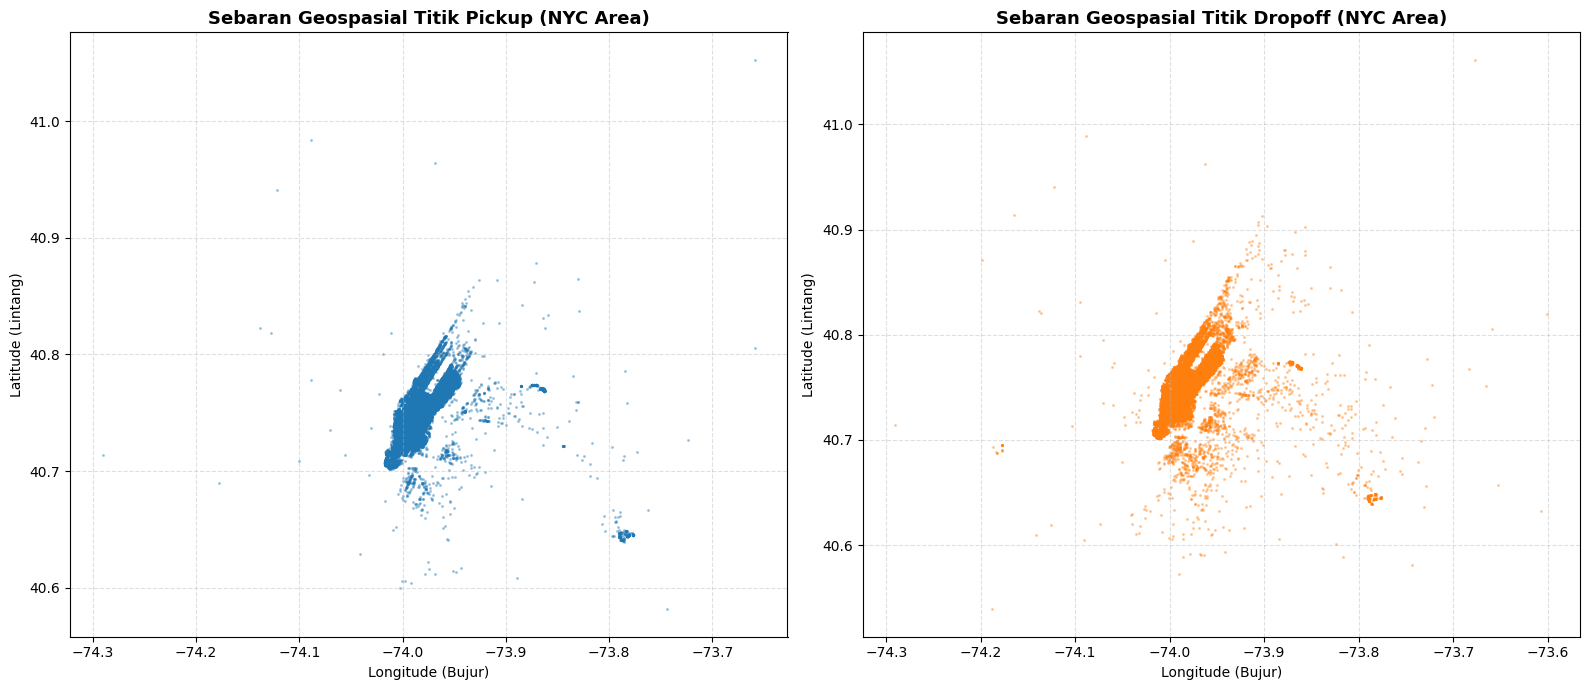

In [73]:
# [Verifikasi] Visualisasi Siluet Sebaran Koordinat NYC
# Mengambil sampel 15.000 titik agar visualisasi tajam dan render cepat
sample_vis = df.sample(n=min(15000, len(df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot Pickup
axes[0].scatter(sample_vis['pickup_longitude'], sample_vis['pickup_latitude'], s=1.5, alpha=0.3, color='#1f77b4')
axes[0].set_title('Sebaran Geospasial Titik Pickup (NYC Area)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Longitude (Bujur)')
axes[0].set_ylabel('Latitude (Lintang)')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot Dropoff
axes[1].scatter(sample_vis['dropoff_longitude'], sample_vis['dropoff_latitude'], s=1.5, alpha=0.3, color='#ff7f0e')
axes[1].set_title('Sebaran Geospasial Titik Dropoff (NYC Area)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Longitude (Bujur)')
axes[1].set_ylabel('Latitude (Lintang)')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 6. Deteksi Duplikasi

**Fokus:** Mengidentifikasi data ganda. Proses ini dibagi dua: 
1. Duplikasi Baris Total (semua nilai pada seluruh kolom sama persis).
2. Duplikasi Berdasarkan Identifier (contoh: satu ID transaksi memiliki dua baris data yang isinya berbeda di kolom lain).

In [74]:
# [Deteksi]
print(SEPARATOR)
print("DUPLIKASI BARIS TOTAL (EXACT MATCH)")
print(SEPARATOR)
duplikat_total = df.duplicated().sum()
persentase_duplikat = (duplikat_total / len(df)) * 100
print(f"Jumlah baris duplikat identik: {duplikat_total} baris ({persentase_duplikat:.2f}% dari keseluruhan data)")

if duplikat_total > 0:
    print("Cuplikan data duplikat (Exact Match):")
    display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(4))

DUPLIKASI BARIS TOTAL (EXACT MATCH)
Jumlah baris duplikat identik: 0 baris (0.00% dari keseluruhan data)


### *Penanganan: Penghapusan Duplikasi*
- Hapus kolom yang tidak digunakan, seperti kolom `key`, karena identifier transaksi sudah terstandarisasi menggunakan kolom `order_id` (hasil penggantian nama dari `Unnamed: 0` pada Bab 4).

In [75]:
# Daftar nilai yang duplikat di kolom tertentu
nilai_duplikat = df.loc[df['key'].duplicated(), 'key'].unique()
print(nilai_duplikat)

[]


In [76]:
# Daftar nilai yang duplikat pada kolom identifier (order_id)
nilai_duplikat = df.loc[df['order_id'].duplicated(), 'order_id'].unique()
print(f"Nilai duplikat pada order_id: {nilai_duplikat}")

Nilai duplikat pada order_id: []


In [77]:
# [Penanganan]
# 1. Hapus kolom 'key' (redundan dengan order_id dan pickup_datetime)
if 'key' in df.columns:
    df.drop(columns=['key'], inplace=True)
    print("[-] Kolom 'key' berhasil dihapus.")

print("\n", SEPARATOR)
print("INFORMASI STRUKTUR DATAFRAME TERBARU")
print(SEPARATOR)
df.info()

[-] Kolom 'key' berhasil dihapus.

INFORMASI STRUKTUR DATAFRAME TERBARU
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195745 entries, 0 to 195744
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   order_id           195745 non-null  object             
 1   fare_amount        195745 non-null  float64            
 2   pickup_datetime    195745 non-null  datetime64[ns, UTC]
 3   pickup_longitude   195745 non-null  float64            
 4   pickup_latitude    195745 non-null  float64            
 5   dropoff_longitude  195745 non-null  float64            
 6   dropoff_latitude   195745 non-null  float64            
 7   passenger_count    195745 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(1), object(1)
memory usage: 11.9+ MB


### *Hasil Observasi: Deteksi Duplikasi*

**Temuan Data:**
1. **Duplikasi Baris Penuh:** Ditemukan **0 baris duplikat identik (0.00%)**. Setiap catatan perjalanan bersifat unik.
2. **Penentuan Identifier:** Kolom `order_id` bersifat unik tanpa duplikasi. Kolom `key` memiliki fungsi yang redundan dan identik 100% dengan informasi tanggal pada `pickup_datetime`.

**Tindakan yang Dilakukan:**
Kolom `key` dihapus (*drop*) dari memori untuk menghindari redundansi fitur dan menghemat memori.

## 7. Identifikasi Missing Values

**Fokus:** Memetakan letak, jumlah, dan persentase nilai kosong (*Null/NaN*) pada setiap kolom. Proses ini akan menampilkan data dalam bentuk tabel rangkuman dan visualisasi *heatmap* untuk melihat pola kekosongan data.

In [78]:
# [Deteksi]
print(SEPARATOR)
print("RANGKUMAN MISSING VALUES")
print(SEPARATOR)

# 1. Pengecekan pada DataFrame aktif saat ini
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({'Total Missing': missing_values, 'Persentase (%)': missing_percentage})
display(missing_df)

# 2. Verifikasi 1 baris missing value pada data mentah awal (uber.csv)
raw_check = pd.read_csv('uber.csv')
display(raw_check[raw_check.isnull().any(axis=1)])
missing_values_raw = raw_check.isnull().sum()
missing_percentage = (missing_values_raw / len(df)) * 100

missing_df = pd.DataFrame({'Total Missing': missing_values_raw, 'Persentase (%)': missing_percentage})
display(missing_df)

RANGKUMAN MISSING VALUES


,Total Missing,Persentase (%)
order_id,0,0.0
fare_amount,0,0.0
pickup_datetime,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
passenger_count,0,0.0


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
87946,32736015,2013-07-02 03:51:57.0000001,24.1,2013-07-02 03:51:57 UTC,-73.950581,40.779692,NaN,NaN,0


,Total Missing,Persentase (%)
Unnamed: 0,0,0.000000
key,0,0.000000
fare_amount,0,0.000000
pickup_datetime,0,0.000000
pickup_longitude,0,0.000000
pickup_latitude,0,0.000000
dropoff_longitude,1,0.000511
dropoff_latitude,1,0.000511
passenger_count,0,0.000000


### *Hasil Observasi: Penanganan Missing Values*

Investigasi data membuktikan bahwa pada data mentah awal (`uber.csv`) **hanya terdapat tepat 1 baris missing value (0,0005%)**, yaitu pada transaksi indeks ke-87946 dengan nilai kosong (*NaN*) pada koordinat tujuan (`dropoff_longitude` dan `dropoff_latitude`).

Baris anomali tersebut **telah otomatis tereliminasi pada Bab 5 (Filtering Bounding Box NYC)**, karena evaluasi matematis koordinat *NaN* pada rentang batas wilayah menghasilkan nilai *False*. Hal ini menjelaskan mengapa deteksi missing value pada data aktif menghasilkan angka **0 baris kosong**.

## 8. Feature Engineering

**Fokus:**
Menciptakan fitur-fitur baru (*derived features*) dari data mentah geospasial dan waktu untuk meningkatkan kualitas analisis dan performa model prediksi:
1. **distance_km**: Jarak garis lengkung bumi antara koordinat penjemputan dan pengantaran (formula Haversine).
2. **Komponen Waktu**: Ekstraksi tanggal, hari, bulan, kuartal, tahun, jam, dan penanda AM/PM.
3. **pickup_area**: Kategorisasi wilayah penjemputan ke dalam 4 *borough* utama NYC (Manhattan, Queens, Brooklyn, Bronx, dan New Jersey).

### 8.1 Perhitungan Jarak Geospasial (`distance_km`)
Menghitung jarak garis lengkung permukaan bumi (*Great-Circle Distance*) dari titik penjemputan ke pengantaran menggunakan formula Haversine.

In [79]:
# [Feature Engineering] 8.1 Jarak Tempuh Haversine
def haversine_distance(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6371.0 * c
    return km

# Menghitung jarak tempuh garis lengkung bumi antara pickup dan dropoff
df['distance_km'] = haversine_distance(
    df['pickup_longitude'], df['pickup_latitude'],
    df['dropoff_longitude'], df['dropoff_latitude']
)
print("Fitur 'distance_km' berhasil dibuat menggunakan formula Haversine.")

Fitur 'distance_km' berhasil dibuat menggunakan formula Haversine.


### 8.2 Ekstraksi Tanggal & Waktu
Mendekomposisi kolom `pickup_datetime` menjadi unit-unit waktu yang lebih terperinci serta menambahkan indikator waktu `time_period` (AM/PM).

In [80]:
# Pastikan datetime menggunakan timezone UTC
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], utc=True
)

# Konversi UTC ke waktu lokal New York
df['pickup_datetime_ny'] = (
    df['pickup_datetime'].dt.tz_convert('America/New_York')
)

# Ekstraksi komponen waktu berdasarkan waktu lokal
df['day'] = df['pickup_datetime_ny'].dt.day
df['day_name'] = df['pickup_datetime_ny'].dt.day_name()
df['day_of_week'] = df['pickup_datetime_ny'].dt.dayofweek
df['month'] = df['pickup_datetime_ny'].dt.month
df['quarter'] = df['pickup_datetime_ny'].dt.quarter
df['year'] = df['pickup_datetime_ny'].dt.year
df['hour'] = df['pickup_datetime_ny'].dt.hour

# Indikator AM / PM
df['time_period'] = np.where(df['hour'] < 12, 'AM', 'PM')

# Validasi hasil
print("PERBANDINGAN UTC DAN WAKTU NEW YORK")

display(
    df[
        [
            'pickup_datetime',
            'pickup_datetime_ny',
            'day_name',
            'hour',
            'time_period'
        ]
    ].head()
)

print("\nTimezone:", df['pickup_datetime_ny'].dt.tz)
print("Missing datetime:", df['pickup_datetime_ny'].isna().sum())


PERBANDINGAN UTC DAN WAKTU NEW YORK


,pickup_datetime,pickup_datetime_ny,day_name,hour,time_period
0,2015-05-07 19:52:06+00:00,2015-05-07 15:52:06-04:00,Thursday,15,PM
1,2009-07-17 20:04:56+00:00,2009-07-17 16:04:56-04:00,Friday,16,PM
2,2009-08-24 21:45:00+00:00,2009-08-24 17:45:00-04:00,Monday,17,PM
3,2009-06-26 08:22:21+00:00,2009-06-26 04:22:21-04:00,Friday,4,AM
4,2014-08-28 17:47:00+00:00,2014-08-28 13:47:00-04:00,Thursday,13,PM



Timezone: America/New_York
Missing datetime: 0


### 8.3 Pengelompokan Wilayah Penjemputan (`pickup_area`) & Pengantaran (`dropoff_area`) NYC
Mengelompokkan lokasi penjemputan & pengantaran ke dalam 4 wilayah utama (*boroughs*) New York (Manhattan, Brooklyn, Queens, Bronx) berdasarkan koordinat geografisnya, serta 'New Jersey' untuk lokasi lainnya.

In [81]:
# Definisi estimasi bounding box setiap wilayah
area_bounds = {
    'Manhattan': (40.70, 40.88, -74.02, -73.93),
    'Brooklyn': (40.57, 40.739, -74.04, -73.86),
    'Queens': (40.54, 40.80, -73.93, -73.70),
    'Bronx': (40.80, 40.92, -73.93, -73.78)
}

# Fungsi klasifikasi wilayah
def classify_area(df, lat_col, lon_col):
    conditions = []
    choices = []

    for area, (lat_min, lat_max, lon_min, lon_max) in area_bounds.items():
        condition = (
            df[lat_col].between(lat_min, lat_max) &
            df[lon_col].between(lon_min, lon_max)
        )

        conditions.append(condition)
        choices.append(area)

    return np.select(
        conditions,
        choices,
        default='New Jersey'
    )

# A. Klasifikasi wilayah penjemputan
df['pickup_area'] = classify_area(
    df, 'pickup_latitude', 'pickup_longitude'
)

# B. Klasifikasi wilayah pengantaran
df['dropoff_area'] = classify_area(
    df, 'dropoff_latitude', 'dropoff_longitude'
)

# C. Distribusi wilayah
pickup_dist = df['pickup_area'].value_counts()
dropoff_dist = df['dropoff_area'].value_counts()

area_distribution = pd.DataFrame({
    'Pickup Count': pickup_dist,
    'Dropoff Count': dropoff_dist
}).fillna(0).astype(int)

area_distribution['Pickup (%)'] = (
    area_distribution['Pickup Count'] / len(df) * 100
).round(2)

area_distribution['Dropoff (%)'] = (
    area_distribution['Dropoff Count'] / len(df) * 100
).round(2)

print("DISTRIBUSI WILAYAH NYC")
display(area_distribution)

# D. Validasi hasil klasifikasi
print("\nVALIDASI KLASIFIKASI")
print("Total perjalanan:", len(df))
print("Total pickup:", area_distribution['Pickup Count'].sum())
print("Total dropoff:", area_distribution['Dropoff Count'].sum())
print("Missing pickup area:", df['pickup_area'].isna().sum())
print("Missing dropoff area:", df['dropoff_area'].isna().sum())


DISTRIBUSI WILAYAH NYC


,Pickup Count,Dropoff Count,Pickup (%),Dropoff (%)
Bronx,211,1206,0.11,0.62
Brooklyn,2800,7236,1.43,3.70
Manhattan,183717,178213,93.86,91.04
New Jersey,249,717,0.13,0.37
Queens,8768,8373,4.48,4.28



VALIDASI KLASIFIKASI
Total perjalanan: 195745
Total pickup: 195745
Total dropoff: 195745
Missing pickup area: 0
Missing dropoff area: 0



### Hasil Observasi: Klasifikasi Wilayah NYC

Berdasarkan klasifikasi terhadap 195.745 perjalanan, Manhattan mendominasi lokasi penjemputan sebesar 93,86% dan pengantaran sebesar 91,04%, diikuti Queens dan Brooklyn, sementara Bronx memiliki proporsi yang relatif kecil. Sebanyak 0,13% lokasi pickup. Seluruh perjalanan berhasil diklasifikasikan tanpa missing values. Hasil ini menunjukkan konsentrasi perjalanan pada wilayah yang diperkirakan sebagai Manhattan, sehingga wilayah tersebut layak menjadi fokus analisis permintaan. Namun, karena klasifikasi masih menggunakan bounding box, validasi geografis lebih lanjut diperlukan sebelum digunakan untuk keputusan operasional.


### 8.4 Pratinjau & Verifikasi Struktur Dataframe
Memeriksa struktur kolom baru dan memastikan seluruh fitur turunan telah terbentuk dengan benar tanpa nilai kosong (*null*).

In [82]:
# [Verifikasi] Cuplikan 5 Baris Dataframe dengan Fitur Baru
cols_baru = [
    'fare_amount', 'distance_km', 'pickup_area', 'time_period', 
    'day_name', 'month', 'year'
]

print(SEPARATOR)
print("CUPLIKAN FITUR-FITUR BARU")
print(SEPARATOR)
display(df[cols_baru].head())

print(SEPARATOR)
print("INFORMASI DIMENSI & KOLOM DATA TERBARU")
print(SEPARATOR)
print(f"Total Kolom Sekarang: {df.shape[1]} kolom")
print(f"Total Baris         : {df.shape[0]} baris")

CUPLIKAN FITUR-FITUR BARU


,fare_amount,distance_km,pickup_area,time_period,day_name,month,year
0,7.5,1.683323,Manhattan,PM,Thursday,5,2015
1,7.7,2.457590,Manhattan,PM,Friday,7,2009
2,12.9,5.036377,Manhattan,PM,Monday,8,2009
3,5.3,1.661683,Manhattan,AM,Friday,6,2009
4,16.0,4.475450,Queens,PM,Thursday,8,2014


INFORMASI DIMENSI & KOLOM DATA TERBARU
Total Kolom Sekarang: 20 kolom
Total Baris         : 195745 baris


## 9. Encoding Fitur Kategorikal

**Fokus:**
Mengonversi fitur-fitur kategorikal nominal (`pickup_area`, `dropoff_area`, `day_name`, `time_period`) ke dalam representasi numerik biner menggunakan teknik **One-Hot Encoding (OHE)**.

*Catatan Penting:* Proses encoding ini dilakukan pada salinan data khusus (`df_encoded`) agar dataframe utama (`df`) tetap mempertahankan format teks aslinya sehingga label kategori pada visualisasi grafik EDA nantinya tetap ramah dibaca manusia (*human-readable*).

In [83]:
# [Encoding]
print(SEPARATOR)
print("ENCODING FITUR KATEGORIKAL (ONE-HOT ENCODING)")
print(SEPARATOR)

# 1. Menentukan kolom-kolom kategorikal nominal yang akan di-encode
kolom_kategorikal = ['pickup_area', 'dropoff_area', 'day_name', 'time_period']

# 2. Menerapkan One-Hot Encoding dengan pd.get_dummies()
# Parameter drop_first=True diterapkan untuk mencegah multikolinearitas (dummy variable trap)
df_encoded = pd.get_dummies(df, columns=kolom_kategorikal, drop_first=True, dtype=int)

# Menghapus kolom identifier agar tidak ikut terbaca dalam pemodelan numerik
if 'key' in df_encoded.columns:
    df_encoded.drop(columns=['key'], inplace=True)

# 3. Mengidentifikasi dan menampilkan cuplikan kolom-kolom biner yang baru terbentuk
kolom_dummy = [col for col in df_encoded.columns if any(kat in col for kat in kolom_kategorikal)]
print(f"[+] Berhasil membuat {len(kolom_dummy)} kolom biner One-Hot Encoding dari {len(kolom_kategorikal)} fitur kategorikal.")
print("\nCuplikan 5 Baris Data Hasil One-Hot Encoding:")
display(df_encoded[kolom_dummy].head())

ENCODING FITUR KATEGORIKAL (ONE-HOT ENCODING)
[+] Berhasil membuat 15 kolom biner One-Hot Encoding dari 4 fitur kategorikal.

Cuplikan 5 Baris Data Hasil One-Hot Encoding:


,pickup_area_Brooklyn,pickup_area_Manhattan,pickup_area_New Jersey,pickup_area_Queens,dropoff_area_Brooklyn,dropoff_area_Manhattan,dropoff_area_New Jersey,dropoff_area_Queens,day_name_Monday,day_name_Saturday,day_name_Sunday,day_name_Thursday,day_name_Tuesday,day_name_Wednesday,time_period_PM
0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1
1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1
2,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1
3,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,1,0,0,0,0,0,1,0,0,1


### *Hasil Observasi: Encoding Fitur Kategorikal (One-Hot Encoding)*

Sebanyak 4 fitur kategorikal nominal (`pickup_area`, `dropoff_area`, `day_name`, dan `time_period`) berhasil ditransformasikan menggunakan teknik **One-Hot Encoding (OHE)** menjadi **15 kolom biner baru (nilai 0 atau 1)** dengan parameter `drop_first=True`. Parameter ini krusial untuk mencegah terjadinya **jebakan variabel dummy (multicollinearity trap)** pada model regresi linier.

Penerapan One-Hot Encoding ini menjamin bahwa **seluruh kategori nominal diperlakukan setara tanpa adanya asumsi hierarki matematis palsu**, sehingga korelasi Pearson dan bobot koefisien Machine Learning nantinya dapat merefleksikan kontribusi masing-masing kategori secara independen dan akurat.

Seluruh kolom biner ini disimpan khusus pada dataframe `df_encoded` untuk kebutuhan korelasi dan pemodelan, sedangkan dataframe utama `df` tetap mempertahankan label teks aslinya agar visualisasi grafik EDA tetap komunikatif dan mudah dipahami.

## 10. Deteksi Outlier, Distribusi & Uji Normalitas

**Fokus:** 
1. Mengidentifikasi nilai ekstrem (outlier) pada data numerik menggunakan metode Interquartile Range (IQR).
2. Memvisualisasikan distribusi data (Histogram/Boxplot).
3. Melakukan uji normalitas jika data direncanakan untuk analisis statistik parametrik (seperti uji t atau ANOVA).

DETEKSI OUTLIER (METODE IQR), DISTRIBUSI & UJI NORMALITAS (NUMERIK MURNI)
[+] Memeriksa 13 kolom numerik kontinu:
['fare_amount', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'distance_km', 'day', 'day_of_week', 'month', 'quarter', 'year', 'hour']


--- Kolom: 'fare_amount' ---
Batas Bawah (Lower Bound) : -3.75
Batas Atas (Upper Bound)  : 22.25
Jumlah Outlier            : 16,717 baris (8.54%)
Uji Kolmogorov-Smirnov   : Stat = 0.2049, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


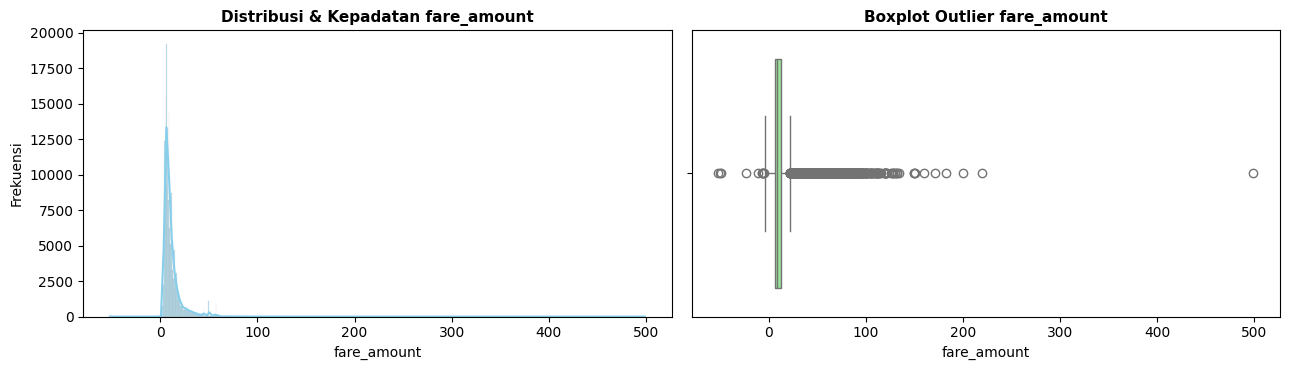


--- Kolom: 'pickup_longitude' ---
Batas Bawah (Lower Bound) : -74.03
Batas Atas (Upper Bound)  : -73.93
Jumlah Outlier            : 9,619 baris (4.91%)
Uji Kolmogorov-Smirnov   : Stat = 0.1717, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


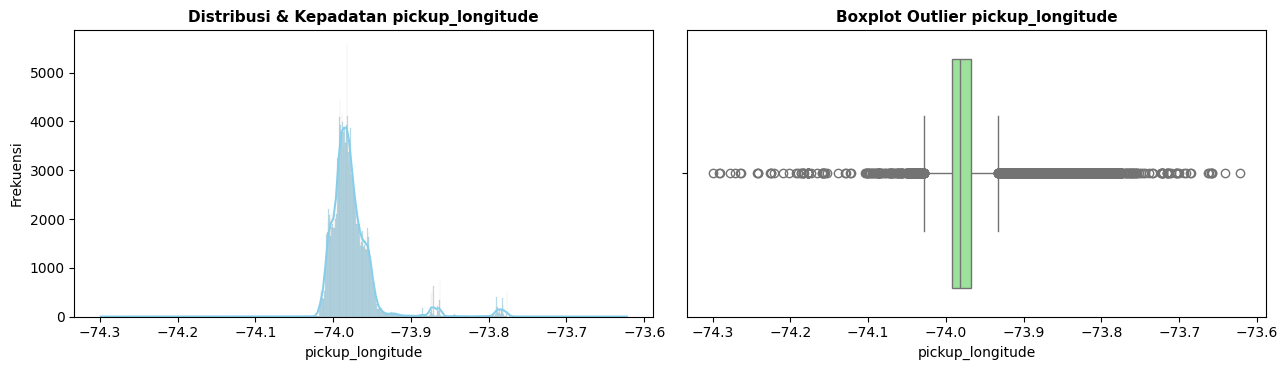


--- Kolom: 'pickup_latitude' ---
Batas Bawah (Lower Bound) : 40.69
Batas Atas (Upper Bound)  : 40.81
Jumlah Outlier            : 5,883 baris (3.01%)
Uji Kolmogorov-Smirnov   : Stat = 0.0538, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


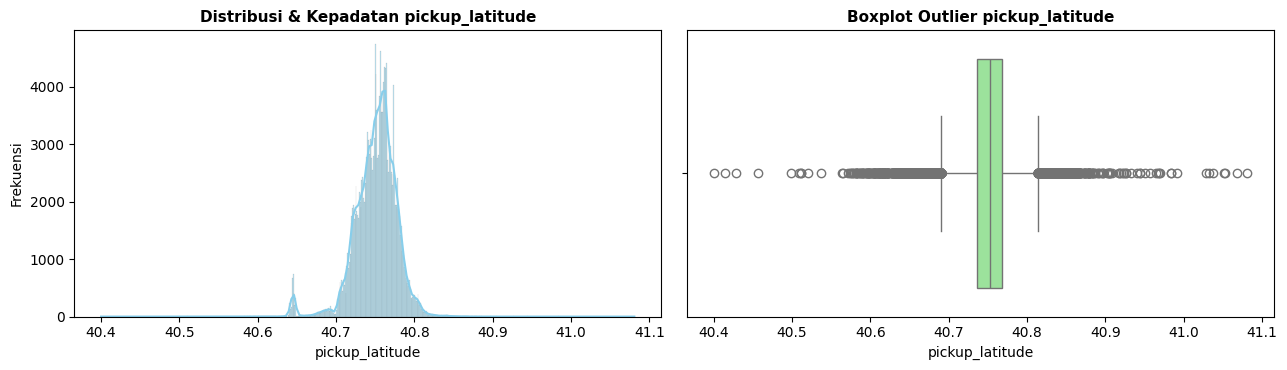


--- Kolom: 'dropoff_longitude' ---
Batas Bawah (Lower Bound) : -74.03
Batas Atas (Upper Bound)  : -73.93
Jumlah Outlier            : 10,833 baris (5.53%)
Uji Kolmogorov-Smirnov   : Stat = 0.1494, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


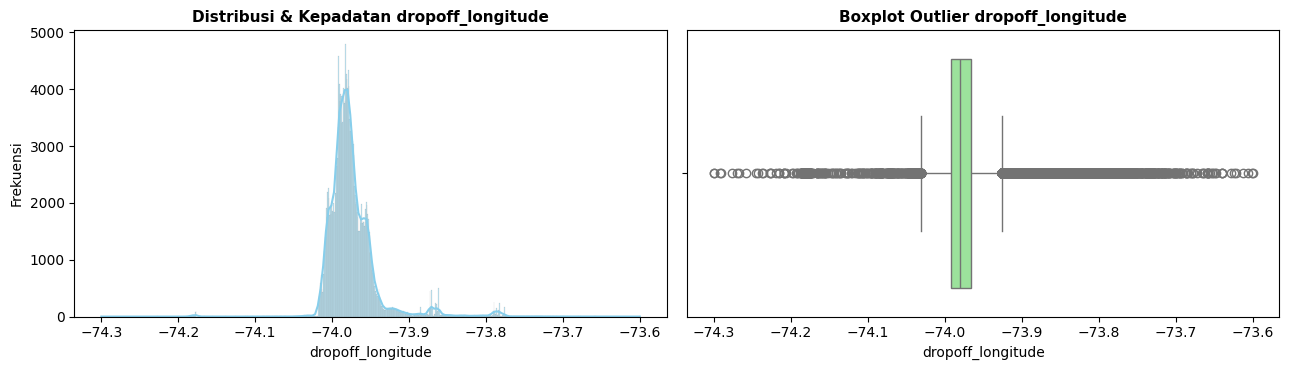


--- Kolom: 'dropoff_latitude' ---
Batas Bawah (Lower Bound) : 40.69
Batas Atas (Upper Bound)  : 40.82
Jumlah Outlier            : 8,810 baris (4.50%)
Uji Kolmogorov-Smirnov   : Stat = 0.0625, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


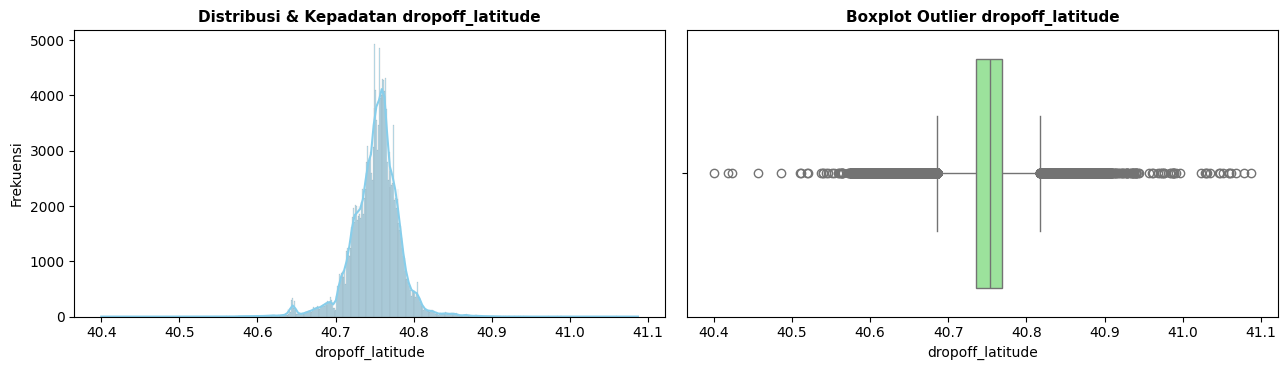


--- Kolom: 'passenger_count' ---
Batas Bawah (Lower Bound) : -0.50
Batas Atas (Upper Bound)  : 3.50
Jumlah Outlier            : 22,104 baris (11.29%)
Uji Kolmogorov-Smirnov   : Stat = 0.3847, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


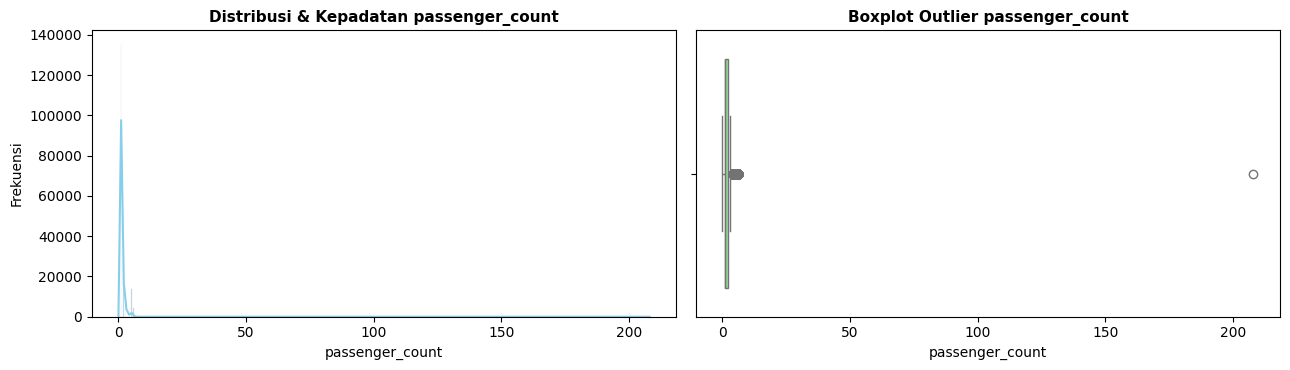


--- Kolom: 'distance_km' ---
Batas Bawah (Lower Bound) : -2.72
Batas Atas (Upper Bound)  : 7.88
Jumlah Outlier            : 16,179 baris (8.27%)
Uji Kolmogorov-Smirnov   : Stat = 0.1916, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


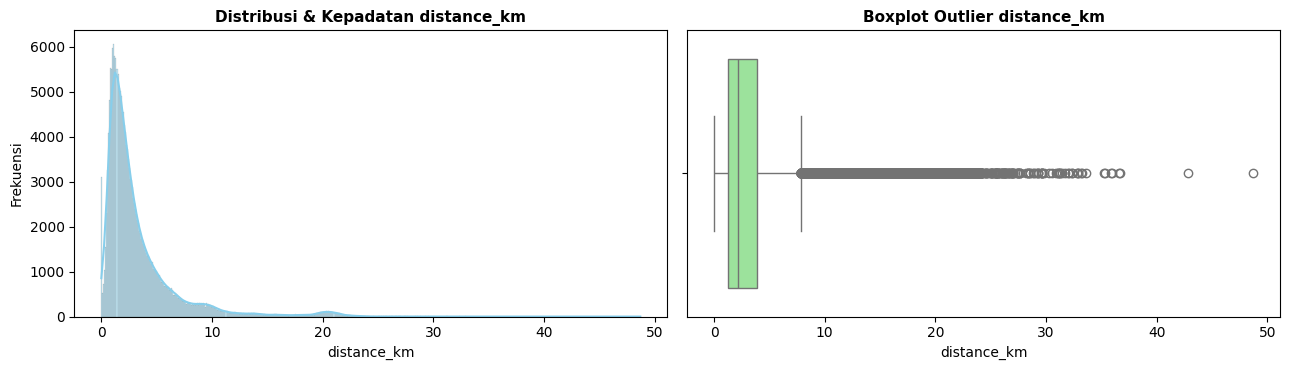


--- Kolom: 'day' ---
Batas Bawah (Lower Bound) : -14.50
Batas Atas (Upper Bound)  : 45.50
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.0718, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


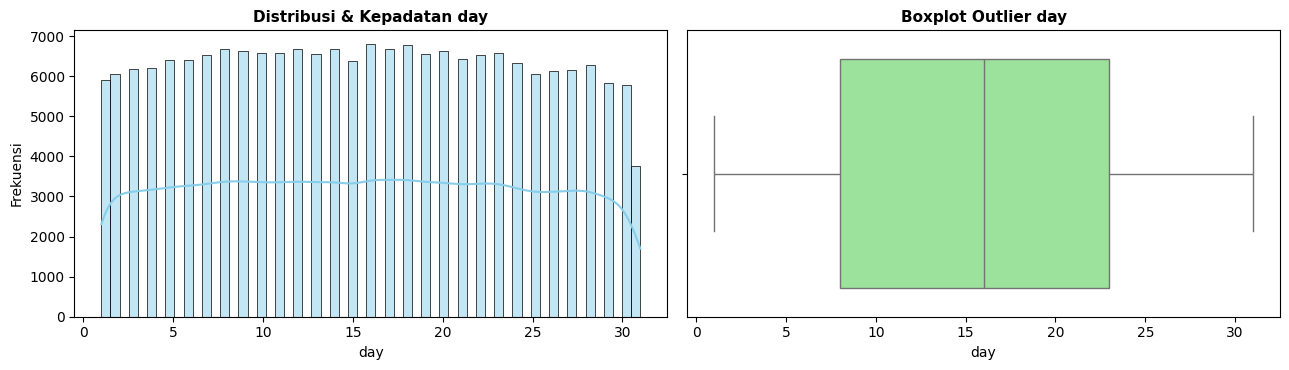


--- Kolom: 'day_of_week' ---
Batas Bawah (Lower Bound) : -5.00
Batas Atas (Upper Bound)  : 11.00
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.1315, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


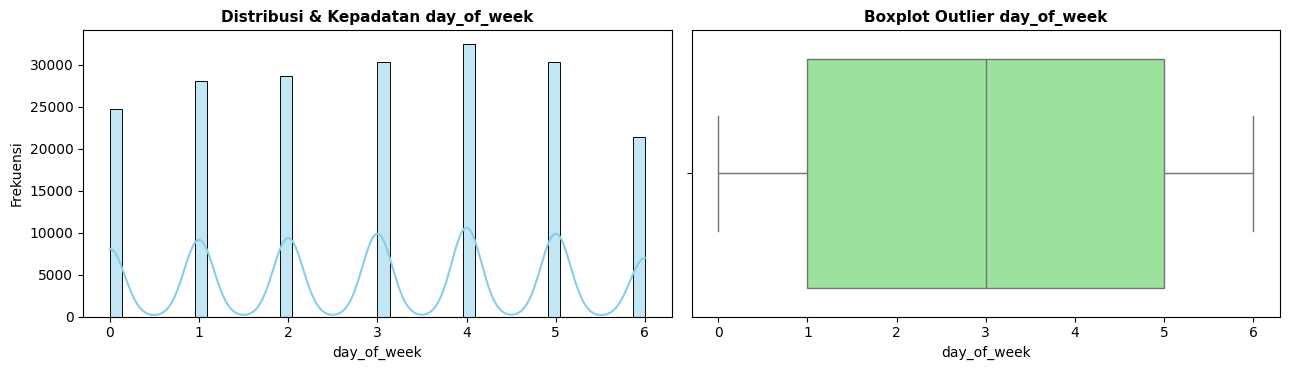


--- Kolom: 'month' ---
Batas Bawah (Lower Bound) : -6.00
Batas Atas (Upper Bound)  : 18.00
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.1052, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


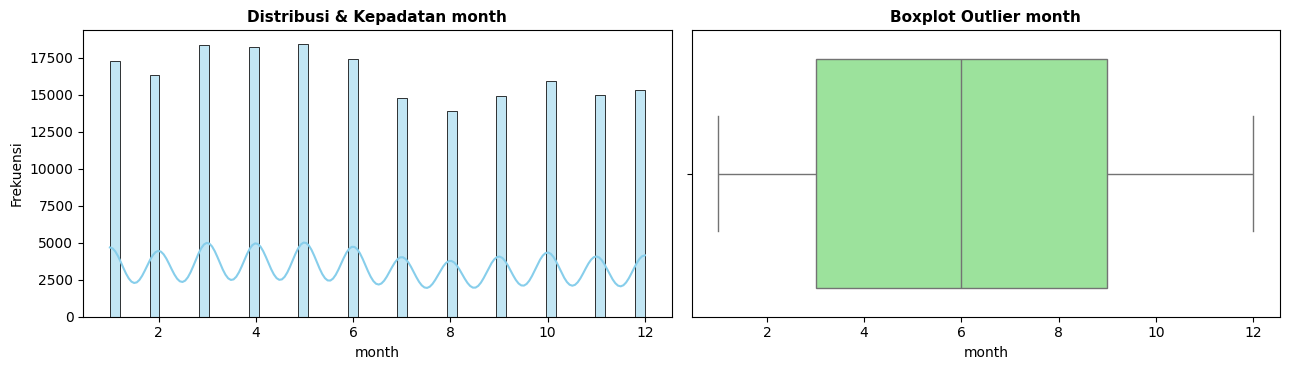


--- Kolom: 'quarter' ---
Batas Bawah (Lower Bound) : -2.00
Batas Atas (Upper Bound)  : 6.00
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.1910, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


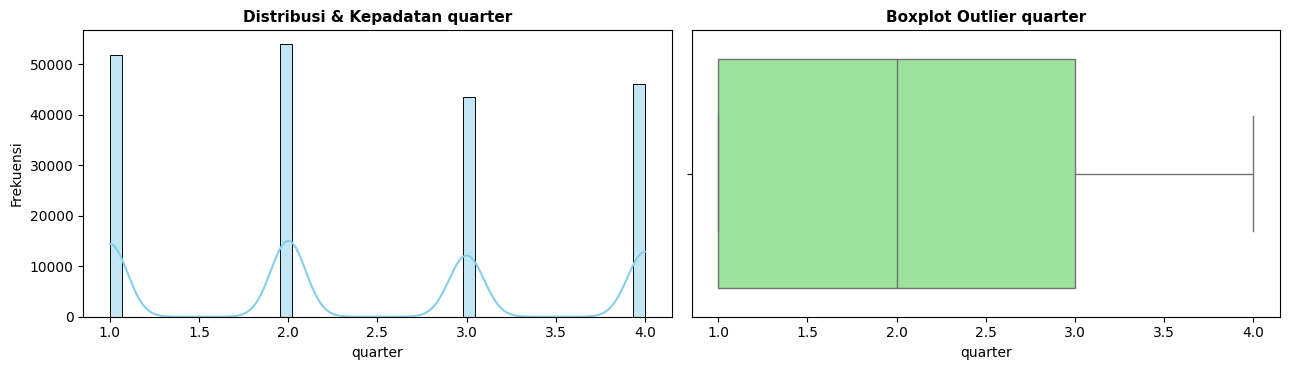


--- Kolom: 'year' ---
Batas Bawah (Lower Bound) : 2005.50
Batas Atas (Upper Bound)  : 2017.50
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.1300, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


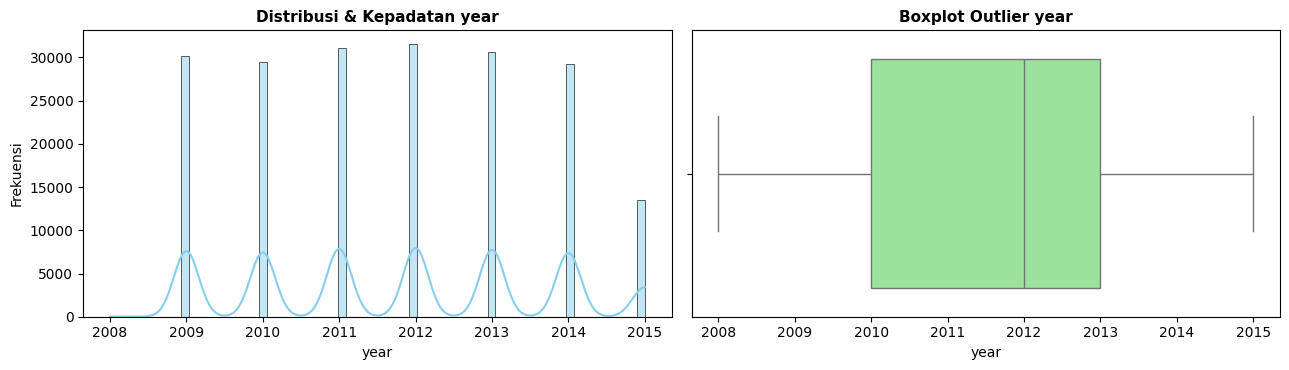


--- Kolom: 'hour' ---
Batas Bawah (Lower Bound) : -8.00
Batas Atas (Upper Bound)  : 32.00
Jumlah Outlier            : 0 baris (0.00%)
Uji Kolmogorov-Smirnov   : Stat = 0.0798, p-value = 0.0000e+00
Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)


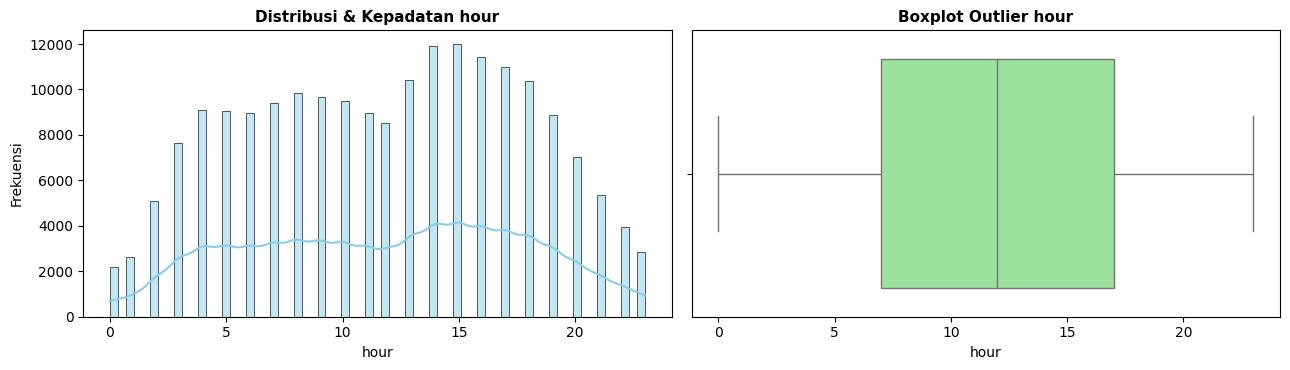

In [84]:
# [Deteksi]
print(SEPARATOR)
print("DETEKSI OUTLIER (METODE IQR), DISTRIBUSI & UJI NORMALITAS (NUMERIK MURNI)")
print(SEPARATOR)

# 1. Mengambil kolom numerik kontinu murni (mengabaikan kolom ID dan kolom biner dummy 0/1)
kolom_dummy = [col for col in df_encoded.columns if any(k in col for k in ['area_', 'day_name_', 'time_period_'])]
exclude_cols = ['Unnamed: 0', 'key', 'order_id'] + kolom_dummy
num_cols = [col for col in df_encoded.select_dtypes(include=[np.number]).columns if col not in exclude_cols]

if len(num_cols) == 0:
    print("Tidak ada kolom numerik dalam dataset.")
else:
    print(f"[+] Memeriksa {len(num_cols)} kolom numerik kontinu:\n{num_cols}\n")
    
    for col in num_cols:
        # a. Perhitungan IQR & Outlier
        Q1 = df_encoded[col].quantile(0.25)
        Q3 = df_encoded[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df_encoded[(df_encoded[col] < lower_bound) | (df_encoded[col] > upper_bound)][col]
        num_outliers = len(outliers)
        pct_outliers = (num_outliers / len(df_encoded)) * 100

        print(f"\n" + "="*50)
        print(f"--- Kolom: '{col}' ---")
        print(f"="*50)
        print(f"Batas Bawah (Lower Bound) : {lower_bound:.2f}")
        print(f"Batas Atas (Upper Bound)  : {upper_bound:.2f}")
        print(f"Jumlah Outlier            : {num_outliers:,} baris ({pct_outliers:.2f}%)")

        # b. Uji Normalitas: Kolmogorov-Smirnov (KS-Test)
        data_clean = df_encoded[col].dropna()

        if len(data_clean) >= 3 and data_clean.std() > 0:
            data_std = (data_clean - data_clean.mean()) / data_clean.std()
            stat, p = kstest(data_std, 'norm')
            print(f"Uji Kolmogorov-Smirnov   : Stat = {stat:.4f}, p-value = {p:.4e}")
            if p > 0.05:
                print("Distribusi               : Normal (Gagal menolak H0, p > 0.05)")
            else:
                print("Distribusi               : Tidak Normal / Skewed (Menolak H0, p <= 0.05)")
        else:
            print("Uji Kolmogorov-Smirnov   : Dilewati (Sampel konstan atau kurang variasi).")

        # c. Visualisasi (Histogram + KDE & Boxplot)
        fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

        # Histogram + KDE
        sns.histplot(df_encoded[col], kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Distribusi & Kepadatan {col}', fontsize=11, fontweight='bold')
        axes[0].set_xlabel(col)
        axes[0].set_ylabel('Frekuensi')

        # Boxplot
        sns.boxplot(x=df_encoded[col], ax=axes[1], color='lightgreen')
        axes[1].set_title(f'Boxplot Outlier {col}', fontsize=11, fontweight='bold')
        axes[1].set_xlabel(col)

        plt.tight_layout()
        plt.show()

### *Penanganan: Outlier*

In [85]:
print(SEPARATOR)
print("ANOMALI PASSENGER_COUNT")
print(SEPARATOR)

df[(df['passenger_count'] == 0)]

ANOMALI PASSENGER_COUNT


,order_id,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,pickup_datetime_ny,day,day_name,day_of_week,month,quarter,year,hour,time_period,pickup_area,dropoff_area
324,2137942,10.1,2011-08-05 07:03:08+00:00,-74.013900,40.707800,-73.992300,40.749300,0,4.960570,2011-08-05 03:03:08-04:00,5,Friday,4,8,3,2011,3,AM,Manhattan,Manhattan
889,8484351,11.7,2011-09-06 12:25:19+00:00,-73.981000,40.764600,-73.962900,40.778400,0,2.162835,2011-09-06 08:25:19-04:00,6,Tuesday,1,9,3,2011,8,AM,Manhattan,Manhattan
907,32941306,3.3,2012-03-26 18:11:24+00:00,-73.979978,40.765821,-73.983894,40.766873,0,0.349924,2012-03-26 14:11:24-04:00,26,Monday,0,3,1,2012,14,PM,Manhattan,Manhattan
1952,12591041,15.7,2012-04-20 15:07:57+00:00,-73.975285,40.750138,-73.974729,40.783151,0,3.671177,2012-04-20 11:07:57-04:00,20,Friday,4,4,2,2012,11,AM,Manhattan,Manhattan
2949,39400625,6.1,2012-01-07 19:19:08+00:00,-73.977900,40.789100,-73.983700,40.773600,0,1.791370,2012-01-07 14:19:08-05:00,7,Saturday,5,1,1,2012,14,PM,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192401,42421017,5.7,2011-04-14 18:21:00+00:00,-73.981165,40.744772,-73.994190,40.743725,0,1.103446,2011-04-14 14:21:00-04:00,14,Thursday,3,4,2,2011,14,PM,Manhattan,Manhattan
192618,26965490,3.3,2011-01-17 15:52:26+00:00,-74.000760,40.757637,-74.004852,40.751947,0,0.720492,2011-01-17 10:52:26-05:00,17,Monday,0,1,1,2011,10,AM,Manhattan,Manhattan
194641,12988511,5.7,2011-09-20 19:55:05+00:00,-73.980300,40.742800,-73.967900,40.755600,0,1.765465,2011-09-20 15:55:05-04:00,20,Tuesday,1,9,3,2011,15,PM,Manhattan,Manhattan
194671,54393172,12.1,2011-08-22 21:10:56+00:00,-73.996700,40.737200,-74.008500,40.704000,0,3.823264,2011-08-22 17:10:56-04:00,22,Monday,0,8,3,2011,17,PM,Manhattan,Manhattan


In [86]:
print(SEPARATOR)
print("ANOMALI DISTANCE_KM")
print(SEPARATOR)

df[df['distance_km'] == 0]

ANOMALI DISTANCE_KM


,order_id,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,pickup_datetime_ny,day,day_name,day_of_week,month,quarter,year,hour,time_period,pickup_area,dropoff_area
5,44470845,4.90,2011-02-12 02:27:09+00:00,-73.969019,40.755910,-73.969019,40.755910,1,0.0,2011-02-11 21:27:09-05:00,11,Friday,4,2,1,2011,21,PM,Manhattan,Manhattan
46,22405517,56.80,2013-01-03 22:24:41+00:00,-73.993498,40.764686,-73.993498,40.764686,1,0.0,2013-01-03 17:24:41-05:00,3,Thursday,3,1,1,2013,17,PM,Manhattan,Manhattan
81,25485719,49.57,2009-08-07 10:43:07+00:00,-73.975058,40.788820,-73.975058,40.788820,1,0.0,2009-08-07 06:43:07-04:00,7,Friday,4,8,3,2009,6,AM,Manhattan,Manhattan
160,54642873,4.50,2014-01-22 21:01:18+00:00,-73.992937,40.757780,-73.992937,40.757780,1,0.0,2014-01-22 16:01:18-05:00,22,Wednesday,2,1,1,2014,16,PM,Manhattan,Manhattan
351,11876316,10.10,2009-08-24 17:25:00+00:00,-73.928705,40.753475,-73.928705,40.753475,1,0.0,2009-08-24 13:25:00-04:00,24,Monday,0,8,3,2009,13,PM,Queens,Queens
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195207,42657809,5.70,2010-07-24 21:16:00+00:00,-73.924907,40.745833,-73.924907,40.745833,3,0.0,2010-07-24 17:16:00-04:00,24,Saturday,5,7,3,2010,17,PM,Queens,Queens
195370,11772885,4.50,2013-02-17 11:27:00+00:00,-73.969717,40.765832,-73.969717,40.765832,3,0.0,2013-02-17 06:27:00-05:00,17,Sunday,6,2,1,2013,6,AM,Manhattan,Manhattan
195401,32051586,2.50,2009-06-07 02:07:26+00:00,-73.956623,40.771633,-73.956623,40.771633,1,0.0,2009-06-06 22:07:26-04:00,6,Saturday,5,6,2,2009,22,PM,Manhattan,Manhattan
195664,45368488,4.50,2013-06-24 22:17:43+00:00,-73.793768,40.656939,-73.793768,40.656939,1,0.0,2013-06-24 18:17:43-04:00,24,Monday,0,6,2,2013,18,PM,Queens,Queens


In [87]:
df[df['passenger_count'] > 100]

,order_id,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,pickup_datetime_ny,day,day_name,day_of_week,month,quarter,year,hour,time_period,pickup_area,dropoff_area
110599,35893772,11.7,2010-12-28 08:20:00+00:00,-73.937795,40.758498,-73.937835,40.758415,208,0.009825,2010-12-28 03:20:00-05:00,28,Tuesday,1,12,4,2010,3,AM,Manhattan,Manhattan


In [88]:
print(SEPARATOR)
print("ANOMALI FARE_AMOUNT")
print(SEPARATOR)


len(df[df['fare_amount'] < 0])

ANOMALI FARE_AMOUNT


16

In [89]:
df[df['fare_amount'] == 0]

,order_id,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,pickup_datetime_ny,day,day_name,day_of_week,month,quarter,year,hour,time_period,pickup_area,dropoff_area
20326,25344154,0.0,2015-04-22 23:25:07+00:00,-73.658897,40.805199,-73.658897,40.805199,1,0.000000,2015-04-22 19:25:07-04:00,22,Wednesday,2,4,2,2015,19,PM,New Jersey,New Jersey
21736,22994576,0.0,2010-03-20 02:59:51+00:00,-73.994366,40.755395,-73.998718,40.854853,2,11.065289,2010-03-19 22:59:51-04:00,19,Friday,4,3,1,2010,22,PM,Manhattan,Manhattan
153399,36776406,0.0,2015-02-17 08:48:08+00:00,-73.937714,40.758541,-73.937721,40.758541,1,0.000643,2015-02-17 03:48:08-05:00,17,Tuesday,1,2,1,2015,3,AM,Manhattan,Manhattan


In [90]:
df[df['fare_amount'] > 200]

,order_id,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,pickup_datetime_ny,day,day_name,day_of_week,month,quarter,year,hour,time_period,pickup_area,dropoff_area
28670,5471406,220.0,2013-09-27 12:36:11+00:00,-73.801147,40.671653,-73.790402,40.646742,1,2.914493,2013-09-27 08:36:11-04:00,27,Friday,4,9,3,2013,8,AM,Queens,Queens
166442,51151143,499.0,2011-04-10 04:10:00+00:00,-73.968377,40.764602,-73.968368,40.764600,1,0.000790,2011-04-10 00:10:00-04:00,10,Sunday,6,4,2,2011,0,AM,Manhattan,Manhattan


In [91]:
# [Penanganan] Pembersihan Outlier Sesuai Logika Domain
baris_awal = len(df)

# Kriteria:
# 1. passenger_count minimal 0 (layanan pengiriman barang Uber Courier) dan maksimal 6 (UberXL)
# 2. fare_amount dan distance_km harus lebih dari 0 (> 0, membuang nilai minus dan $0 / 0 km)
# 3. fare_amount < 499 (menghapus anomali $499 yang tidak logis dengan jarak tempuhnya cuman ~0.00 km)
kondisi_valid = (
    (df['passenger_count'] >= 0) & 
    (df['passenger_count'] <= 6) & 
    (df['distance_km'] > 0) & 
    (df['fare_amount'] > 0) & 
    (df['fare_amount'] < 499)
)

# Eksekusi pembersihan serentak pada df dan df_encoded
baris_dihapus = (~kondisi_valid).sum()
df = df[kondisi_valid].reset_index(drop=True)
df_encoded = df_encoded[kondisi_valid].reset_index(drop=True)
baris_akhir = len(df)

print(SEPARATOR)
print("RINGKASAN PENANGANAN OUTLIER PASSENGER_COUNT, DISTANCE_KM & FARE_AMOUNT")
print(SEPARATOR)
print(f"Jumlah baris sebelum filtering : {baris_awal} baris")
print(f"Jumlah baris anomali dibuang   : {baris_dihapus} baris")
print(f"Sisa baris data bersih         : {baris_akhir} baris")

RINGKASAN PENANGANAN OUTLIER PASSENGER_COUNT, DISTANCE_KM & FARE_AMOUNT
Jumlah baris sebelum filtering : 195745 baris
Jumlah baris anomali dibuang   : 1990 baris
Sisa baris data bersih         : 193755 baris


In [92]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,day,day_of_week,month,quarter,year,hour
count,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000,193755.000000
mean,11.323193,-73.975606,40.750845,-73.974645,40.751154,1.683998,3.347702,15.725483,2.991102,6.286202,2.429109,2011.744879,11.812077
std,9.517261,0.034420,0.026969,0.034205,0.030877,1.307235,3.580932,8.687586,1.903185,3.441031,1.116987,1.860134,5.843855
min,0.010000,-74.299012,40.400072,-74.299833,40.400050,0.000000,0.000084,1.000000,0.000000,1.000000,1.000000,2008.000000,0.000000
25%,6.000000,-73.992287,40.736489,-73.991605,40.735371,1.000000,1.280550,8.000000,1.000000,3.000000,1.000000,2010.000000,7.000000
50%,8.500000,-73.982138,40.753314,-73.980583,40.753761,1.000000,2.179906,16.000000,3.000000,6.000000,2.000000,2012.000000,12.000000
75%,12.500000,-73.968509,40.767544,-73.965600,40.768331,2.000000,3.936206,23.000000,5.000000,9.000000,3.000000,2013.000000,17.000000
max,220.000000,-73.622390,41.080965,-73.600327,41.087056,6.000000,48.706330,31.000000,6.000000,12.000000,4.000000,2015.000000,23.000000


### *Hasil Observasi: Deteksi Outlier & Uji Normalitas*

Uji normalitas **Kolmogorov-Smirnov (KS-Test)** pada seluruh variabel kontinu utama (`fare_amount`, `distance_km`, `passenger_count`, dan koordinat) menghasilkan nilai **p-value = 0.0000 (p < 0.05)**, yang secara formal membuktikan bahwa **data tidak berdistribusi normal**. Seluruh kolom biner One-Hot Encoding secara tepat dikecualikan dari pengujian ini karena sifat datanya yang diskrit (0 atau 1).

Deteksi nilai ekstrem mengidentifikasi anomali operasional nyata, seperti **tarif bernilai minus dan $0**, tarif ekstrem **$499 dengan jarak 0 km**, serta catatan **kapasitas penumpang di atas 100 orang**. Seluruh anomali ini dibersihkan menggunakan kriteria domain bisnis transportasi: membatasi penumpang pada rentang **0 hingga 6 orang** (Uber Courier s/d UberXL), tarif **$0 < fare < $499**, dan jarak **> 0 km**.

Proses filtering berhasil mengeliminasi 1.990 baris data anomali dari total 195.745 baris, sehingga menghasilkan dataset akhir sebanyak 193.755 baris yang siap digunakan dalam analisis berikutnya. Jumlah ini konsisten dengan hasil validasi Data Cleaning dan agregasi time series.

## 11. Exploratory Data Analysis (EDA)

**Pertanyaan utama:** mengapa total fare harian layak dianalisis lebih lanjut untuk perkiraan periode berikutnya?


### 11.1 Profil Distribusi Transaksi (Univariat)

**Pertanyaan:** seperti apa sebaran tarif, jarak, jumlah penumpang, serta fitur transaksi lainnya setelah data dibersihkan?

Visualisasi histogram membantu mengidentifikasi konsentrasi transaksi, kemencengan distribusi, dan perbedaan skala antarvariabel.


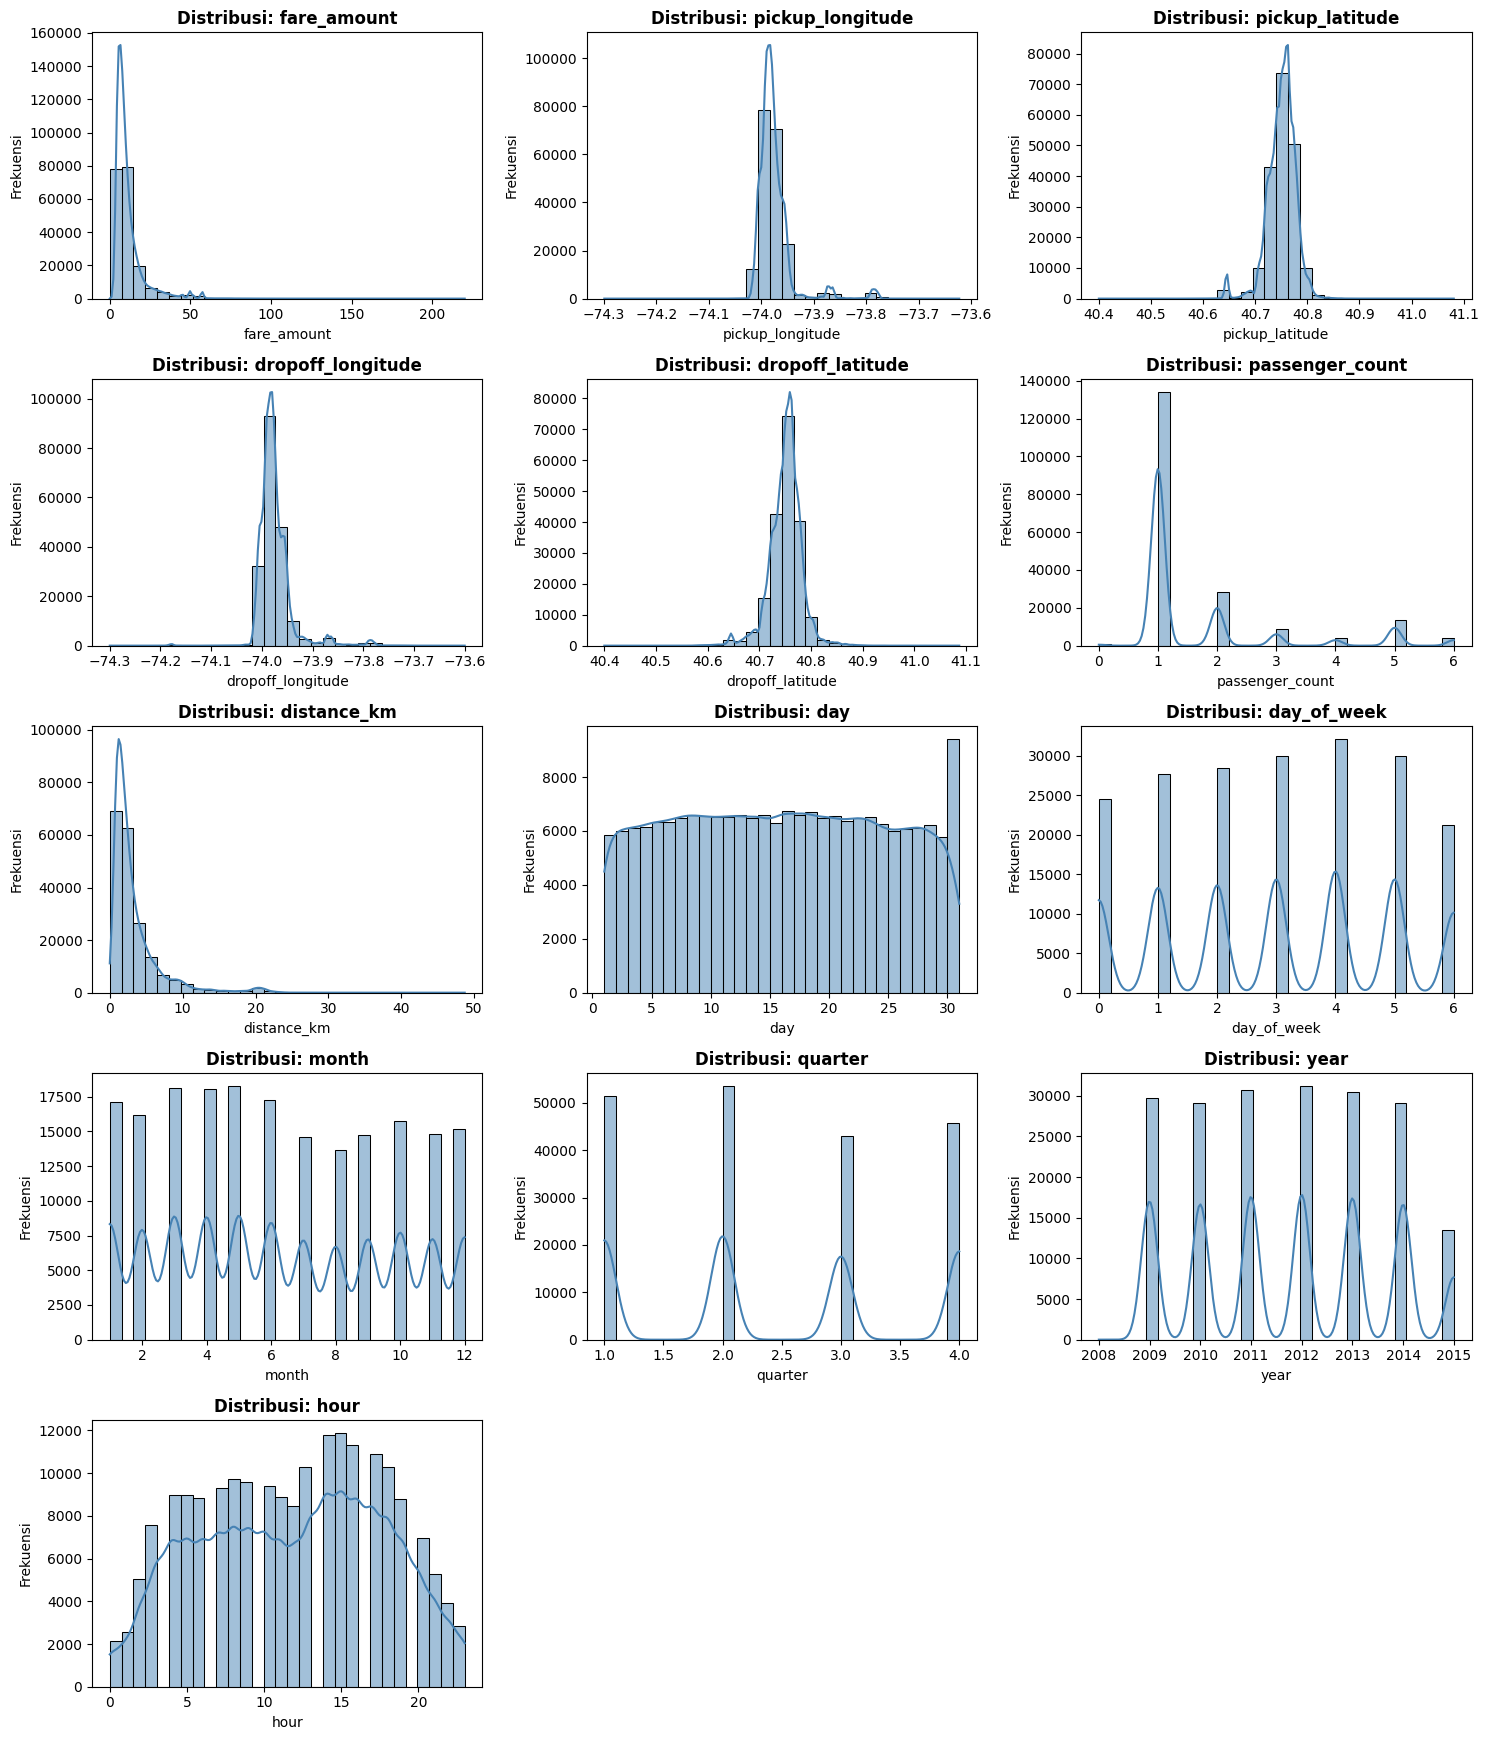

In [93]:
num_cols = [col for col in df.select_dtypes(include=np.number).columns if 'id' not in col.lower()]

# Buat grid subplot (3 kolom per baris)
n_cols = 3
n_rows = (len(num_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=30, color='steelblue', ax=axes[i])
    axes[i].set_title(f'Distribusi: {col}', fontweight='bold')
    axes[i].set_ylabel('Frekuensi')

# Hapus subplot kosong jika ada sisa grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Key Insight

Sebaran `fare_amount` dan `distance_km` cenderung condong ke kanan: sebagian besar perjalanan tercatat dengan tarif dan jarak relatif rendah, sementara sebagian kecil berada pada nilai lebih tinggi. Jumlah penumpang juga didominasi perjalanan dengan sedikit penumpang. Pola ini menggambarkan karakteristik transaksi dalam sampel, tetapi belum menjelaskan bagaimana *total fare* berubah dari hari ke hari. Oleh karena itu, hubungan tarif dengan jarak dan faktor lain perlu diperiksa terlebih dahulu sebelum data diringkas menjadi tingkat harian.


### 11.2 Hubungan Jarak Perjalanan dan Fare Amount

**Pertanyaan:** apakah perjalanan yang lebih jauh cenderung memiliki tarif yang lebih tinggi?

Scatter plot menampilkan sampel transaksi pada rentang hingga persentil ke-99 untuk menjaga keterbacaan. **Korelasi dihitung dari seluruh transaksi bersih sebelum pembatasan visualisasi**.


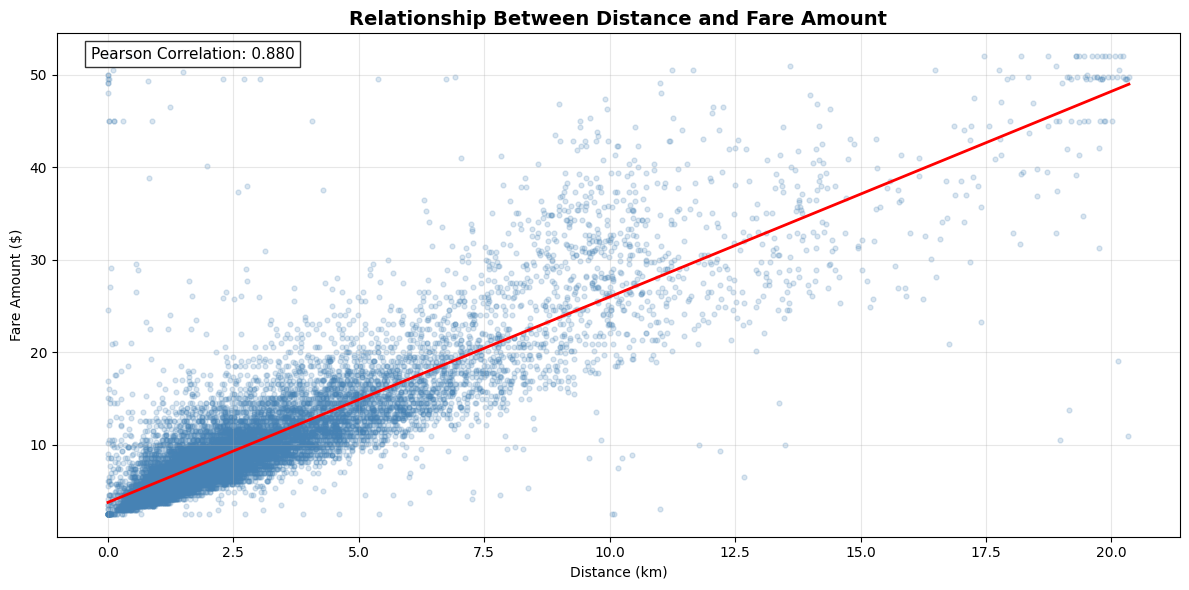

Pearson Correlation: 0.8799


In [94]:
# 1. Menyiapkan data jarak dan tarif perjalanan
plot_df = df[['distance_km', 'fare_amount']].dropna().copy()

# 2. Menghitung korelasi Pearson dari seluruh data bersih
correlation = plot_df['distance_km'].corr(
    plot_df['fare_amount']
)

# 3. Membatasi rentang visualisasi hingga persentil ke-99
distance_p99 = plot_df['distance_km'].quantile(0.99)
fare_p99 = plot_df['fare_amount'].quantile(0.99)

plot_df = plot_df[
    (plot_df['distance_km'] <= distance_p99) &
    (plot_df['fare_amount'] <= fare_p99)
]

# 4. Mengambil sampel agar visualisasi lebih ringan
plot_sample = plot_df.sample(
    n=min(15000, len(plot_df)),
    random_state=42
)

# 5. Membuat scatter plot dan garis regresi
plt.figure(figsize=(12, 6))

sns.regplot(
    data=plot_sample,
    x='distance_km',
    y='fare_amount',
    scatter_kws={
        'alpha': 0.20,
        's': 12,
        'color': 'steelblue'
    },
    line_kws={
        'color': 'red',
        'linewidth': 2
    },
    ci=None
)

plt.title(
    'Relationship Between Distance and Fare Amount',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Distance (km)')
plt.ylabel('Fare Amount ($)')
plt.grid(alpha=0.3)

plt.text(
    0.03, 0.95,
    f'Pearson Correlation: {correlation:.3f}',
    transform=plt.gca().transAxes,
    fontsize=11,
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.tight_layout()
plt.show()

print(f"Pearson Correlation: {correlation:.4f}")


#### Key Insight

Hubungan antara `distance_km` dan `fare_amount` menunjukkan korelasi Pearson positif kuat sebesar 0,880. Semakin jauh jarak perjalanan berdasarkan koordinat, tarif cenderung lebih tinggi, meskipun pada jarak yang sama masih terlihat variasi fare. Hasil ini menunjukkan bahwa jarak berkaitan erat dengan nilai tarif per transaksi, tetapi belum membuktikan bahwa jarak menjadi satu-satunya penentu tarif. Analisis berikutnya memeriksa keterkaitan fitur lain tanpa mengasumsikan hubungan sebab-akibat.


### 11.3 Korelasi Antarfitur Transaksi

**Pertanyaan:** bagaimana hubungan linear antara fare, jarak, waktu, dan fitur lokasi yang tersedia?

Matriks korelasi menampilkan hubungan antarvariabel numerik serta fitur kategorikal yang sudah melalui *one-hot encoding*. Nilai korelasi tidak membuktikan sebab-akibat, khususnya untuk indikator lokasi berbasis perkiraan batas koordinat.


HEATMAP KORELASI SELURUH FITUR (NUMERIK & ONE-HOT ENCODED)


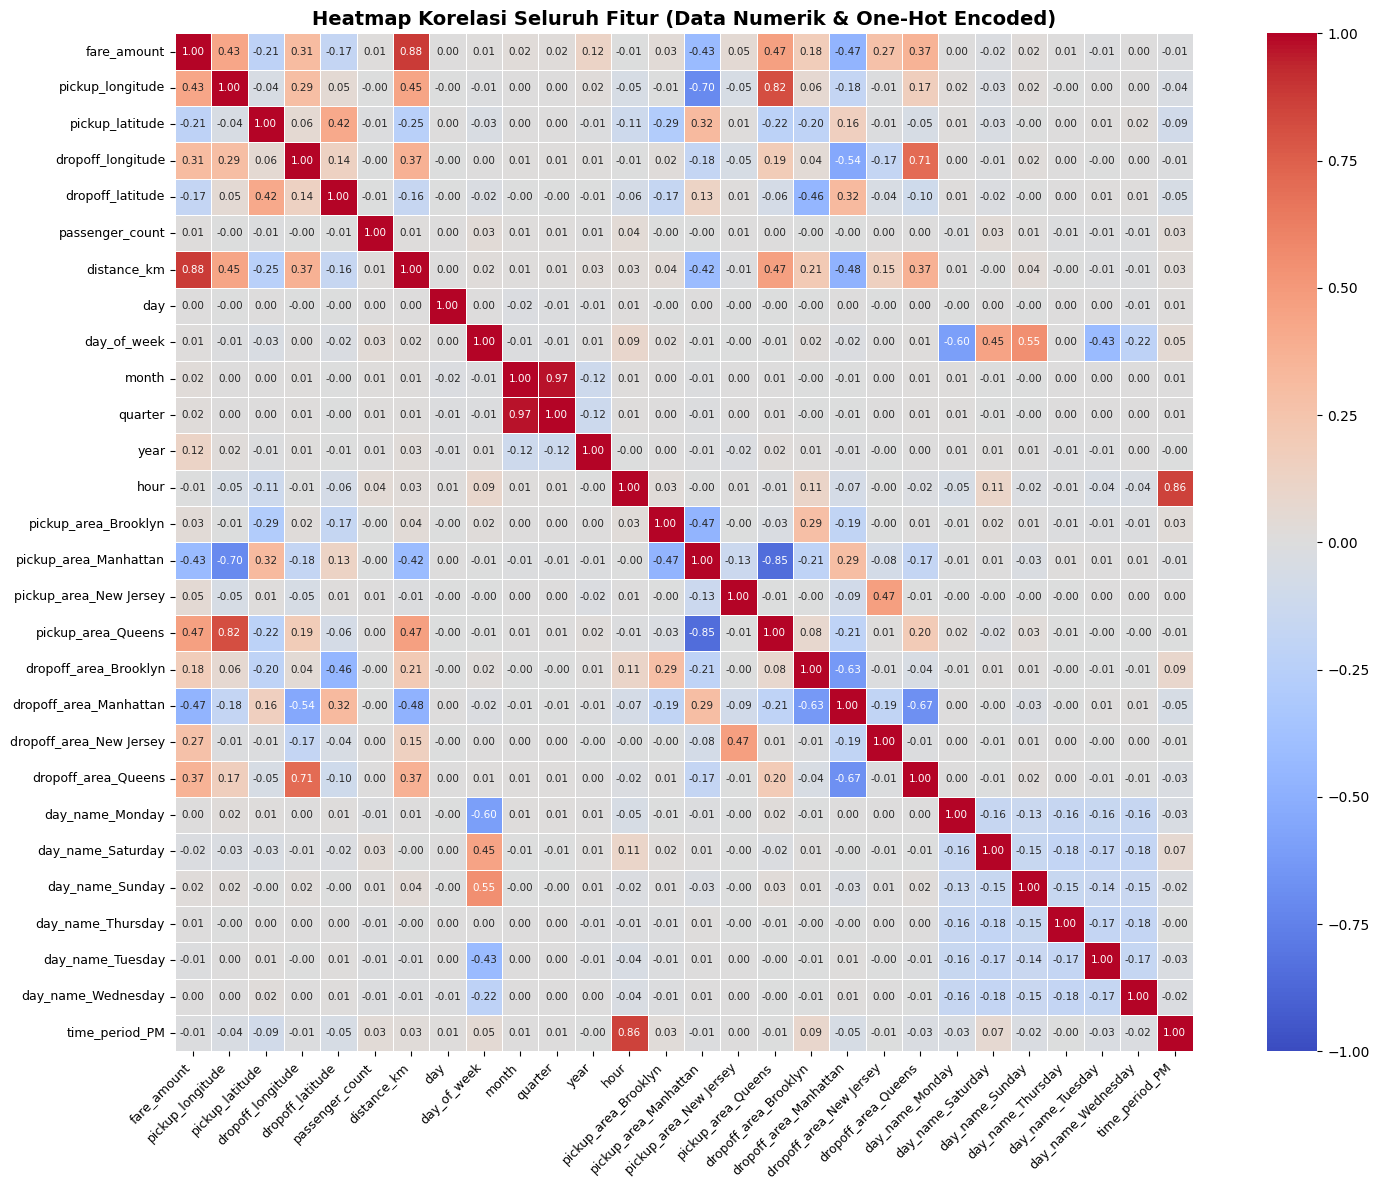

In [95]:
# [Visualisasi] Heatmap Korelasi
print(SEPARATOR)
print("HEATMAP KORELASI SELURUH FITUR (NUMERIK & ONE-HOT ENCODED)")
print(SEPARATOR)

# 1. Memilih seluruh kolom numerik dan biner dummy (mengabaikan kolom ID)
df_corr_num = df_encoded.select_dtypes(include=np.number)
if 'order_id' in df_corr_num.columns:
    df_corr_num = df_corr_num.drop(columns=['order_id'])

# 2. Menghitung Matriks Korelasi Pearson
corr_matrix = df_corr_num.corr()

# 3. Visualisasi Heatmap Matriks Lengkap
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    annot_kws={'size': 7.5}, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    square=True, 
    linewidths=0.5
)

plt.title('Heatmap Korelasi Seluruh Fitur (Data Numerik & One-Hot Encoded)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

#### Key Insight

Heatmap memperlihatkan bahwa hubungan `distance_km` dengan `fare_amount` lebih menonjol dibandingkan sejumlah fitur transaksi lainnya. Beberapa indikator lokasi juga menunjukkan korelasi positif atau negatif terhadap fare, tetapi kategori tersebut berasal dari pendekatan *bounding box* sehingga interpretasinya perlu hati-hati. Korelasi rendah pada fitur waktu di tingkat transaksi tidak berarti pola waktu tidak ada pada **total fare harian**, sebab total harian juga bergantung pada banyaknya perjalanan. Oleh karena itu, transaksi perlu diagregasikan menurut tanggal untuk memahami perubahan nilai total fare dari waktu ke waktu.


### 11.4 Membentuk Daily Total Fare (Agregasi Harian)

**Pertanyaan:** bagaimana ribuan transaksi individual berubah menjadi satu observasi total fare per hari?

Untuk setiap tanggal lokal New York, hitung `total_fare`, `total_trips`, dan `avg_fare`. Identitas yang digunakan selanjutnya adalah **tanggal**, bukan baris perjalanan. Tahap ini harus dijalankan **sebelum seluruh EDA berbasis `df_daily`**.


In [96]:

# [EDA] 11.4 - Agregasi Total Fare Harian

# 1. Membuat dataframe khusus time series
df_ts = df[['pickup_datetime', 'fare_amount']].copy()

# 2. Konversi datetime UTC ke waktu lokal New York
df_ts['pickup_datetime_ny'] = (
    pd.to_datetime(df_ts['pickup_datetime'], utc=True)
    .dt.tz_convert('America/New_York')
)

# 3. Ekstraksi tanggal lokal New York
df_ts['pickup_date'] = (
    df_ts['pickup_datetime_ny']
    .dt.tz_localize(None)
    .dt.normalize()
)

# 4. Validasi datetime
assert df_ts['pickup_date'].notna().all(), (
    "Terdapat tanggal yang tidak valid."
)

# 5. Agregasi data menjadi frekuensi harian
df_daily = (
    df_ts
    .set_index('pickup_date')
    .resample('D')
    .agg(
        total_fare=('fare_amount', 'sum'),
        total_trips=('fare_amount', 'size'),
        avg_fare=('fare_amount', 'mean')
    )
)

# 6. Validasi kontinuitas dan kualitas data
missing_days = (df_daily['total_trips'] == 0).sum()

fare_difference = (
    df_ts['fare_amount'].sum() - df_daily['total_fare'].sum()
)

print("=" * 55)
print("DAILY TIME SERIES AGGREGATION")
print("=" * 55)

print(f"Start Date          : {df_daily.index.min().date()}")
print(f"End Date            : {df_daily.index.max().date()}")
print(f"Total Days          : {len(df_daily):,}")
print(f"Total Transactions  : {len(df_ts):,}")
print(f"Days Without Trips  : {missing_days:,}")
print(f"Missing Avg Fare    : {df_daily['avg_fare'].isna().sum():,}")
print(f"Fare Difference  : {fare_difference:.6f}")

print("\nFIRST 5 ROWS")
display(df_daily.head())

print("\nLAST 5 ROWS")
display(df_daily.tail())

print("\nDESCRIPTIVE STATISTICS")
display(df_daily.describe().round(2))

# 7. Validasi kesesuaian agregasi
assert np.isclose(fare_difference, 0, atol=1e-6), (
    "Total fare tidak sesuai dengan data sumber."
)


DAILY TIME SERIES AGGREGATION
Start Date          : 2008-12-31
End Date            : 2015-06-30
Total Days          : 2,373
Total Transactions  : 193,755
Days Without Trips  : 0
Missing Avg Fare    : 0
Fare Difference  : 0.000000

FIRST 5 ROWS


,total_fare,total_trips,avg_fare
pickup_date,,,
2008-12-31,123.40,12,10.283333
2009-01-01,495.50,49,10.112245
2009-01-02,903.50,73,12.376712
2009-01-03,858.05,82,10.464024
2009-01-04,546.60,58,9.424138



LAST 5 ROWS


,total_fare,total_trips,avg_fare
pickup_date,,,
2015-06-26,1181.20,78,15.143590
2015-06-27,981.16,74,13.258919
2015-06-28,866.08,61,14.198033
2015-06-29,807.16,60,13.452667
2015-06-30,740.62,58,12.769310



DESCRIPTIVE STATISTICS


,total_fare,total_trips,avg_fare
count,2373.00,2373.00,2373.00
mean,924.54,81.65,11.36
std,230.28,17.09,1.78
min,65.60,8.00,7.23
25%,781.40,71.00,10.01
50%,916.49,83.00,11.07
75%,1066.98,94.00,12.56
max,1797.35,137.00,18.94


#### Key Insight

Agregasi menghasilkan 2.373 tanggal harian dari 193.755 transaksi sampel selama 31 Desember 2008–30 Juni 2015, tanpa hari kosong dalam rentang tersebut. Rata-rata total fare sekitar $924,54 per hari dan rata-rata jumlah perjalanan sekitar 81,65 per hari. Hari pertama (31 Desember 2008) hanya mencakup sebagian hari akibat konversi zona waktu, sehingga **analisis volatilitas dan perbandingan pola antartahun berikutnya mengecualikan hari tersebut**, sedangkan deret harian utama tetap menyimpannya. Setelah tingkat harian tersedia, perubahan nilai dan pola kalender dapat diamati secara lebih tepat.


### 11.5 Pergerakan Harian dan Pola Kalender Total Fare

**Pertanyaan:** bagaimana total fare, jumlah perjalanan, dan rata-rata fare berubah dari waktu ke waktu? Apakah terdapat perbedaan rata-rata total fare berdasarkan hari dalam seminggu dan bulan?

Analisis ini menampilkan **observasi harian apa adanya** serta perbandingan berdasarkan kalender. Tidak ada proses *smoothing* atau *rolling average* pada tahap EDA ini; penghalusan deret akan diperkenalkan pada bagian analisis time series.


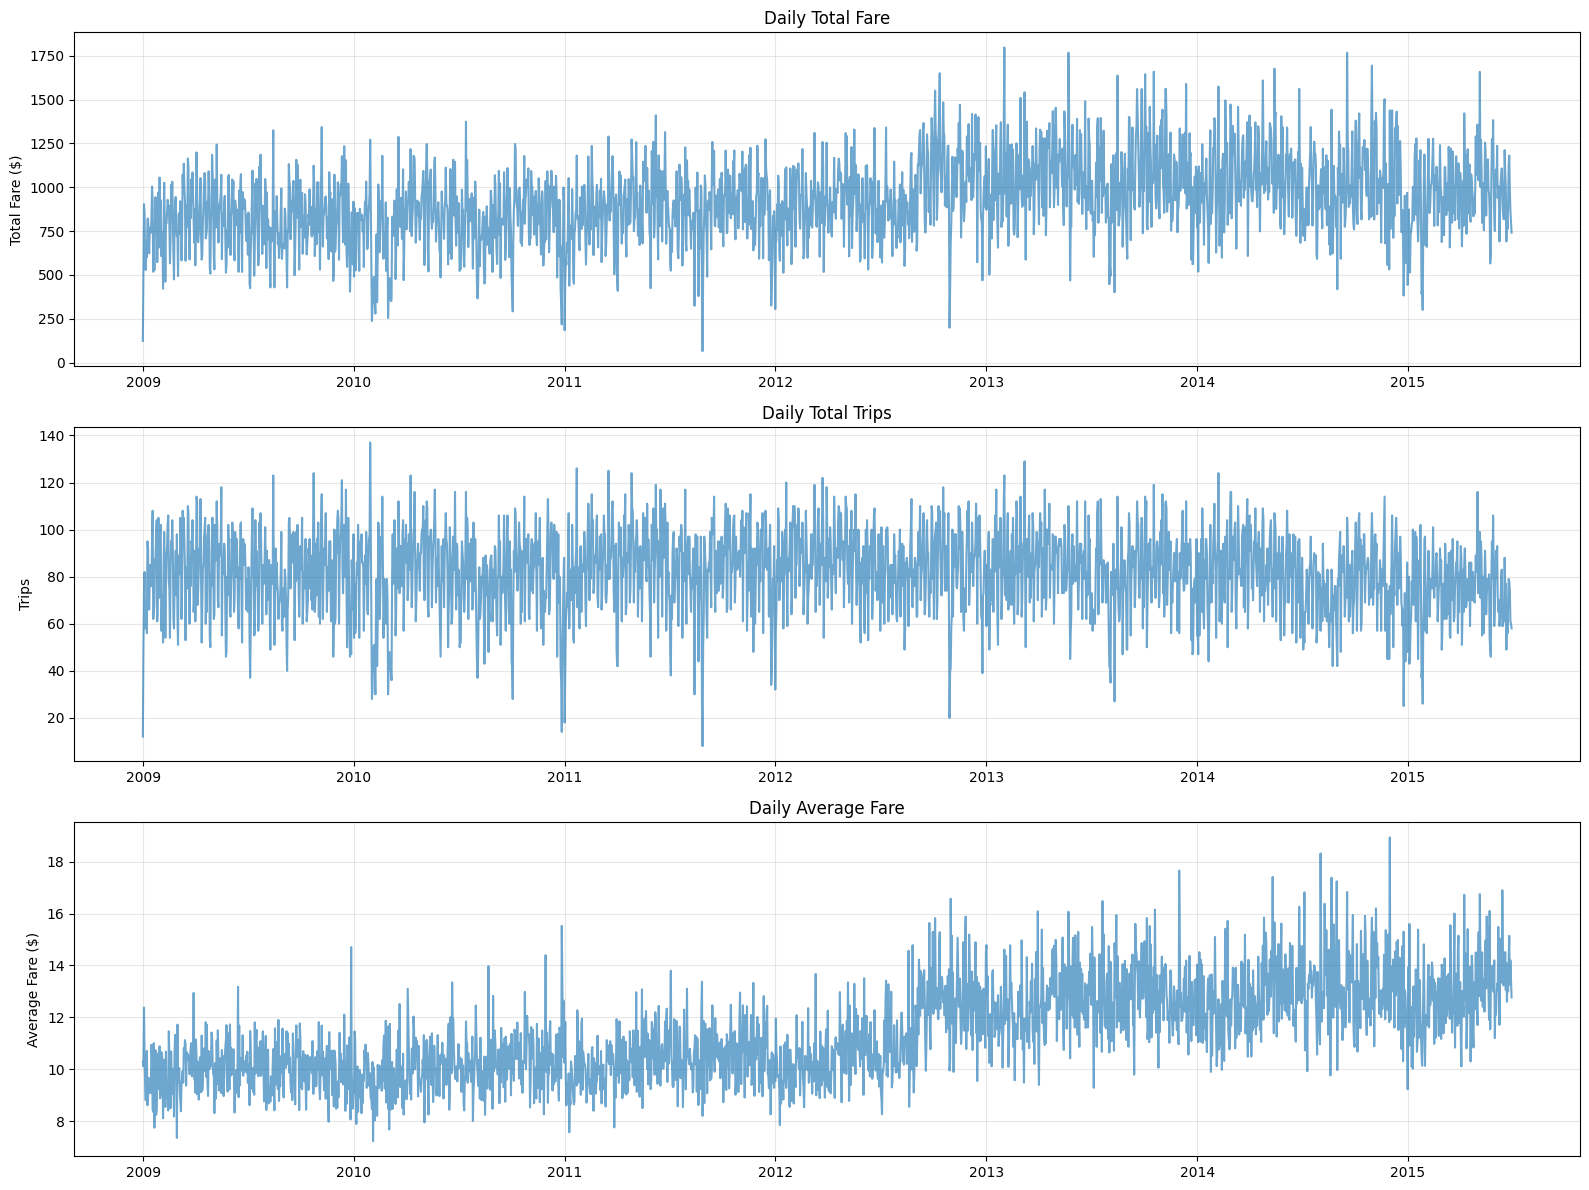

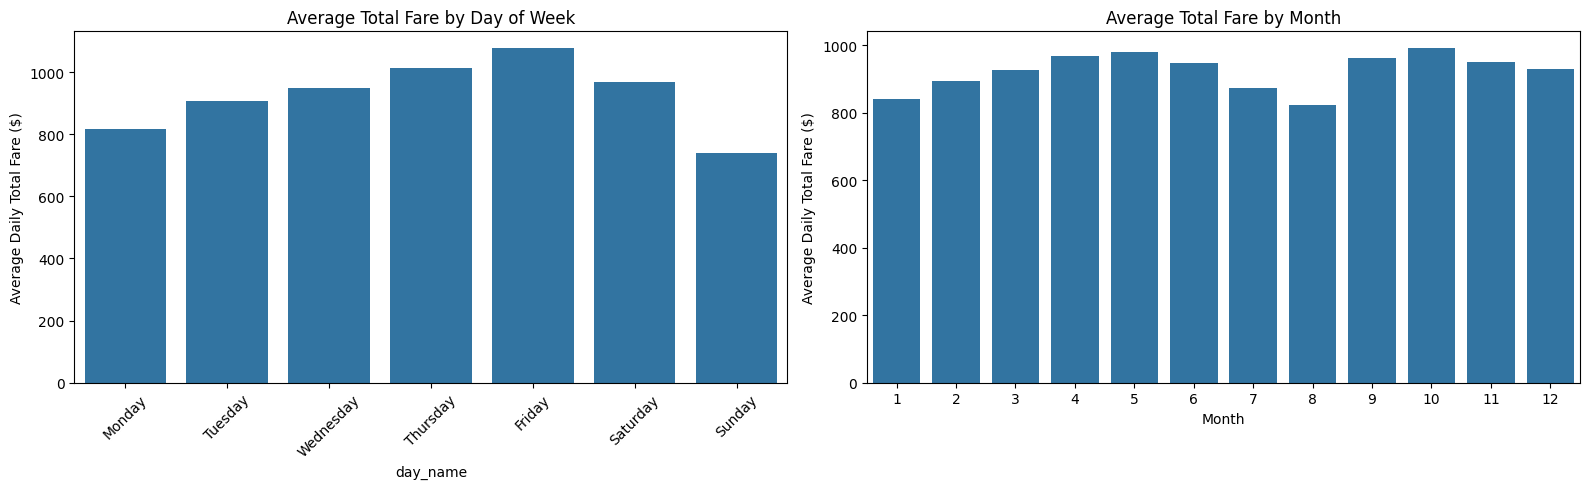

WEEKLY SEASONALITY


,Average Daily Total Fare
day_name,
Monday,817.49
Tuesday,905.66
Wednesday,948.98
Thursday,1013.09
Friday,1077.28
Saturday,968.77
Sunday,740.47



MONTHLY SEASONALITY


,Average Daily Total Fare
month,
1,841.78
2,895.98
3,927.08
4,967.72
5,980.26
6,946.67
7,873.34
8,823.49
9,962.40


In [97]:
# [EDA] 11.5 — Pergerakan Harian dan Pola Kalender Total Fare

# 1. Visualisasi data historis harian tanpa smoothing
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

metrics = [
    ('total_fare', 'Daily Total Fare', 'Total Fare ($)'),
    ('total_trips', 'Daily Total Trips', 'Trips'),
    ('avg_fare', 'Daily Average Fare', 'Average Fare ($)')
]

for ax, (col, title, ylabel) in zip(axes, metrics):
    ax.plot(df_daily.index, df_daily[col], alpha=0.65)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# 2. Analisis pola berdasarkan hari dan bulan
df_daily['day_name'] = df_daily.index.day_name()
df_daily['month'] = df_daily.index.month

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekly_pattern = (
    df_daily.groupby('day_name')['total_fare']
    .mean()
    .reindex(day_order)
)

monthly_pattern = (
    df_daily.groupby('month')['total_fare']
    .mean()
    .reindex(range(1, 13))
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    x=weekly_pattern.index,
    y=weekly_pattern.values,
    ax=axes[0]
)

axes[0].set_title('Average Total Fare by Day of Week')
axes[0].set_ylabel('Average Daily Total Fare ($)')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    x=monthly_pattern.index,
    y=monthly_pattern.values,
    ax=axes[1]
)

axes[1].set_title('Average Total Fare by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Daily Total Fare ($)')

plt.tight_layout()
plt.show()

# 3. Menampilkan ringkasan rata-rata berdasarkan kalender
print("WEEKLY SEASONALITY")
display(
    weekly_pattern.to_frame(
        name='Average Daily Total Fare'
    ).round(2)
)

print("\nMONTHLY SEASONALITY")
display(
    monthly_pattern.to_frame(
        name='Average Daily Total Fare'
    ).round(2)
)


#### Key Insight

Data harian memperlihatkan bahwa total fare, jumlah perjalanan, dan rata-rata fare berfluktuasi dari waktu ke waktu, dengan perubahan level total fare yang tampak sekitar akhir 2012. Berdasarkan pengelompokan kalender, rata-rata total fare Jumat sebesar $1.077,28 merupakan yang tertinggi, sedangkan Minggu sebesar $740,47 menjadi yang terendah; secara bulanan, Oktober mencatat rata-rata lebih tinggi dibandingkan Agustus. Temuan ini mengindikasikan adanya variasi historis dan pola kalender yang perlu diperiksa konsistensinya pada setiap tahun, sebelum digunakan sebagai dasar analisis deret waktu berikutnya.

### 11.6 Konsistensi Pola Mingguan Antar-Tahun

**Pertanyaan:** apakah Jumat selalu cenderung lebih tinggi dan Minggu lebih rendah, atau pola tersebut hanya muncul ketika seluruh tahun digabung?

Heatmap membandingkan **rata-rata total fare per hari dalam seminggu, pada setiap tahun**. Tahun 2015 hanya mencakup Januari–Juni; 2008 dikecualikan karena hanya tersisa satu hari parsial.


AVERAGE DAILY TOTAL FARE BY YEAR & WEEKDAY


Weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Year,,,,,,,
2009,698.77,831.12,808.31,912.01,969.61,840.42,629.91
2010,703.29,805.67,844.59,892.88,927.64,825.03,651.57
2011,766.38,892.80,899.60,957.37,999.42,920.81,674.19
2012,848.67,906.33,994.50,1056.62,1096.48,997.83,770.65
2013,960.61,1017.24,1078.32,1144.44,1241.57,1090.06,849.93
2014,917.11,977.97,1047.94,1125.60,1211.40,1107.55,831.69
2015,836.56,907.09,1020.92,996.22,1118.16,1032.52,809.11



WEEKLY FARE CONSISTENCY SUMMARY


,Highest Fare Day,Lowest Fare Day,Friday Fare,Sunday Fare,Friday vs Sunday (%)
Year,,,,,
2009,Friday,Sunday,969.61,629.91,53.93
2010,Friday,Sunday,927.64,651.57,42.37
2011,Friday,Sunday,999.42,674.19,48.24
2012,Friday,Sunday,1096.48,770.65,42.28
2013,Friday,Sunday,1241.57,849.93,46.08
2014,Friday,Sunday,1211.40,831.69,45.66
2015,Friday,Sunday,1118.16,809.11,38.20


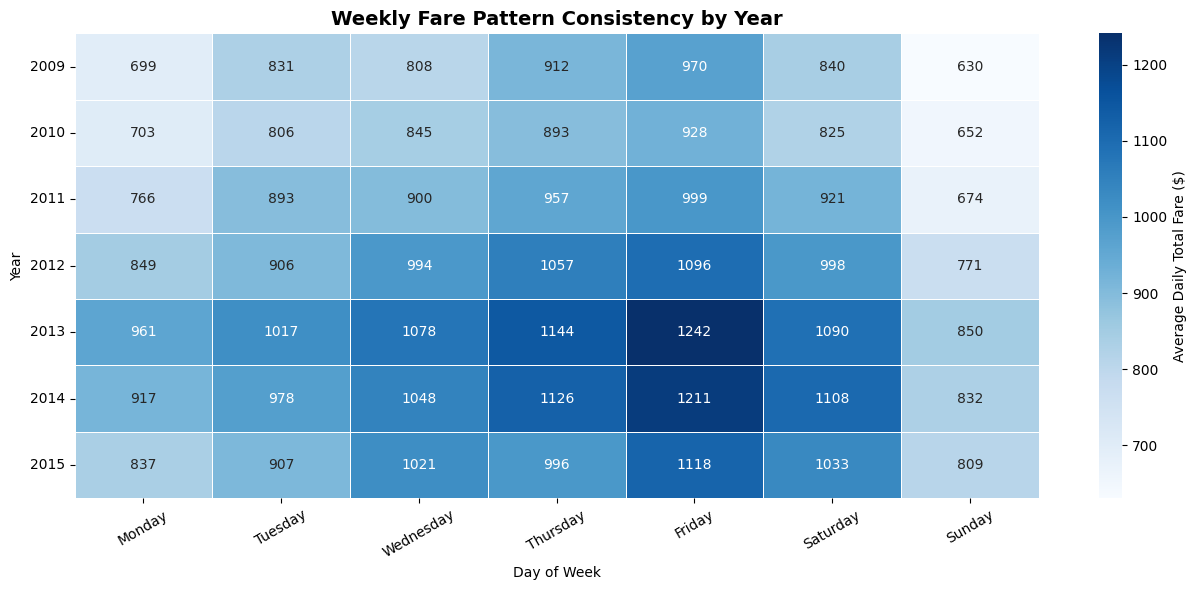

In [98]:

# 1. Menyiapkan data total fare harian
weekly_df = (
    df_daily[['total_fare']]
    .sort_index()
    .iloc[1:]
    .copy()
)

# 2. Membuat kolom tahun dan nama hari
weekly_df['Year'] = weekly_df.index.year
weekly_df['Weekday'] = weekly_df.index.day_name()

# Mengatur urutan hari dari Senin sampai Minggu
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# 3. Menghitung rata-rata total fare setiap hari per tahun
weekly_heatmap = (
    weekly_df
    .groupby(['Year', 'Weekday'])['total_fare']
    .mean()
    .unstack()
    .reindex(columns=weekday_order)
)

# 4. Menampilkan tabel rata-rata total fare
print("AVERAGE DAILY TOTAL FARE BY YEAR & WEEKDAY")
display(weekly_heatmap.round(2))

# 5. Mengidentifikasi hari dengan rata-rata tertinggi dan terendah
weekly_summary = pd.DataFrame({
    'Highest Fare Day': weekly_heatmap.idxmax(axis=1),
    'Lowest Fare Day': weekly_heatmap.idxmin(axis=1),
    'Friday Fare': weekly_heatmap['Friday'],
    'Sunday Fare': weekly_heatmap['Sunday']
})

# Menghitung persentase selisih Jumat dibanding Minggu
weekly_summary['Friday vs Sunday (%)'] = (
    (weekly_summary['Friday Fare'] -
     weekly_summary['Sunday Fare']) /
    weekly_summary['Sunday Fare'] * 100
)

print("\nWEEKLY FARE CONSISTENCY SUMMARY")
display(weekly_summary.round(2))

# 6. Membuat heatmap pola total fare mingguan per tahun
plt.figure(figsize=(13, 6))

sns.heatmap(
    weekly_heatmap,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5,
    cbar_kws={'label': 'Average Daily Total Fare ($)'}
)

# 7. Mengatur tampilan grafik
plt.title(
    'Weekly Fare Pattern Consistency by Year',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Day of Week')
plt.ylabel('Year')
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#### Key Insight

Rata-rata total fare pada hari Jumat menjadi yang tertinggi dan hari Minggu menjadi yang terendah pada masing-masing tahun pengamatan 2009–2015. Selisih Jumat terhadap Minggu berkisar 38,20% hingga 53,93%, meskipun level fare antartahun berubah. Temuan ini mendukung adanya pola mingguan yang berulang dalam sampel, bukan sekadar perbedaan yang muncul dari agregasi seluruh periode. Pola tersebut perlu dipertimbangkan ketika mengevaluasi perubahan fare harian selanjutnya; perbandingan dengan 2015 tetap perlu hati-hati karena cakupannya hanya setengah tahun.


### 11.7 Volatilitas Perubahan Total Fare Harian

**Pertanyaan:** seberapa besar total fare berubah dari satu hari ke hari berikutnya?

Perubahan harian dihitung dengan `(fare hari ini / fare kemarin − ) × 100%`. Tanda positif berarti naik, negatif berarti turun, sedangkan nilai absolut menunjukkan **besar perubahan tanpa memperhatikan arah**. Grafik hanya menampilkan persentil 1–99 agar mudah dibaca; ringkasan metrik tetap menggunakan seluruh perubahan valid setelah hari parsial dikeluarkan.


DAILY FARE VOLATILITY SUMMARY


,Metric,Value
0,Average Daily Total Fare,924.87
1,Standard Deviation,229.74
2,Coefficient of Variation (%),24.84
3,Average Absolute Daily Change (%),22.14
4,Days with Change Above 20% (%),43.32
5,Minimum Daily Fare,65.60
6,Maximum Daily Fare,1797.35


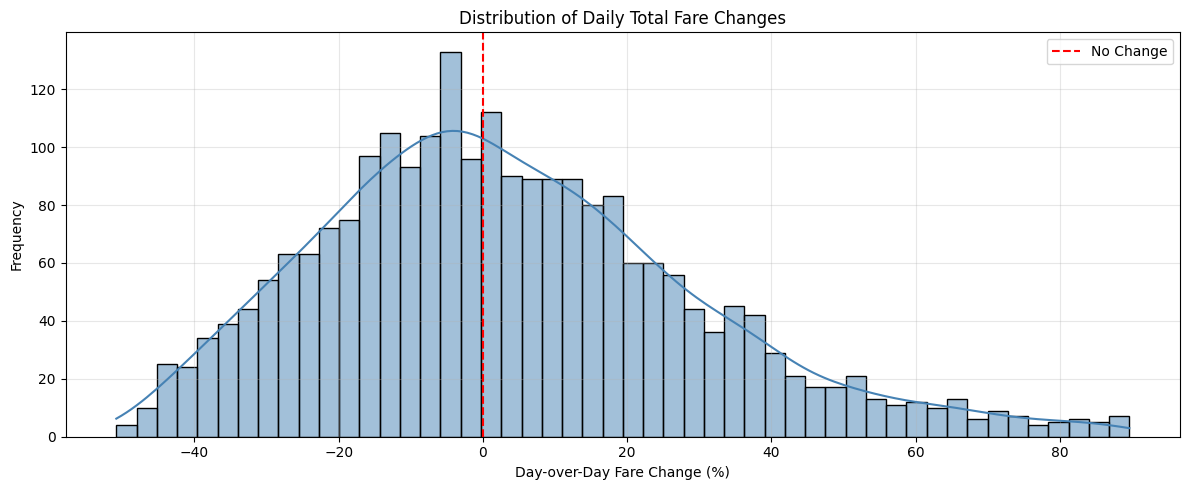

In [99]:

# 1. Menyiapkan data total fare harian
volatility_df = (
    df_daily[['total_fare']]
    .sort_index()
    .copy()
)

# Menghapus hari pertama karena datanya hanya mencakup sebagian hari
volatility_df = volatility_df.iloc[1:].copy()

# 2. Menghitung persentase perubahan total fare dari hari sebelumnya
volatility_df['Daily_Change_Pct'] = (
    volatility_df['total_fare'].pct_change() * 100
)

# 3. Menghitung metrik volatilitas harian
daily_change = (
    volatility_df['Daily_Change_Pct']
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

summary = pd.DataFrame({
    'Metric': [
        'Average Daily Total Fare',
        'Standard Deviation',
        'Coefficient of Variation (%)',
        'Average Absolute Daily Change (%)',
        'Days with Change Above 20% (%)',
        'Minimum Daily Fare',
        'Maximum Daily Fare'
    ],
    'Value': [
        volatility_df['total_fare'].mean(),
        volatility_df['total_fare'].std(),
        (
            volatility_df['total_fare'].std()
            / volatility_df['total_fare'].mean()
        ) * 100,
        daily_change.abs().mean(),
        (daily_change.abs() > 20).mean() * 100,
        volatility_df['total_fare'].min(),
        volatility_df['total_fare'].max()
    ]
})

# Menampilkan ringkasan statistik volatilitas
print("DAILY FARE VOLATILITY SUMMARY")
display(summary.round(2))

# 4. Menyiapkan distribusi perubahan harian untuk visualisasi
# Membatasi tampilan pada persentil 1 hingga 99 agar lebih mudah dibaca
lower = daily_change.quantile(0.01)
upper = daily_change.quantile(0.99)

plot_data = daily_change[
    daily_change.between(lower, upper)
]

# 5. Membuat histogram distribusi perubahan total fare harian
plt.figure(figsize=(12, 5))

sns.histplot(
    plot_data,
    bins=50,
    kde=True,
    color='steelblue'
)

# Menambahkan garis referensi pada perubahan 0%
plt.axvline(
    0,
    color='red',
    linestyle='--',
    label='No Change'
)

# Mengatur judul, label sumbu, dan tampilan grafik
plt.title('Distribution of Daily Total Fare Changes')
plt.xlabel('Day-over-Day Fare Change (%)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Setelah hari pertama yang parsial dikeluarkan, rata-rata total fare harian menjadi $924,87 dengan *coefficient of variation* sebesar 24,84%. Rata-rata besar perubahan absolut dari hari ke hari mencapai 22,14%, dan 43,32% perubahan harian memiliki besaran lebih dari 20%, baik naik maupun turun. Histogram menunjukkan sebaran perubahan yang cukup lebar, dengan ekor positif yang lebih panjang pada rentang visualisasi. Temuan ini mengindikasikan bahwa nilai fare hari sebelumnya saja belum tentu representatif untuk hari berikutnya; perubahan harian perlu ditinjau bersama pola kalender dan aktivitas perjalanan.


### 11.8 Hubungan Jumlah Perjalanan dengan Total Fare Harian

**Pertanyaan:** apakah hari dengan lebih banyak perjalanan cenderung memiliki total fare lebih tinggi?

Analisis membandingkan korelasi `total_trips` dan `avg_fare` dengan `total_fare`. Keduanya saling terkait melalui identitas `total_fare = total_trips × avg_fare`, sehingga korelasi **tidak** boleh ditafsirkan sebagai bukti penyebab tunggal.


DAILY TRIP VOLUME VS TOTAL FARE SUMMARY


,Variable Relationship,Pearson Correlation
0,Total Trips vs Total Fare,0.784
1,Average Fare vs Total Fare,0.532


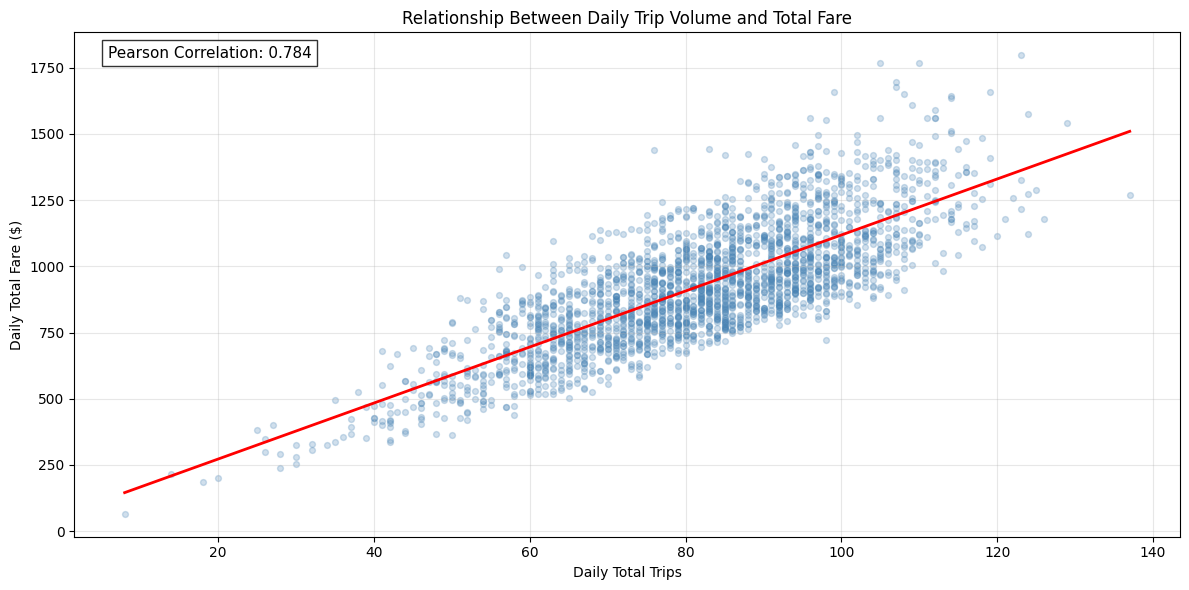

In [100]:

# 1. Menyiapkan data jumlah perjalanan dan total fare harian
trip_fare_df = (
    df_daily[['total_trips', 'total_fare', 'avg_fare']]
    .sort_index()
    .iloc[1:]  # Menghapus hari pertama yang datanya parsial
    .dropna()
    .copy()
)

# 2. Menghitung korelasi Pearson
corr_trips_fare = trip_fare_df['total_trips'].corr(
    trip_fare_df['total_fare']
)

corr_avgfare_fare = trip_fare_df['avg_fare'].corr(
    trip_fare_df['total_fare']
)

# 3. Menampilkan ringkasan statistik
print("DAILY TRIP VOLUME VS TOTAL FARE SUMMARY")

correlation_summary = pd.DataFrame({
    'Variable Relationship': [
        'Total Trips vs Total Fare',
        'Average Fare vs Total Fare'
    ],
    'Pearson Correlation': [
        corr_trips_fare,
        corr_avgfare_fare
    ]
})

display(correlation_summary.round(3))

# 4. Membuat scatter plot dengan garis regresi
plt.figure(figsize=(12, 6))

sns.regplot(
    data=trip_fare_df,
    x='total_trips',
    y='total_fare',
    scatter_kws={
        'alpha': 0.25,
        's': 18,
        'color': 'steelblue'
    },
    line_kws={
        'color': 'red',
        'linewidth': 2
    },
    ci=None
)

# 5. Menampilkan nilai korelasi pada grafik
plt.text(
    0.03, 0.95,
    f'Pearson Correlation: {corr_trips_fare:.3f}',
    transform=plt.gca().transAxes,
    fontsize=11,
    bbox=dict(facecolor='white', alpha=0.8)
)

# 6. Mengatur tampilan grafik
plt.title('Relationship Between Daily Trip Volume and Total Fare')
plt.xlabel('Daily Total Trips')
plt.ylabel('Daily Total Fare ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Pada tingkat harian, jumlah perjalanan memiliki korelasi positif kuat dengan total fare (Pearson 0,784), sedangkan rata-rata tarif per perjalanan menunjukkan korelasi positif sedang (0,532). Artinya, hari dengan lebih banyak perjalanan cenderung mencatat total fare lebih besar, tetapi variasi rata-rata tarif turut berkaitan dengan nilainya. Karena total fare dihitung dari jumlah perjalanan dikalikan rata-rata fare, hubungan tersebut sebagian berasal dari definisi metrik dan belum membuktikan sebab-akibat. Kedua komponen ini perlu dibaca bersama ketika menjelaskan perubahan total fare historis.


### 11.9 Hasil Observasi EDA

EDA menunjukkan **total fare harian berubah cukup besar, tetapi tidak sepenuhnya tanpa pola**. Sebanyak 43,32% perubahan harian memiliki besaran di atas 20%, sementara Jumat selalu menjadi hari dengan rata-rata fare tertinggi dan Minggu terendah pada tiap tahun pengamatan 2009–2015. Pada saat yang sama, jumlah perjalanan berkorelasi positif dengan total fare (r = 0,784). Dengan demikian, analisis deskriptif dapat mengungkap **seberapa besar perubahan dan kapan pola berulang terjadi**, namun belum menjawab berapa total fare yang mungkin tercatat pada periode berikutnya.

**Pertanyaan untuk tahap berikutnya:** apakah struktur historis tersebut cukup stabil dan informatif untuk menghasilkan perkiraan total fare harian selama 30 hari berikutnya? Pertanyaan ini akan dievaluasi pada bagian analisis time series dan pengujian prediksi, tanpa menganggap bahwa volatilitas atau korelasi saja sudah membuktikan keakuratan forecast.

## 12. Analisis Time Series & Evaluasi Forecasting

Setelah EDA menjelaskan karakteristik transaksi, pola kalender, serta volatilitas total fare harian, tahap ini dimulai dengan **smoothing (rolling average)** untuk membantu membaca arah pergerakan historis. Selanjutnya dilakukan dekomposisi, pengujian karakteristik deret waktu, dan evaluasi kandidat model pada periode testing. Smoothing hanya merangkum data masa lalu, **bukan model forecasting**.


### 12.1 Smoothing — Rolling Average 7 dan 30 Hari

**Pertanyaan:** bagaimana arah pergerakan total fare historis terlihat ketika fluktuasi harian diperhalus?

Hitung *rolling average* 7 dan 30 hari untuk memudahkan pembacaan arah historis. Nilai pada suatu hari menggunakan observasi hingga hari tersebut (*trailing window*), sehingga tidak menggunakan data masa depan. Hasil smoothing adalah **ringkasan masa lalu**, bukan prediksi atau bukti bahwa model tertentu pasti lebih akurat.


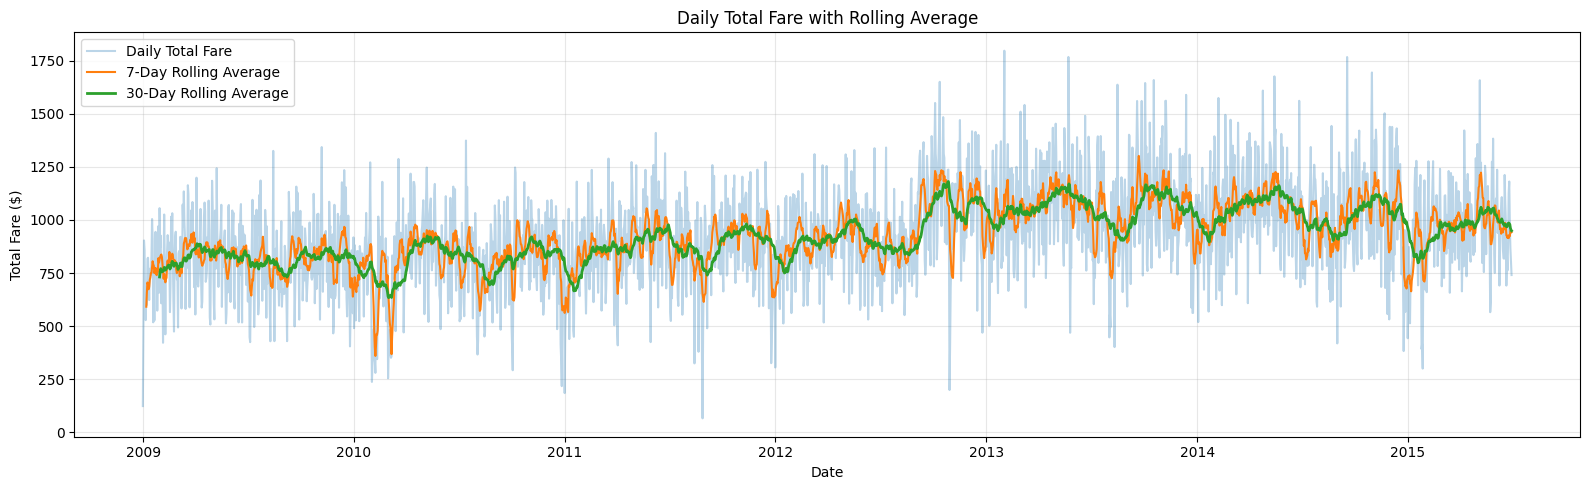

In [101]:
# [Time Series] 12.1 — Smoothing Total Fare Harian

# 1. Menghitung rata-rata bergerak 7 hari dan 30 hari
# Menggunakan 7/30 observasi sampai tanggal saat ini, tanpa data masa depan
df_daily['rolling_7d'] = (
    df_daily['total_fare'].rolling(window=7).mean()
)

df_daily['rolling_30d'] = (
    df_daily['total_fare'].rolling(window=30).mean()
)

# 2. Memvisualisasikan total fare asli dan hasil smoothing
plt.figure(figsize=(16, 5))

plt.plot(
    df_daily.index,
    df_daily['total_fare'],
    alpha=0.3,
    label='Daily Total Fare'
)

plt.plot(
    df_daily.index,
    df_daily['rolling_7d'],
    label='7-Day Rolling Average'
)

plt.plot(
    df_daily.index,
    df_daily['rolling_30d'],
    label='30-Day Rolling Average',
    linewidth=2
)

plt.title('Daily Total Fare with Rolling Average')
plt.xlabel('Date')
plt.ylabel('Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Penghalusan menggunakan rata-rata bergerak 7 dan 30 hari membuat pergerakan historis total fare lebih mudah diamati tanpa mengubah nilai transaksi aslinya. Rata-rata 7 hari lebih responsif terhadap perubahan jangka pendek, sedangkan rata-rata 30 hari memperlihatkan perubahan level yang lebih halus, termasuk pergeseran yang tampak sekitar akhir 2012. Karena rolling average hanya merangkum observasi terdahulu, tahap berikutnya perlu memeriksa komponen trend, seasonality, dan residual secara lebih terstruktur.


### 12.2 STL Decomposition

Melakukan STL untuk memisahkan trend, seasonality mingguan, dan residual dari total fare harian. Analisis ini baru dilakukan setelah pola historis dan perubahan nilai dibahas pada EDA.


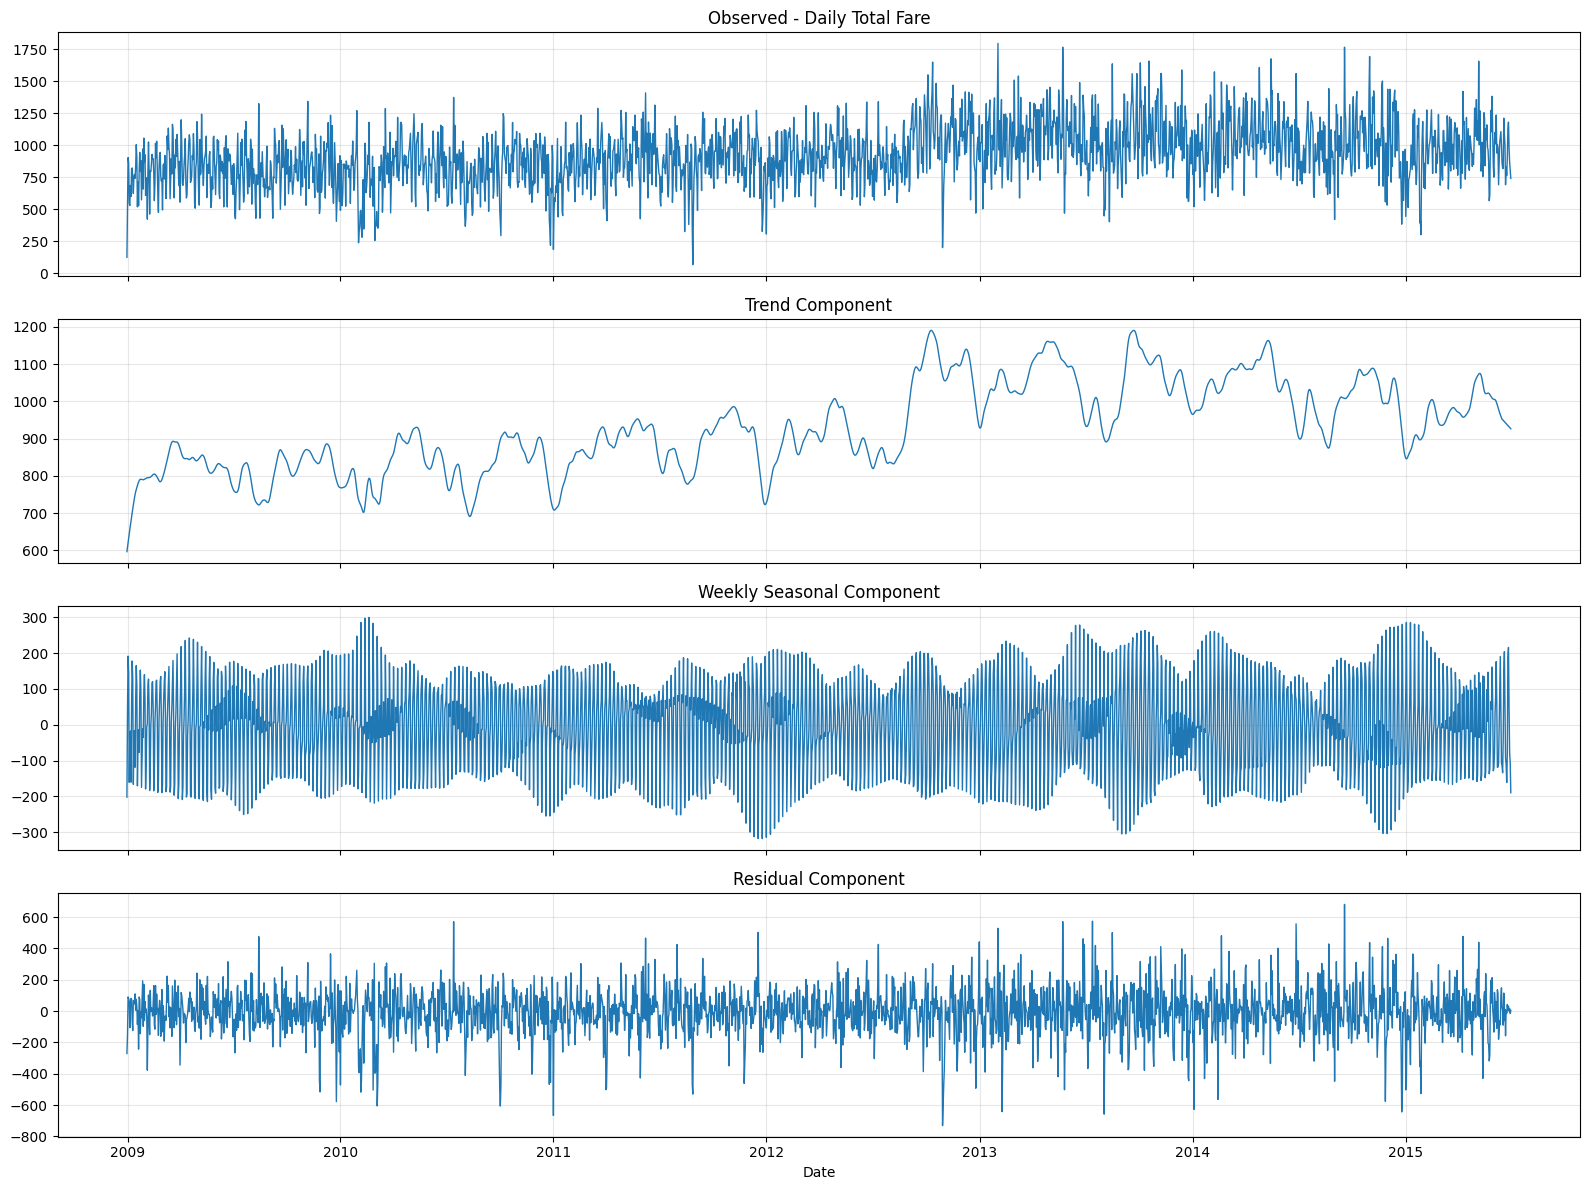


STL COMPONENT SUMMARY


,observed,trend,seasonal,residual
count,2373.00,2373.00,2373.00,2373.00
mean,924.54,929.47,-0.08,-4.85
std,230.28,116.59,121.90,153.37
min,65.60,596.77,-318.38,-731.55
25%,781.40,841.06,-98.33,-83.93
50%,916.49,916.98,10.90,-0.16
75%,1066.98,1022.65,88.46,80.95
max,1797.35,1190.23,299.94,681.36



STL STRENGTH
Trend Strength    : 0.3989
Seasonal Strength : 0.3714

Max Reconstruction Error: 0.0000000000


In [102]:
# [Time Series] Step 3 - STL Decomposition

from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Menentukan target forecasting
ts = df_daily['total_fare'].copy()

assert ts.notna().all(), "Time series masih memiliki missing values!"

# 2. STL Decomposition (Weekly Seasonality)
stl = STL(
    ts,
    period=7,
    seasonal=13,
    trend=31,
    robust=True
)

stl_result = stl.fit()

# 3. Menyimpan komponen STL
df_stl = pd.DataFrame({
    'observed': ts,
    'trend': stl_result.trend,
    'seasonal': stl_result.seasonal,
    'residual': stl_result.resid
})

# 4. Visualisasi STL
fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

components = [
    ('observed', 'Observed - Daily Total Fare'),
    ('trend', 'Trend Component'),
    ('seasonal', 'Weekly Seasonal Component'),
    ('residual', 'Residual Component')
]

for ax, (col, title) in zip(axes, components):
    ax.plot(df_stl.index, df_stl[col], linewidth=1)
    ax.set_title(title)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Date')

plt.tight_layout()
plt.show()

# 5. Menghitung kekuatan trend dan seasonality
var_residual = np.var(df_stl['residual'])

trend_strength = max(
    0,
    1 - var_residual /
    np.var(df_stl['trend'] + df_stl['residual'])
)

seasonal_strength = max(
    0,
    1 - var_residual /
    np.var(df_stl['seasonal'] + df_stl['residual'])
)

print("\nSTL COMPONENT SUMMARY")
display(df_stl.describe().round(2))

print("\nSTL STRENGTH")
print(f"Trend Strength    : {trend_strength:.4f}")
print(f"Seasonal Strength : {seasonal_strength:.4f}")

# 7. Validasi rekonstruksi
reconstructed = (
    df_stl['trend'] +
    df_stl['seasonal'] +
    df_stl['residual']
)

reconstruction_error = np.abs(
    df_stl['observed'] - reconstructed
).max()

print(f"\nMax Reconstruction Error: {reconstruction_error:.10f}")


#### Key Insight

Hasil STL menunjukkan komponen trend dan pola berulang tujuh harian, dengan Trend Strength sebesar 0,3989 dan Seasonal Strength sebesar 0,3714. Perubahan level terlihat sekitar akhir 2012, sementara residual masih memiliki standar deviasi sekitar $153,37 sehingga sebagian fluktuasi harian belum dijelaskan oleh trend dan seasonality. Karena itu, struktur time series perlu dievaluasi lebih lanjut melalui ADF serta ACF/PACF untuk menyusun kandidat model; angka kekuatan komponen tersebut tidak secara langsung menunjukkan persentase total fare yang dapat diprediksi.


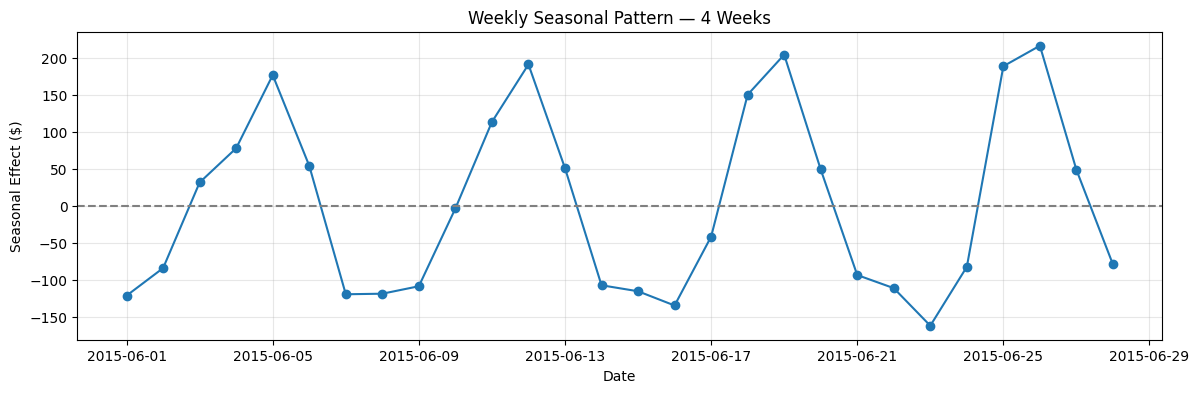

In [103]:
seasonal_4weeks = df_stl.loc[
    "2015-06-01":"2015-06-28", "seasonal"
]

plt.figure(figsize=(14, 4))
plt.plot(
    seasonal_4weeks.index,
    seasonal_4weeks,
    marker="o",
    linewidth=1.5
)

plt.axhline(0, color="gray", linestyle="--")
plt.title("Weekly Seasonal Pattern — 4 Weeks")
plt.ylabel("Seasonal Effect ($)")
plt.xlabel("Date")
plt.grid(alpha=0.3)
plt.show()

### 12.3 Stationarity Testing (ADF)

Menguji keberadaan unit root menggunakan ADF terhadap deret total fare. Hasil dibaca sebagai bukti statistik dalam spesifikasi tes, bukan sebagai jaminan seluruh karakteristik deret selalu konstan.


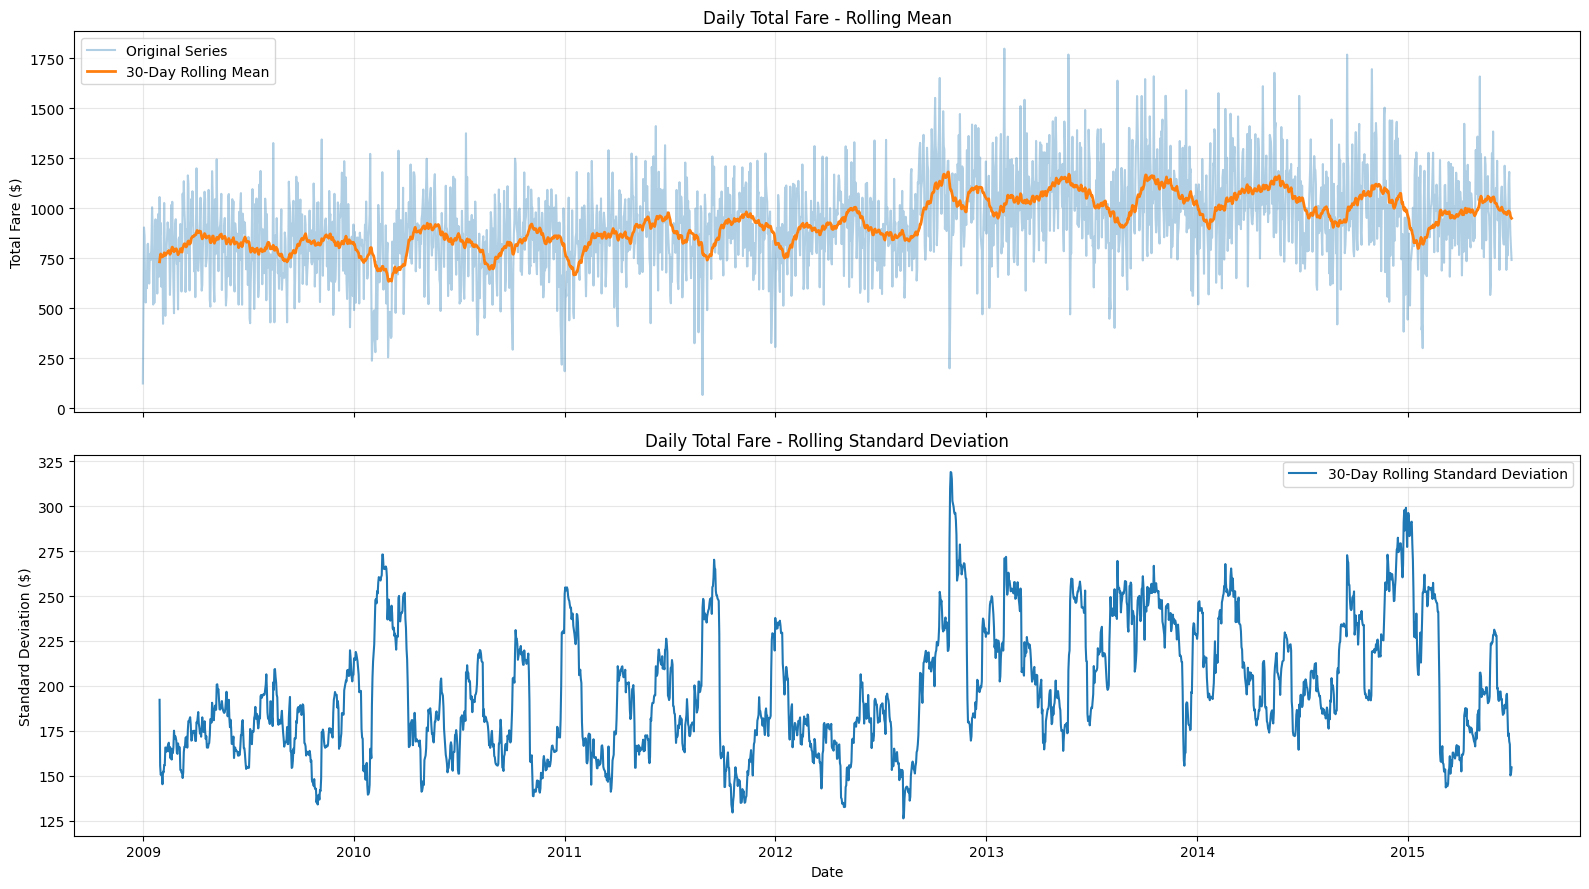

ADF STATIONARITY TEST — ORIGINAL SERIES


,Metric,Value
0,Observations,2373.000000
1,ADF Statistic,-3.621256
2,p-value,0.005367
3,Lags Used,27.000000



ADF CRITICAL VALUES


,Critical Value
1%,-3.433142
5%,-2.862773
10%,-2.567427



KESIMPULAN (berdasarkan ADF saja):
STASIONER MENURUT ADF (p-value < 0,05)


In [104]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
import matplotlib.pyplot as plt

# 1. Target time series
ts = df_daily['total_fare'].dropna().copy()

# 2. Rolling Statistics (30 Hari) untuk visualisasi
rolling_mean = ts.rolling(window=30).mean()
rolling_std = ts.rolling(window=30).std()

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

axes[0].plot(ts.index, ts, alpha=0.35, label='Original Series')
axes[0].plot(rolling_mean.index, rolling_mean,linewidth=2, label='30-Day Rolling Mean')
axes[0].set_title('Daily Total Fare - Rolling Mean')
axes[0].set_ylabel('Total Fare ($)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(rolling_std.index, rolling_std, label='30-Day Rolling Standard Deviation')
axes[1].set_title('Daily Total Fare - Rolling Standard Deviation')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Standard Deviation ($)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. ADF Test
adf_result = adfuller(ts, regression='c', autolag='AIC')
alpha = 0.05

adf_summary = pd.DataFrame({
    'Metric': ['Observations', 'ADF Statistic', 'p-value', 'Lags Used'],
    'Value': [len(ts), adf_result[0], adf_result[1], adf_result[2]]
})

print('ADF STATIONARITY TEST — ORIGINAL SERIES')
display(adf_summary.round(6))

print('\nADF CRITICAL VALUES')
display(pd.Series(adf_result[4], name='Critical Value').to_frame())

print('\nKESIMPULAN (berdasarkan ADF saja):')
if adf_result[1] < alpha:
    print('STASIONER MENURUT ADF (p-value < 0,05)')
else:
    print('BELUM TERBUKTI STASIONER MENURUT ADF (p-value >= 0,05)')

#### Key Insight

Hasil ADF Test pada total fare harian menunjukkan ADF Statistic sebesar -3,621256 dan p-value sebesar 0,005367, lebih kecil dari 0,05. Dengan demikian, original series menunjukkan bukti yang mendukung stasioneritas menurut ADF. Namun, grafik rolling mean masih memperlihatkan perubahan level sekitar akhir 2012, sehingga hasil ADF tidak dianggap sebagai bukti bahwa seluruh karakteristik statistik data selalu konstan. Tahap berikutnya membandingkan beberapa skenario differencing sebagai kandidat konfigurasi ARIMA dan SARIMA, bukan karena original series wajib dilakukan differencing.


### 12.4 ACF & PACF

Menganalisis hubungan antarobservasi pada berbagai lag untuk menilai pola autoregressive, moving average, dan siklus mingguan sebagai dasar penyusunan kandidat model.


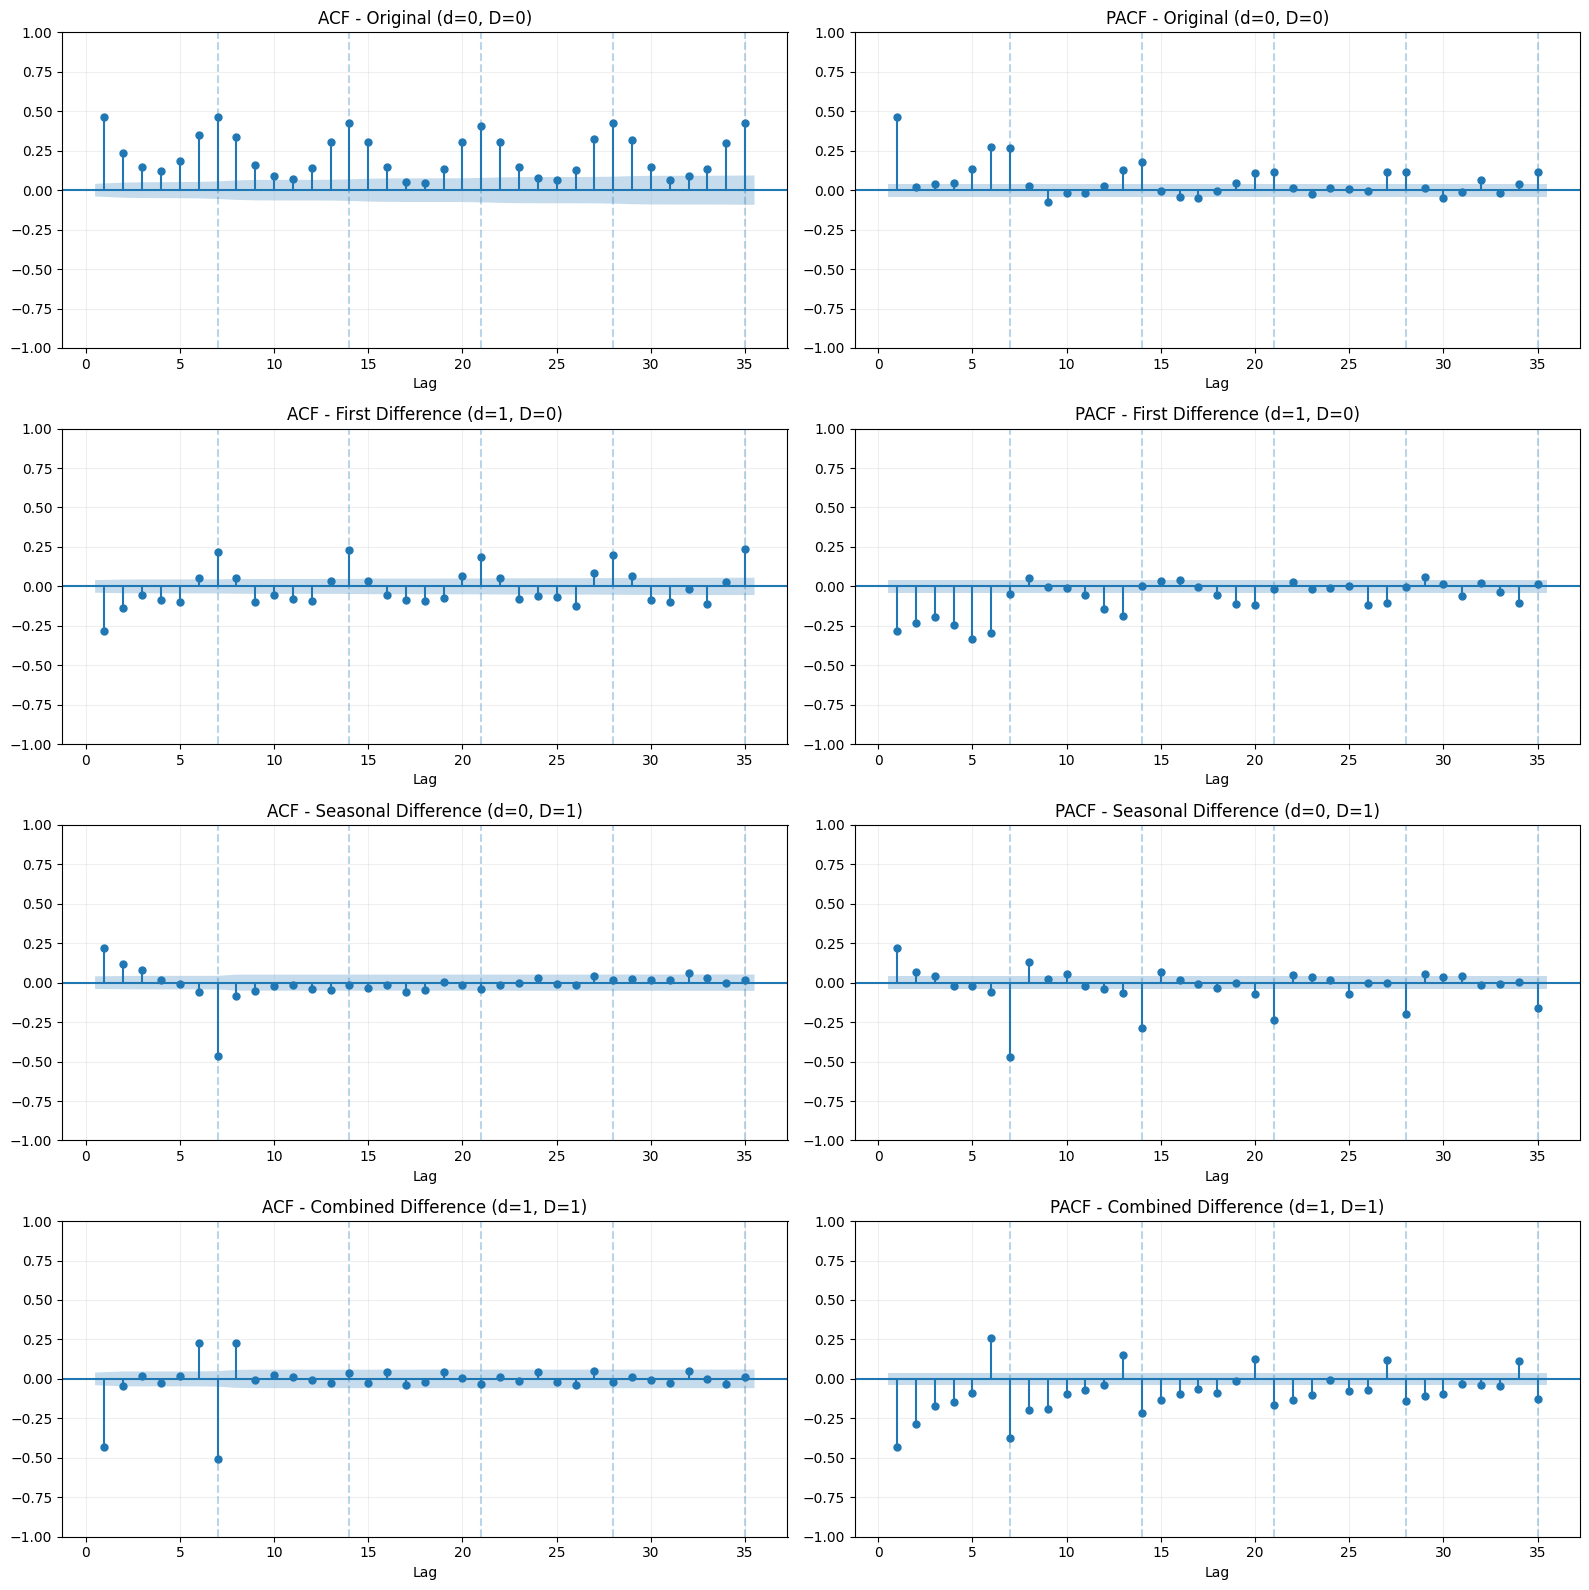

ACF & PACF SUMMARY


ACF                              \
Scenario Combined Difference (d=1, D=1) First Difference (d=1, D=0)   
Lag                                                                   
1                               -0.4324                     -0.2831   
2                               -0.0452                     -0.1341   
3                                0.0210                     -0.0545   
7                               -0.5073                      0.2199   
14                               0.0348                      0.2315   
21                              -0.0328                      0.1891   
28                              -0.0178                      0.1979   
35                               0.0112                      0.2340   

                                                             \
Scenario Original (d=0, D=0) Seasonal Difference (d=0, D=1)   
Lag                                                           
1                     0.4643                         0.2207   
2                     0.2329                         0.1153   
3                     0.1470                         0.0816   
7                     0.4619                        -0.4669   
14                    0.4264                        -0.0126   
21                    0.4051                        -0.0395   
28                    0.4274                         0.0187   
35                    0.4285                         0.0194   

                                   PACF                              \
Scenario Combined Difference (d=1, D=1) First Difference (d=1, D=0)   
Lag                                                                   
1                               -0.4324                     -0.2831   
2                               -0.2856                     -0.2329   
3                               -0.1709                     -0.1922   
7                               -0.3760                     -0.0461   
14                              -0.2181                      0.0002   
21                              -0.1680                     -0.0146   
28                              -0.1402                     -0.0064   
35                              -0.1299                      0.0156   

                                                             
Scenario Original (d=0, D=0) Seasonal Difference (d=0, D=1)  
Lag                                                          
1                     0.4643                         0.2207  
2                     0.0220                         0.0699  
3                     0.0396                         0.0449  
7                     0.2659                        -0.4680  
14                    0.1795                        -0.2848  
21                    0.1132                        -0.2347  
28                    0.1153                        -0.1977  
35                    0.1119                        -0.1600

In [105]:

# [Time Series] Step 6 - ACF & PACF Analysis

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Target Time Series
ts = df_daily['total_fare'].asfreq('D').copy()

# 2. Differencing Scenarios
diff_scenarios = {
    'Original (d=0, D=0)': ts,
    'First Difference (d=1, D=0)': ts.diff(1),
    'Seasonal Difference (d=0, D=1)': ts.diff(7),
    'Combined Difference (d=1, D=1)': ts.diff(1).diff(7)
}

# 3. Visualisasi ACF & PACF
fig, axes = plt.subplots(
    4, 2, figsize=(16, 16)
)

for i, (name, series) in enumerate(diff_scenarios.items()):

    series_clean = series.dropna()

    # Autocorrelation Function
    plot_acf(
        series_clean,
        lags=35,
        alpha=0.05,
        ax=axes[i, 0],
        zero=False
    )

    axes[i, 0].set_title(f'ACF - {name}')

    # Partial Autocorrelation Function
    plot_pacf(
        series_clean,
        lags=35,
        alpha=0.05,
        method='ywm',
        ax=axes[i, 1],
        zero=False
    )

    axes[i, 1].set_title(f'PACF - {name}')

    # Seasonal lag markers
    for ax in axes[i]:
        for lag in [7, 14, 21, 28, 35]:
            ax.axvline(
                lag,
                linestyle='--',
                alpha=0.3
            )

        ax.grid(alpha=0.2)
        ax.set_xlabel('Lag')

plt.tight_layout()
plt.show()

# 4. Numerical ACF & PACF Summary
selected_lags = [1, 2, 3, 7, 14, 21, 28, 35]

results = []

for name, series in diff_scenarios.items():

    series_clean = series.dropna()

    acf_values = acf(
        series_clean,
        nlags=35,
        fft=True
    )

    pacf_values = pacf(
        series_clean,
        nlags=35,
        method='ywm'
    )

    for lag in selected_lags:
        results.append({
            'Scenario': name,
            'Lag': lag,
            'ACF': acf_values[lag],
            'PACF': pacf_values[lag]
        })

correlation_summary = pd.DataFrame(results)

print("ACF & PACF SUMMARY")

display(
    correlation_summary.pivot(
        index='Lag',
        columns='Scenario',
        values=['ACF', 'PACF']
    ).round(4)
)


#### Key Insight

Hasil analisis ACF dan PACF menunjukkan bahwa original series memiliki autokorelasi positif pada lag 1 sebesar 0,4643 dan lag 7 sebesar 0,4619, serta pola berulang pada kelipatan 7 hari yang mengindikasikan struktur musiman mingguan. First differencing menurunkan ACF lag 1 menjadi -0,2831, tetapi autokorelasi mingguan masih terlihat pada lag 7 sebesar 0,2199. Seasonal differencing menghasilkan ACF lag 7 sebesar -0,4669, sementara combined differencing menunjukkan korelasi negatif yang lebih kuat pada lag 1 sebesar -0,4324 dan lag 7 sebesar -0,5073, sehingga terdapat indikasi risiko over-differencing. Temuan ini menunjukkan bahwa komponen autoregressive, moving average, dan seasonal perlu dipertimbangkan dalam pemodelan. Oleh karena itu, direkomendasikan untuk membandingkan beberapa konfigurasi ARIMA dan SARIMA dengan kombinasi differencing yang berbeda, kemudian menentukan model terbaik melalui evaluasi out-of-sample dan residual diagnostics.

Kandidat Parameter ARIMA
arima_candidates = {
    'ARIMA(1,0,1)': (1, 0, 1),
    'ARIMA(1,1,1)': (1, 1, 1),
    'ARIMA(2,1,1)': (2, 1, 1)
}

### 12.5 Train–Test Split & Baseline

Membagi observasi secara kronologis: data sebelum Juni 2015 digunakan untuk training dan 30 hari terakhir (Juni 2015) untuk testing; baseline menjadi pembanding sebelum model lanjutan.


TRAIN-TEST SPLIT SUMMARY


,Dataset,Observations,Start Date,End Date,Percentage (%)
0,Training,2343,2008-12-31,2015-05-31,98.74
1,Testing,30,2015-06-01,2015-06-30,1.26



BASELINE MODEL EVALUATION


,MAE,RMSE,WAPE (%)
Naive,153.48,188.68,16.17
Seasonal Naive,197.31,232.51,20.78


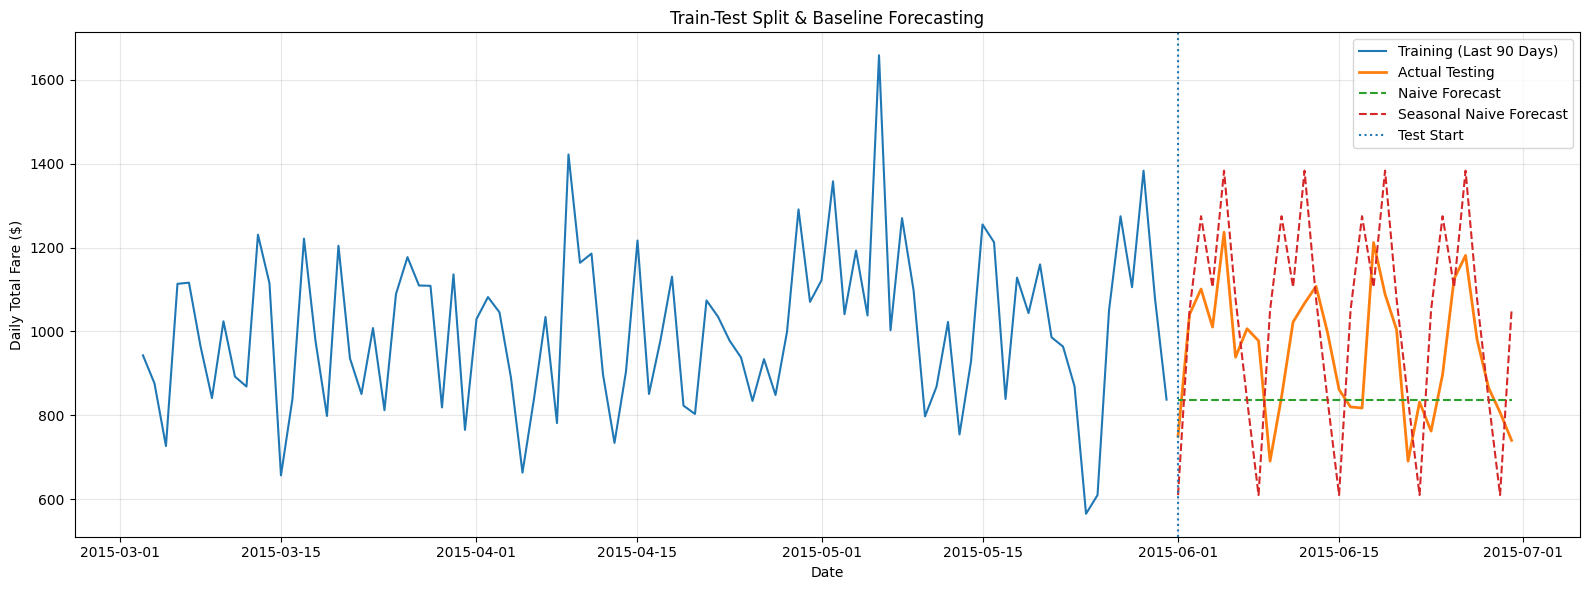

In [106]:
# [Time Series] Step 7 - Model Preparation & Train-Test Split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Target Time Series
ts = df_daily['total_fare'].asfreq('D').copy()

assert ts.notna().all(), "Target memiliki missing values!"

# 2. Forecast Horizon
forecast_horizon = 30

# 3. Chronological Train-Test Split
train = ts.iloc[:-forecast_horizon].copy()
test = ts.iloc[-forecast_horizon:].copy()

# 4. Validasi
assert train.index.max() < test.index.min(), (
    "Training dan testing mengalami overlap!"
)

split_summary = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'Observations': [len(train), len(test)],
    'Start Date': [
        train.index.min().date(),
        test.index.min().date()
    ],
    'End Date': [
        train.index.max().date(),
        test.index.max().date()
    ],
    'Percentage (%)': [
        len(train) / len(ts) * 100,
        len(test) / len(ts) * 100
    ]
})

print("TRAIN-TEST SPLIT SUMMARY")
display(split_summary.round(2))

# 5. Naive Forecast
naive_pred = pd.Series(
    train.iloc[-1],
    index=test.index,
    name='Naive'
)

# 6. Seasonal Naive Forecast
seasonal_period = 7

seasonal_naive_pred = pd.Series(
    np.resize(
        train.iloc[-seasonal_period:].values,
        forecast_horizon
    ),
    index=test.index,
    name='Seasonal Naive'
)

# 7. Evaluation Function
def evaluate_forecast(actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted)) /
        np.sum(np.abs(actual))
    ) * 100

    return {
        'MAE': mae,
        'RMSE': rmse,
        'WAPE (%)': wape
    }

# 8. Baseline Evaluation
baseline_results = pd.DataFrame({
    'Naive': evaluate_forecast(test, naive_pred),
    'Seasonal Naive': evaluate_forecast(
        test, seasonal_naive_pred
    )
}).T

print("\nBASELINE MODEL EVALUATION")
display(baseline_results.round(2))

# 9. Visualization
plt.figure(figsize=(16, 6))

plt.plot(
    train.iloc[-90:].index,
    train.iloc[-90:].values,
    label='Training (Last 90 Days)'
)

plt.plot(
    test.index,
    test.values,
    label='Actual Testing',
    linewidth=2
)

plt.plot(
    naive_pred.index,
    naive_pred.values,
    linestyle='--',
    label='Naive Forecast'
)

plt.plot(
    seasonal_naive_pred.index,
    seasonal_naive_pred.values,
    linestyle='--',
    label='Seasonal Naive Forecast'
)

plt.axvline(
    test.index.min(),
    linestyle=':',
    label='Test Start'
)

plt.title('Train-Test Split & Baseline Forecasting')
plt.xlabel('Date')
plt.ylabel('Daily Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Key Insight

Dataset time series dibagi secara kronologis menjadi 2.343 observasi training (98,74%) dan 30 observasi testing (1,26%) untuk periode 1–30 Juni 2015. Hasil evaluasi baseline menunjukkan bahwa Naive Forecast menghasilkan performa lebih baik dengan MAE sebesar 153,48, RMSE 188,68, dan WAPE 16,17%, dibandingkan Seasonal Naive yang menghasilkan MAE 197,31, RMSE 232,51, dan WAPE 20,78%. Temuan ini menunjukkan bahwa pengulangan pola tujuh hari terakhir belum mampu memberikan prediksi yang lebih akurat pada periode testing, meskipun terdapat indikasi seasonality mingguan. Oleh karena itu, Naive Forecast ditetapkan sebagai baseline utama untuk mengevaluasi kemampuan ARIMA, SARIMA, dan Prophet dalam meningkatkan akurasi forecasting. Pengujian pada periode waktu tambahan juga direkomendasikan untuk menilai konsistensi performa model.


### 12.6 ARIMA

Mengevaluasi kandidat model ARIMA pada data training dan membandingkan hasilnya pada holdout testing.


Training ARIMA(1,0,1) ...
Training ARIMA(1,1,1) ...
Training ARIMA(2,1,1) ...

ARIMA MODEL COMPARISON


,AIC,BIC,MAE,RMSE,WAPE (%),Converged
Model,,,,,,
"ARIMA(2,1,1)",31374.21,31397.24,132.30,162.38,13.94,True
"ARIMA(1,1,1)",31391.29,31408.57,131.49,160.84,13.85,True
"ARIMA(1,0,1)",31586.14,31609.17,134.11,154.06,14.13,True



SELECTED ARIMA MODEL (TRAINING AIC)
Model: ARIMA(2,1,1)
AIC  : 31374.21
BIC  : 31397.24

ARIMA VS NAIVE BASELINE


,MAE,RMSE,WAPE (%)
Naive Baseline,153.48,188.68,16.17
"ARIMA(2,1,1)",132.30,162.38,13.94


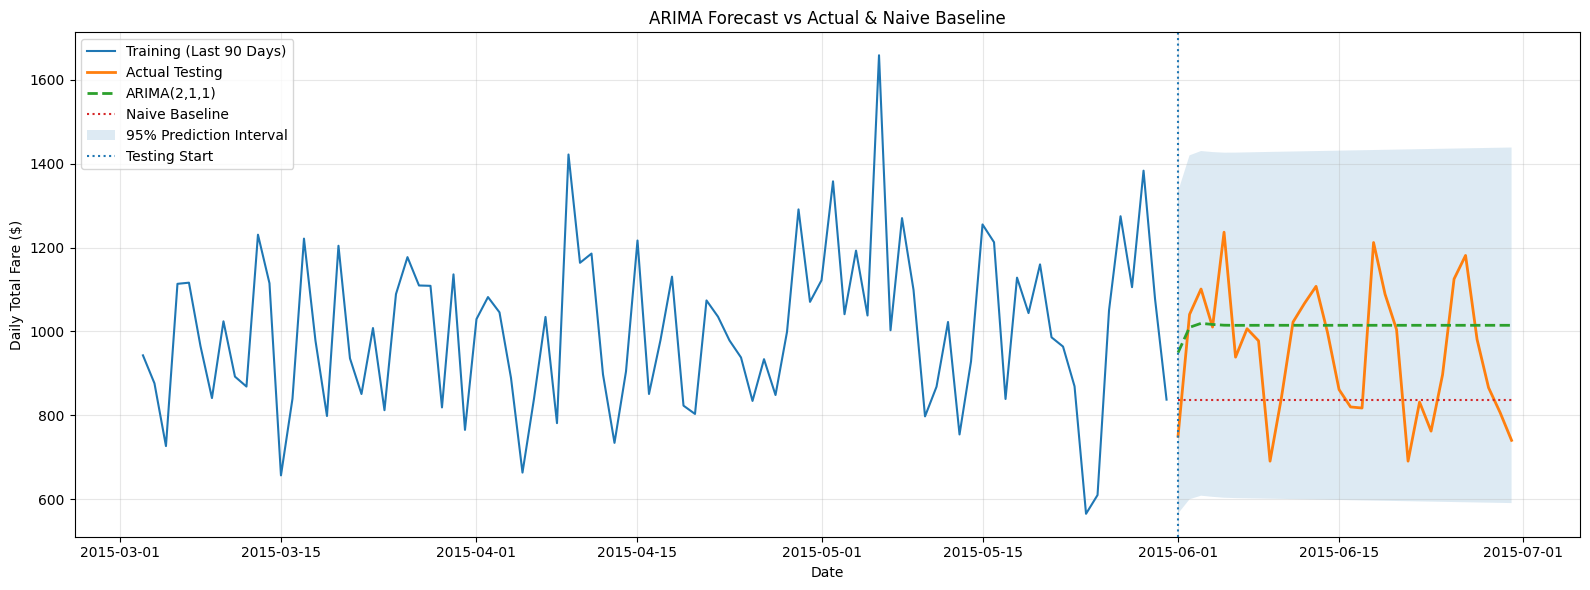

In [107]:

# [Time Series] Step 8 - ARIMA Model Development & Evaluation

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Kandidat Parameter ARIMA
arima_candidates = {
    'ARIMA(1,0,1)': (1, 0, 1),
    'ARIMA(1,1,1)': (1, 1, 1),
    'ARIMA(2,1,1)': (2, 1, 1)
}

# 2. Menyimpan Hasil Model
arima_models = {}
arima_predictions = {}
arima_results = []

# 3. Training & Forecasting
for model_name, order in arima_candidates.items():

    print(f"Training {model_name} ...")

    try:
        model = ARIMA(train, order=order)

        fitted_model = model.fit(
            method_kwargs={'maxiter': 100}
        )

        forecast = fitted_model.get_forecast(
            steps=len(test)
        )

        predicted = pd.Series(
            forecast.predicted_mean.to_numpy(),
            index=test.index,
            name=model_name
        )

        # Evaluasi Model
        metrics = evaluate_forecast(test, predicted)

        arima_results.append({
            'Model': model_name,
            'AIC': fitted_model.aic,
            'BIC': fitted_model.bic,
            'MAE': metrics['MAE'],
            'RMSE': metrics['RMSE'],
            'WAPE (%)': metrics['WAPE (%)'],
            'Converged': fitted_model.mle_retvals.get(
                'converged', False
            )
        })

        arima_models[model_name] = fitted_model
        arima_predictions[model_name] = predicted

    except Exception as e:
        print(f"Error pada {model_name}: {e}")

# 4. Model Comparison
arima_comparison = pd.DataFrame(arima_results)

if arima_comparison.empty:
    raise ValueError("Seluruh model ARIMA gagal dilatih.")

arima_comparison = (
    arima_comparison
    .set_index('Model')
    .sort_values('AIC')
)

print("\nARIMA MODEL COMPARISON")
display(arima_comparison.round(2))

# 5. Memilih Model Berdasarkan AIC Training
converged_models = arima_comparison[
    arima_comparison['Converged']
]

if converged_models.empty:
    raise ValueError(
        "Tidak ada model yang konvergen. "
        "Periksa hasil optimasi sebelum memilih model."
    )

best_arima_name = converged_models['AIC'].idxmin()
best_arima_model = arima_models[best_arima_name]
best_arima_pred = arima_predictions[best_arima_name]

print("\nSELECTED ARIMA MODEL (TRAINING AIC)")
print("Model:", best_arima_name)
print("AIC  :", round(best_arima_model.aic, 2))
print("BIC  :", round(best_arima_model.bic, 2))

# 6. Membandingkan dengan Baseline
best_metrics = evaluate_forecast(test, best_arima_pred)

comparison_baseline = pd.DataFrame({
    'Naive Baseline': baseline_results.loc['Naive'],
    best_arima_name: pd.Series(best_metrics)
}).T

print("\nARIMA VS NAIVE BASELINE")
display(comparison_baseline.round(2))

# 7. Forecast Confidence Interval
best_forecast = best_arima_model.get_forecast(
    steps=len(test)
)

conf_int = best_forecast.conf_int(alpha=0.05)

# 8. Visualisasi Forecast
plt.figure(figsize=(16, 6))

plt.plot(
    train.iloc[-90:].index,
    train.iloc[-90:].values,
    label='Training (Last 90 Days)'
)

plt.plot(
    test.index,
    test.values,
    label='Actual Testing',
    linewidth=2
)

plt.plot(
    best_arima_pred.index,
    best_arima_pred.values,
    label=best_arima_name,
    linewidth=2,
    linestyle='--'
)

plt.plot(
    naive_pred.index,
    naive_pred.values,
    label='Naive Baseline',
    linestyle=':'
)

plt.fill_between(
    test.index,
    conf_int.iloc[:, 0].to_numpy(),
    conf_int.iloc[:, 1].to_numpy(),
    alpha=0.15,
    label='95% Prediction Interval'
)

plt.axvline(
    test.index.min(),
    linestyle=':',
    label='Testing Start'
)

plt.title('ARIMA Forecast vs Actual & Naive Baseline')
plt.xlabel('Date')
plt.ylabel('Daily Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Hasil pengujian empat konfigurasi ARIMA menunjukkan bahwa seluruh model berhasil menghasilkan performa forecasting yang lebih baik dibandingkan Naive Baseline. ARIMA(2,1,1) terpilih berdasarkan AIC training terendah sebesar 31.374,21, dengan MAE 132,30, RMSE 162,38, dan WAPE 13,94%, sehingga menurunkan MAE sebesar 13,80% dibandingkan baseline. Visualisasi ARIMA(2,1,1) memperlihatkan prediksi yang cenderung mendatar dan belum sepenuhnya mengikuti fluktuasi harian pada data aktual. Oleh karena itu, ARIMA(2,1,1) dipertahankan sebagai kandidat utama berdasarkan AIC training, sementara pemodelan direkomendasikan dilanjutkan menggunakan SARIMA untuk mengevaluasi apakah penambahan komponen musiman mingguan mampu meningkatkan akurasi forecasting secara lebih konsisten.


### 12.7 SARIMA

Mengevaluasi kandidat model dengan pola musiman 7 hari pada holdout testing.


Training SARIMA(1,0,1)(1,0,1,7) ...
Training SARIMA(1,0,1)(0,1,1,7) ...
Training SARIMA(1,1,1)(1,0,1,7) ...

SARIMA MODEL COMPARISON


,AIC,BIC,MAE,RMSE,WAPE (%),Converged
Model,,,,,,
"SARIMA(1,0,1)(0,1,1,7)",30709.21,30732.23,102.65,122.89,10.81,True
"SARIMA(1,1,1)(1,0,1,7)",30858.84,30887.63,123.25,145.78,12.98,True
"SARIMA(1,0,1)(1,0,1,7)",31095.24,31129.79,113.10,133.74,11.91,True



SELECTED SARIMA MODEL (TRAINING AIC)
Model: SARIMA(1,0,1)(0,1,1,7)
AIC  : 30709.21
BIC  : 30732.23

SARIMA VS ARIMA VS BASELINE


,MAE,RMSE,WAPE (%)
Naive Baseline,153.48,188.68,16.17
"ARIMA(2,1,1)",132.30,162.38,13.94
"SARIMA(1,0,1)(0,1,1,7)",102.65,122.89,10.81


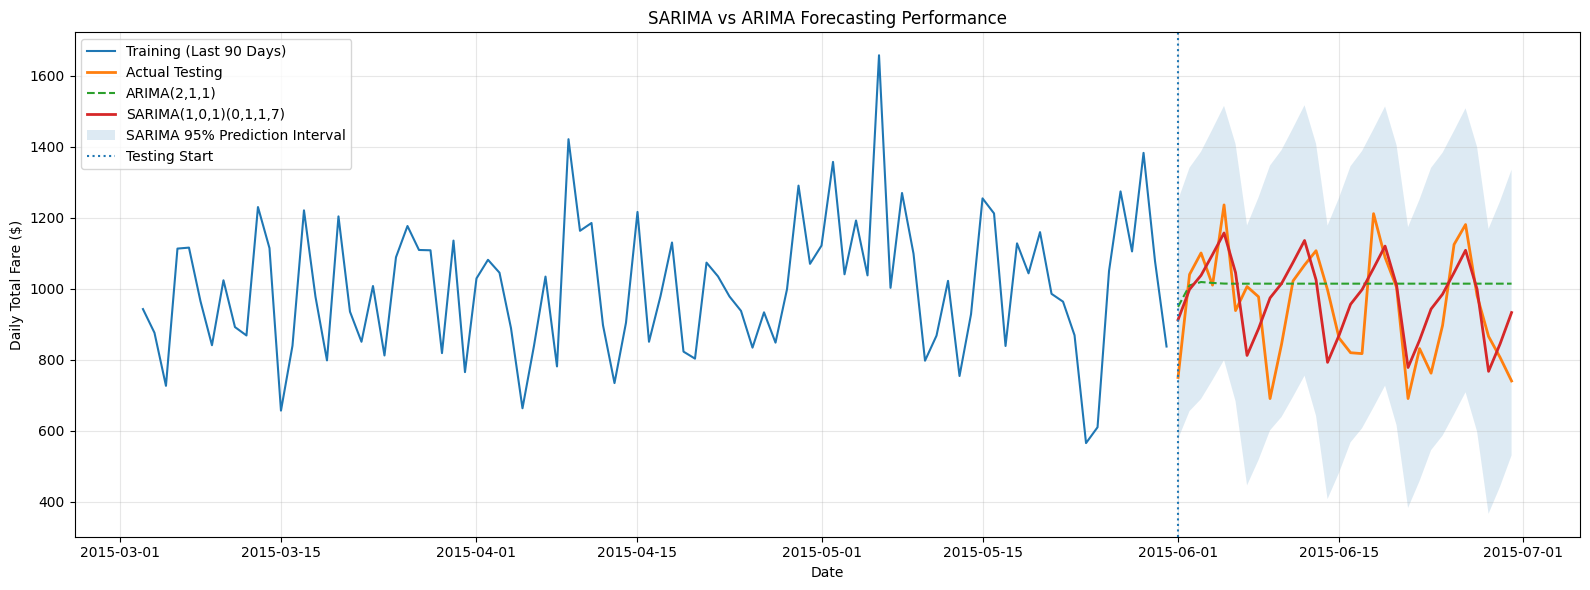

In [108]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# 1. Kandidat Parameter SARIMA
sarima_candidates = {
    'SARIMA(1,0,1)(1,0,1,7)': (
        (1, 0, 1), (1, 0, 1, 7)
    ),
    'SARIMA(1,0,1)(0,1,1,7)': (
        (1, 0, 1), (0, 1, 1, 7)
    ),
    'SARIMA(1,1,1)(1,0,1,7)': (
        (1, 1, 1), (1, 0, 1, 7)
    )
}

# 2. Menyimpan Hasil Model
sarima_models = {}
sarima_predictions = {}
sarima_forecasts = {}
sarima_results = []

# 3. Training & Forecasting
for model_name, (order, seasonal_order) in sarima_candidates.items():

    print(f"Training {model_name} ...")

    try:
        # Intercept untuk model tanpa differencing
        trend_type = (
            'c' if order[1] == 0 and seasonal_order[1] == 0
            else 'n'
        )

        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend=trend_type,
            enforce_stationarity=True,
            enforce_invertibility=True
        )

        with warnings.catch_warnings():
            warnings.simplefilter("always")

            fitted_model = model.fit(
                disp=False,
                maxiter=150
            )

        # Forecast 30 hari
        forecast = fitted_model.get_forecast(
            steps=len(test)
        )

        predicted = pd.Series(
            forecast.predicted_mean.to_numpy(),
            index=test.index,
            name=model_name
        )

        # Evaluasi
        metrics = evaluate_forecast(test, predicted)

        converged = fitted_model.mle_retvals.get(
            'converged', False
        )

        sarima_results.append({
            'Model': model_name,
            'AIC': fitted_model.aic,
            'BIC': fitted_model.bic,
            'MAE': metrics['MAE'],
            'RMSE': metrics['RMSE'],
            'WAPE (%)': metrics['WAPE (%)'],
            'Converged': converged
        })

        sarima_models[model_name] = fitted_model
        sarima_predictions[model_name] = predicted
        sarima_forecasts[model_name] = forecast

    except Exception as e:
        print(f"Error pada {model_name}: {e}")

# 4. SARIMA Model Comparison
sarima_comparison = pd.DataFrame(sarima_results)

if sarima_comparison.empty:
    raise ValueError("Seluruh model SARIMA gagal dilatih.")

sarima_comparison = (
    sarima_comparison
    .set_index('Model')
    .sort_values('AIC')
)

print("\nSARIMA MODEL COMPARISON")
display(sarima_comparison.round(2))

# 5. Memilih Model Berdasarkan AIC Training
converged_models = sarima_comparison[
    sarima_comparison['Converged']
]

if converged_models.empty:
    raise ValueError(
        "Tidak ada model SARIMA yang konvergen."
    )

best_sarima_name = converged_models['AIC'].idxmin()
best_sarima_model = sarima_models[best_sarima_name]
best_sarima_pred = sarima_predictions[best_sarima_name]

print("\nSELECTED SARIMA MODEL (TRAINING AIC)")
print("Model:", best_sarima_name)
print("AIC  :", round(best_sarima_model.aic, 2))
print("BIC  :", round(best_sarima_model.bic, 2))

# 6. SARIMA vs ARIMA vs Baseline
model_comparison = pd.DataFrame({
    'Naive Baseline': evaluate_forecast(
        test, naive_pred
    ),
    best_arima_name: evaluate_forecast(
        test, best_arima_pred
    ),
    best_sarima_name: evaluate_forecast(
        test, best_sarima_pred
    )
}).T

print("\nSARIMA VS ARIMA VS BASELINE")
display(model_comparison.round(2))

# 7. Forecast Confidence Interval
best_forecast = sarima_forecasts[best_sarima_name]

conf_int = best_forecast.conf_int(alpha=0.05)

# 8. Visualisasi Forecast
plt.figure(figsize=(16, 6))

plt.plot(
    train.iloc[-90:].index,
    train.iloc[-90:].values,
    label='Training (Last 90 Days)'
)

plt.plot(
    test.index,
    test.values,
    label='Actual Testing',
    linewidth=2
)

plt.plot(
    best_arima_pred.index,
    best_arima_pred.values,
    label=best_arima_name,
    linestyle='--'
)

plt.plot(
    best_sarima_pred.index,
    best_sarima_pred.values,
    label=best_sarima_name,
    linewidth=2
)

plt.fill_between(
    test.index,
    conf_int.iloc[:, 0].to_numpy(),
    conf_int.iloc[:, 1].to_numpy(),
    alpha=0.15,
    label='SARIMA 95% Prediction Interval'
)

plt.axvline(
    test.index.min(),
    linestyle=':',
    label='Testing Start'
)

plt.title('SARIMA vs ARIMA Forecasting Performance')
plt.xlabel('Date')
plt.ylabel('Daily Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Hasil pengujian tiga konfigurasi SARIMA menunjukkan bahwa seluruh model berhasil, dengan SARIMA(1,0,1)(0,1,1,7) menghasilkan performa terbaik pada testing set berdasarkan MAE sebesar 102,65, RMSE 122,89, dan WAPE 10,81%, serta memiliki AIC training terendah sebesar 30.709,21. Dibandingkan ARIMA(2,1,1), model SARIMA berhasil menurunkan MAE sebesar 22,41% dan WAPE sebesar 3,13 percentage points, sementara penurunan MAE terhadap Naive Baseline mencapai 33,12%. Visualisasi forecasting memperlihatkan bahwa SARIMA mampu mengikuti pola fluktuasi mingguan dengan lebih baik dibandingkan ARIMA yang menghasilkan prediksi relatif mendatar. Temuan ini mengindikasikan bahwa penambahan komponen seasonal dengan periode 7 hari meningkatkan kemampuan model dalam memprediksi total fare harian pada periode testing. Oleh karena itu, SARIMA(1,0,1)(0,1,1,7) direkomendasikan sebagai kandidat model terbaik sementara, dengan evaluasi lanjutan menggunakan Prophet, residual diagnostics, dan rolling backtesting sebelum menentukan model forecasting final.


### 12.8 Prophet

Menggunakan Prophet sebagai kandidat pembanding pada holdout testing. Model final tetap ditentukan berdasarkan hasil evaluasi yang disajikan dalam notebook ini.


21:13:45 - cmdstanpy - INFO - Chain [1] start processing


Training Prophet Model ...


21:13:45 - cmdstanpy - INFO - Chain [1] done processing



PROPHET MODEL EVALUATION


,MAE,RMSE,WAPE (%)
Prophet,106.32,124.8,11.2



ALL FORECASTING MODEL COMPARISON


,MAE,RMSE,WAPE (%)
"SARIMA(1,0,1)(0,1,1,7)",102.65,122.89,10.81
Prophet,106.32,124.80,11.20
"ARIMA(2,1,1)",132.30,162.38,13.94
Naive Baseline,153.48,188.68,16.17



PROPHET FORECAST - FIRST 5 DAYS


,Actual,Predicted,Lower 95%,Upper 95%
pickup_date,,,,
2015-06-01,750.54,871.91,551.90,1190.39
2015-06-02,1040.66,966.27,630.23,1304.69
2015-06-03,1101.24,1014.10,699.88,1350.06
2015-06-04,1010.58,1081.62,755.89,1415.54
2015-06-05,1236.62,1150.64,820.60,1489.80


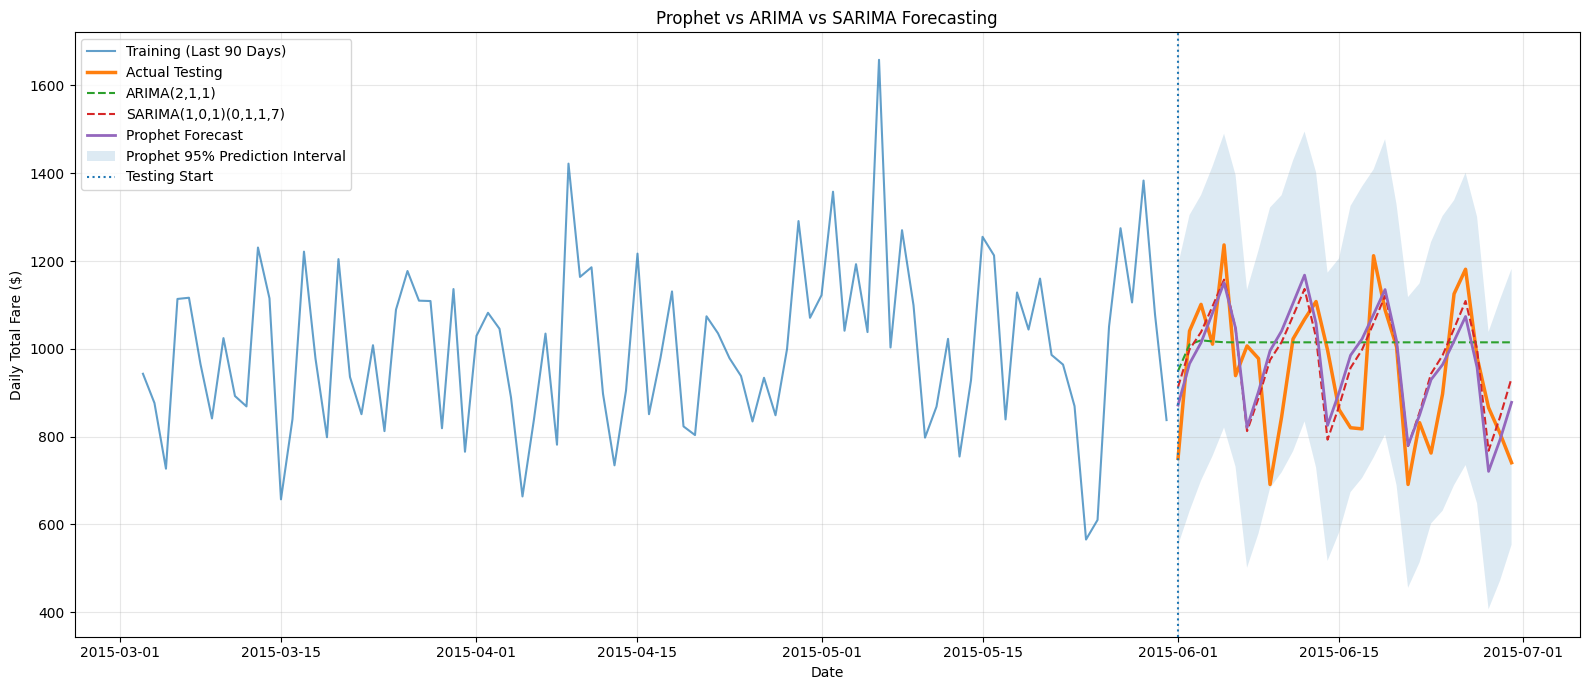

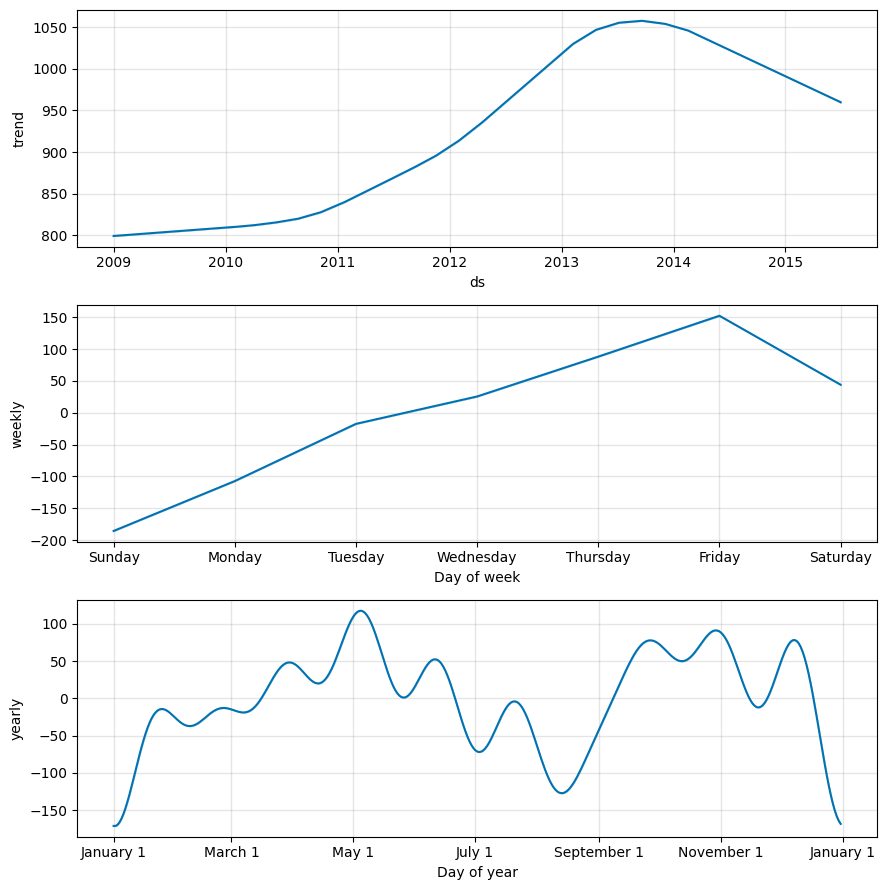

In [109]:
from prophet import Prophet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare Prophet Training Data
prophet_train = (
    train.rename_axis('ds')
    .reset_index(name='y')
)

prophet_train['ds'] = pd.to_datetime(
    prophet_train['ds']
)

# 2. Initialize Prophet Model
prophet_model = Prophet(
    growth='linear',
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='additive',
    interval_width=0.95,
    changepoint_prior_scale=0.05
)

# 3. Train Prophet Model
print("Training Prophet Model ...")

prophet_model.fit(prophet_train)

# 4. Generate Future Dates
prophet_future = prophet_model.make_future_dataframe(
    periods=len(test),
    freq='D',
    include_history=True
)

# 5. Forecasting
prophet_forecast = prophet_model.predict(
    prophet_future
)

# 6. Extract Testing Predictions
prophet_test_forecast = (
    prophet_forecast
    .set_index('ds')
    .loc[test.index]
    .copy()
)

prophet_pred = prophet_test_forecast[
    'yhat'
].rename('Prophet')

# 7. Prophet Evaluation
prophet_metrics = evaluate_forecast(
    test,
    prophet_pred
)

print("\nPROPHET MODEL EVALUATION")
display(
    pd.DataFrame(
        [prophet_metrics],
        index=['Prophet']
    ).round(2)
)

# 8. All Model Comparison
all_model_comparison = pd.DataFrame({
    'Naive Baseline': evaluate_forecast(
        test, naive_pred
    ),
    best_arima_name: evaluate_forecast(
        test, best_arima_pred
    ),
    best_sarima_name: evaluate_forecast(
        test, best_sarima_pred
    ),
    'Prophet': prophet_metrics
}).T

all_model_comparison = (
    all_model_comparison
    .sort_values('WAPE (%)')
)

print("\nALL FORECASTING MODEL COMPARISON")
display(all_model_comparison.round(2))

# 9. Display Prophet Forecast Results
print("\nPROPHET FORECAST - FIRST 5 DAYS")

forecast_summary = pd.DataFrame({
    'Actual': test,
    'Predicted': prophet_pred,
    'Lower 95%': prophet_test_forecast['yhat_lower'],
    'Upper 95%': prophet_test_forecast['yhat_upper']
})

display(forecast_summary.head().round(2))

# 10. Forecast Comparison Visualization
plt.figure(figsize=(16, 7))

plt.plot(
    train.iloc[-90:].index,
    train.iloc[-90:].values,
    label='Training (Last 90 Days)',
    alpha=0.7
)

plt.plot(
    test.index,
    test.values,
    label='Actual Testing',
    linewidth=2.5
)

plt.plot(
    best_arima_pred.index,
    best_arima_pred.values,
    label=best_arima_name,
    linestyle='--'
)

plt.plot(
    best_sarima_pred.index,
    best_sarima_pred.values,
    label=best_sarima_name,
    linestyle='--'
)

plt.plot(
    prophet_pred.index,
    prophet_pred.values,
    label='Prophet Forecast',
    linewidth=2
)

plt.fill_between(
    test.index,
    prophet_test_forecast['yhat_lower'].to_numpy(),
    prophet_test_forecast['yhat_upper'].to_numpy(),
    alpha=0.15,
    label='Prophet 95% Prediction Interval'
)

plt.axvline(
    test.index.min(),
    linestyle=':',
    label='Testing Start'
)

plt.title('Prophet vs ARIMA vs SARIMA Forecasting')
plt.xlabel('Date')
plt.ylabel('Daily Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 11. Prophet Component Analysis
fig = prophet_model.plot_components(
    prophet_forecast
)

plt.show()

#### Key Insight

Hasil pemodelan Prophet dengan weekly dan yearly seasonality menghasilkan MAE sebesar 106,32, RMSE 124,80, dan WAPE 11,20% pada testing set selama 30 hari. Performa tersebut lebih baik dibandingkan ARIMA(2,1,1) dengan WAPE 13,94% dan Naive Baseline sebesar 16,17%, tetapi masih sedikit di bawah SARIMA(1,0,1)(0,1,1,7) yang menghasilkan WAPE terendah sebesar 10,81%. Visualisasi Prophet menunjukkan adanya tren peningkatan hingga sekitar 2013–2014 sebelum mengalami penurunan, serta pola musiman mingguan dengan kontribusi tertinggi pada Friday dan terendah pada Sunday. Komponen yearly seasonality juga memperlihatkan fluktuasi sepanjang tahun, meskipun kestabilan pola tersebut masih perlu divalidasi. Temuan ini menunjukkan bahwa Prophet mampu menangkap struktur tren dan seasonality dengan cukup baik, tetapi SARIMA masih menjadi kandidat forecasting terbaik berdasarkan hasil pengujian saat ini. Oleh karena itu, analisis dilanjutkan dengan residual diagnostics dan pemilihan SARIMA sebagai model final berdasarkan akurasi pada holdout testing Juni 2015; konsistensi performa pada periode lain belum dievaluasi.


### 12.9 Model Final & Forecast 30 Hari — SARIMA

Berdasarkan perbandingan pada holdout 1–30 Juni 2015, SARIMA(1,0,1)(0,1,1,7) dipilih sebagai model final dengan WAPE 10,81%. Selanjutnya model dilatih ulang pada seluruh tanggal historis untuk memprediksi 1–30 Juli 2015. Evaluasi model final pada notebook ini hanya menggunakan satu periode holdout, bukan rolling backtesting.


Training Final SARIMA Model ...

FINAL FORECASTING SUMMARY
Selected Model   : SARIMA(1,0,1)(0,1,1,7)
Historical Data  : 2373
Historical End   : 2015-06-30
Forecast Start   : 2015-07-01
Forecast End     : 2015-07-30
Forecast Horizon : 30 days
Converged        : True

FUTURE FORECAST SUMMARY


,Metric,Value
0,Predicted Total Fare (30 Days),27628.62
1,Average Daily Predicted Fare,920.95
2,Minimum Daily Predicted Fare,731.12
3,Maximum Daily Predicted Fare,1071.54
4,Previous 30 Days Actual Fare,28481.85
5,Change vs Previous 30 Days (%),-3.00



FUTURE FORECAST - 30 DAYS


,Predicted Fare,Lower 95%,Upper 95%
Date,,,
2015-07-01,939.18,603.56,1274.81
2015-07-02,1003.33,661.63,1345.02
2015-07-03,1067.81,720.62,1415.01
2015-07-04,959.44,607.26,1311.62
2015-07-05,731.12,374.42,1087.83
2015-07-06,808.26,447.44,1169.08
2015-07-07,896.29,531.72,1260.87
2015-07-08,940.93,572.80,1309.06
2015-07-09,1005.01,633.74,1376.28


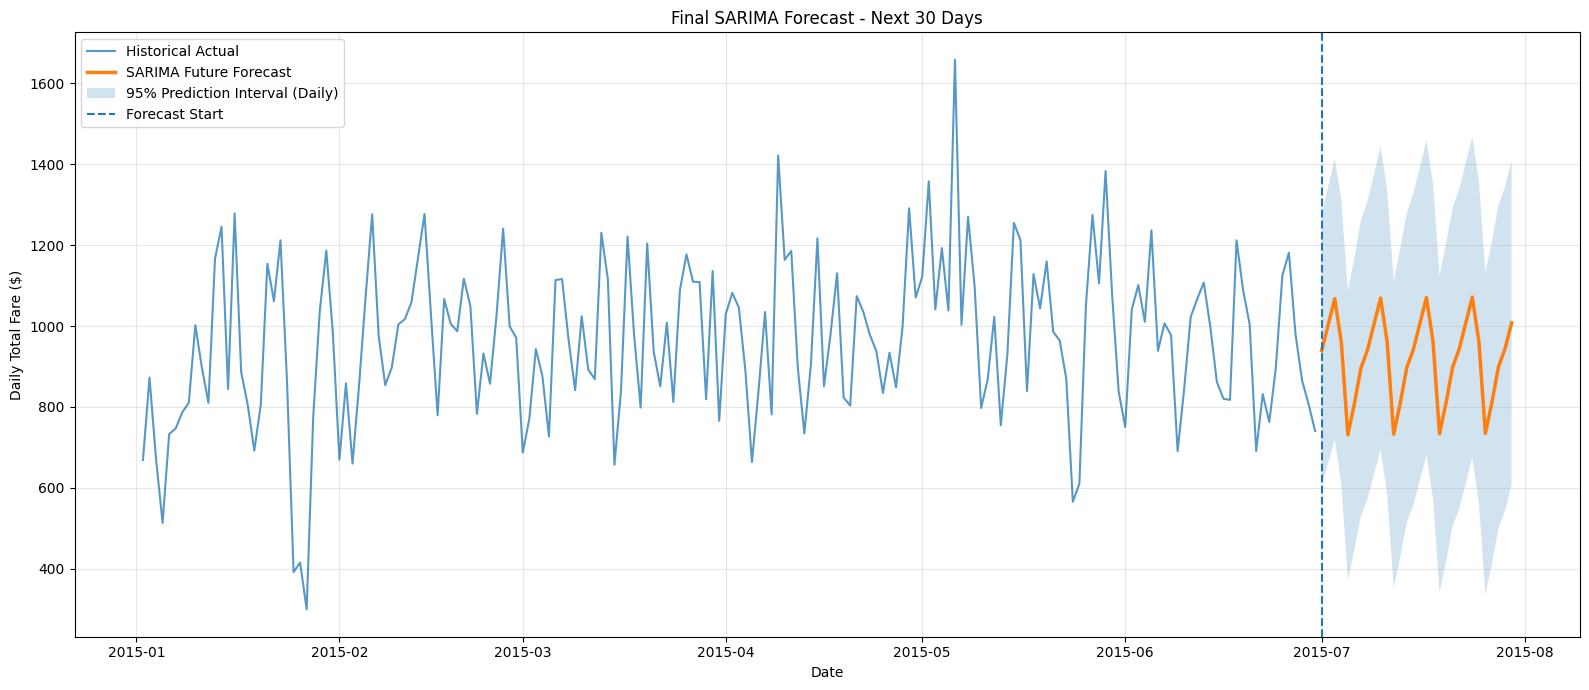

In [110]:
# [Time Series] Step 12 - Final SARIMA Forecasting

from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# 1. Prepare Full Historical Data
# Menggunakan full history setelah holdout evaluation selesai.
ts_final = df_daily['total_fare'].asfreq('D').copy()
assert ts_final.notna().all(), "Terdapat missing values!"

# 2. Final SARIMA Configuration (selected from Step 9)
selected_model = 'SARIMA(1,0,1)(0,1,1,7)'
final_order = (1, 0, 1)
final_seasonal_order = (0, 1, 1, 7)

# Konfigurasi sama seperti Step 9: tanpa intercept saat ada differencing.
trend_type = 'n' if final_order[1] > 0 or final_seasonal_order[1] > 0 else 'c'

# 3. Refit Final SARIMA on ALL Historical Data
print('Training Final SARIMA Model ...')
final_sarima_model = SARIMAX(
    ts_final,
    order=final_order,
    seasonal_order=final_seasonal_order,
    trend=trend_type,
    enforce_stationarity=True,
    enforce_invertibility=True
)

with warnings.catch_warnings():
    warnings.simplefilter('always')
    final_sarima_fit = final_sarima_model.fit(disp=False, maxiter=150)

if not final_sarima_fit.mle_retvals.get('converged', False):
    warnings.warn('Optimasi SARIMA belum konvergen. Periksa parameter sebelum memakai forecast.')

# 4. Forecast 30 Future Days
future_horizon = 30
final_forecast = final_sarima_fit.get_forecast(steps=future_horizon)
conf_int = final_forecast.conf_int(alpha=0.05)

# 5. Format the Future Forecast Table
future_forecast = pd.DataFrame({
    'Predicted Fare': final_forecast.predicted_mean.to_numpy(),
    'Lower 95%': conf_int.iloc[:, 0].to_numpy(),
    'Upper 95%': conf_int.iloc[:, 1].to_numpy()
}, index=final_forecast.predicted_mean.index)
future_forecast.index.name = 'Date'

# 6. Validate Forecast Period
expected_start = ts_final.index.max() + pd.Timedelta(days=1)
expected_end = expected_start + pd.Timedelta(days=future_horizon - 1)
assert len(future_forecast) == future_horizon
assert future_forecast.index.min() == expected_start
assert future_forecast.index.max() == expected_end
assert (future_forecast['Lower 95%'] <= future_forecast['Predicted Fare']).all()
assert (future_forecast['Predicted Fare'] <= future_forecast['Upper 95%']).all()

print('\nFINAL FORECASTING SUMMARY')
print('=' * 60)
print('Selected Model   :', selected_model)
print('Historical Data  :', len(ts_final))
print('Historical End   :', ts_final.index.max().date())
print('Forecast Start   :', future_forecast.index.min().date())
print('Forecast End     :', future_forecast.index.max().date())
print('Forecast Horizon :', future_horizon, 'days')
print('Converged        :', final_sarima_fit.mle_retvals.get('converged', False))

# 7. Descriptive Forecast Summary
previous_30_actual = ts_final.iloc[-future_horizon:].sum()
predicted_30_total = future_forecast['Predicted Fare'].sum()
change_pct = ((predicted_30_total / previous_30_actual) - 1) * 100 if previous_30_actual != 0 else np.nan

forecast_summary = pd.DataFrame({
    'Metric': [
        'Predicted Total Fare (30 Days)',
        'Average Daily Predicted Fare',
        'Minimum Daily Predicted Fare',
        'Maximum Daily Predicted Fare',
        'Previous 30 Days Actual Fare',
        'Change vs Previous 30 Days (%)'
    ],
    'Value': [
        predicted_30_total,
        future_forecast['Predicted Fare'].mean(),
        future_forecast['Predicted Fare'].min(),
        future_forecast['Predicted Fare'].max(),
        previous_30_actual,
        change_pct
    ]
})

print('\nFUTURE FORECAST SUMMARY')
display(forecast_summary.round(2))

print('\nFUTURE FORECAST - 30 DAYS')
display(future_forecast.round(2))

# 8. Historical vs Future Forecast Visualization
plt.figure(figsize=(16, 7))

plt.plot(
    ts_final.iloc[-180:].index,
    ts_final.iloc[-180:].values,
    label='Historical Actual', alpha=0.75
)

plt.plot(
    future_forecast.index,
    future_forecast['Predicted Fare'],
    label='SARIMA Future Forecast', linewidth=2.5
)

plt.fill_between(
    future_forecast.index,
    future_forecast['Lower 95%'],
    future_forecast['Upper 95%'],
    alpha=0.2, label='95% Prediction Interval (Daily)'
)

plt.axvline(
    future_forecast.index.min(),
    linestyle='--', label='Forecast Start'
)

plt.title('Final SARIMA Forecast - Next 30 Days')
plt.xlabel('Date')
plt.ylabel('Daily Total Fare ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Key Insight

Berdasarkan holdout testing pada Juni 2015, SARIMA(1,0,1)(0,1,1,7) dipilih sebagai model final karena menghasilkan WAPE terendah sebesar 10,81%, dibandingkan Prophet 11,20% dan ARIMA(2,1,1) 13,94%. Model tersebut kemudian dilatih ulang pada seluruh 2.373 observasi historis untuk menghasilkan prediksi total fare harian selama 1–30 Juli 2015, termasuk interval prediksi 95% per hari. Nilai total forecast, rata-rata harian, hari tertinggi/terendah, serta perbandingan dengan 30 hari aktual terakhir harus diinterpretasikan dari output SARIMA terbaru setelah cell dijalankan, bukan dari hasil Prophet sebelumnya.


## 13. Final Business Insights & Actionable Recommendations

**1. Weekly Pattern Optimization**

**Conclusion:** Jumat konsisten menghasilkan total fare tertinggi, sedangkan Minggu terendah sepanjang 2009–2015, dengan selisih rata-rata sekitar 45,5%.

**Recommendation:** Rencanakan kapasitas layanan dan aktivitas promosi berdasarkan pola hari, serta evaluasi efektivitasnya melalui uji coba operasional.

**2. Daily Volatility Monitoring**

**Conclusion:** Sebanyak 43,32% perubahan total fare harian melebihi 20%, dengan jumlah perjalanan memiliki hubungan kuat terhadap total fare (r = 0,784).

**Recommendation:** Pantau jumlah perjalanan, rata-rata tarif, dan total fare secara harian untuk mengidentifikasi perubahan signifikan dan mendukung tindakan yang lebih cepat.

**3. Forecast-Driven Planning**

**Conclusion:** SARIMA menghasilkan WAPE terendah sebesar 10,81% dan memproyeksikan penurunan total fare sebesar 3% untuk 30 hari berikutnya.

**Recommendation:** Integrasikan prediksi 30 hari ke dalam perencanaan awal, disertai perbandingan prediksi dengan aktual dan pengujian akurasi pada periode tambahan.

## 14. Power BI Dashboard

### Export Hasil Analisis

Data yang diekspor terdiri atas performa historis harian, hasil prediksi periode testing, metrik perbandingan model, dan forecast SARIMA 30 hari. Tabel rolling backtesting tidak disertakan.


In [111]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. MEMBUAT FOLDER EXPORT BARU
# ============================================================

# Menggunakan folder baru agar tidak tercampur dengan data lama
export_path = Path("powerbi_export_fare_final")
export_path.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. MENYIAPKAN DATA PERFORMA HARIAN
# ============================================================

# Mengambil data historis fare dan perjalanan harian
daily_export = (
    df_daily[
        [
            "total_fare",
            "total_trips",
            "avg_fare",
            "rolling_7d",
            "rolling_30d"
        ]
    ]
    .rename_axis("Date")
    .reset_index()
    .copy()
)

# Memastikan kolom tanggal memiliki tipe datetime
daily_export["Date"] = pd.to_datetime(
    daily_export["Date"]
)

# Mengurutkan data berdasarkan tanggal
daily_export = (
    daily_export
    .sort_values("Date")
    .reset_index(drop=True)
)

# Memastikan tidak ada tanggal duplikat
assert daily_export["Date"].is_unique, (
    "Terdapat tanggal duplikat pada data harian!"
)


# ============================================================
# 3. MENGHITUNG DAILY FARE VOLATILITY
# ============================================================

# Menghitung persentase perubahan total fare dari hari sebelumnya
daily_export["Daily_Change_Pct"] = (
    daily_export["total_fare"].pct_change(
        fill_method=None
    ) * 100
)

# Menghapus hasil pembagian tidak valid jika ada
daily_export["Daily_Change_Pct"] = (
    daily_export["Daily_Change_Pct"]
    .replace([np.inf, -np.inf], np.nan)
)

# Mengabaikan dua baris pertama:
# Baris pertama tidak memiliki pembanding sebelumnya
# Baris kedua dibandingkan dengan hari pertama yang parsial
daily_export.loc[:1, "Daily_Change_Pct"] = np.nan

# Memvalidasi perhitungan volatilitas
assert daily_export["Daily_Change_Pct"].iloc[:2].isna().all(), (
    "Validasi dua baris awal gagal!"
)

assert daily_export["Daily_Change_Pct"].iloc[2:].notna().all(), (
    "Terdapat missing value pada perubahan harian!"
)

# Menghitung rata-rata perubahan absolut harian
average_daily_change = (
    daily_export["Daily_Change_Pct"]
    .dropna()
    .abs()
    .mean()
)

# Menghitung persentase perubahan harian yang melebihi 20%
high_volatility_pct = (
    daily_export["Daily_Change_Pct"]
    .dropna()
    .abs()
    .gt(20)
    .mean() * 100
)

print("DAILY FARE VOLATILITY VALIDATION")
print("=" * 60)

print(
    f"Average Absolute Daily Change: "
    f"{average_daily_change:.2f}%"
)

print(
    f"High-Volatility Days: "
    f"{high_volatility_pct:.2f}%"
)


# ============================================================
# 4. MEMBUAT FITUR KALENDER
# ============================================================

# Menambahkan informasi kalender untuk filter Power BI
daily_export["Year"] = daily_export["Date"].dt.year

daily_export["MonthNumber"] = (
    daily_export["Date"].dt.month
)

daily_export["MonthName"] = (
    daily_export["Date"].dt.month_name()
)

daily_export["YearMonth"] = (
    daily_export["Date"].dt.strftime("%Y-%m")
)

daily_export["WeekdayNumber"] = (
    daily_export["Date"].dt.dayofweek + 1
)

daily_export["WeekdayName"] = (
    daily_export["Date"].dt.day_name()
)


# ============================================================
# 5. MENYIAPKAN HASIL HOLDOUT TESTING
# ============================================================

# Mengumpulkan hasil prediksi dari seluruh model yang diuji
holdout_models = {
    "Naive Baseline": naive_pred,
    "Seasonal Naive": seasonal_naive_pred,
    best_arima_name: best_arima_pred,
    best_sarima_name: best_sarima_pred,
    "Prophet": prophet_pred
}

testing_frames = []
holdout_metric_rows = []

# Mengolah prediksi dan menghitung evaluasi setiap model
for model_name, predicted in holdout_models.items():

    # Menyamakan tanggal prediksi dengan tanggal testing
    predicted = predicted.reindex(test.index)

    # Memastikan seluruh prediksi tersedia
    assert predicted.notna().all(), (
        f"Terdapat missing prediction: {model_name}"
    )

    # Membuat tabel perbandingan aktual dan prediksi
    frame = pd.DataFrame({
        "Date": test.index,
        "Model": model_name,
        "Actual": test.to_numpy(),
        "Predicted": predicted.to_numpy()
    })

    # Menghitung kesalahan absolut prediksi
    frame["AbsoluteError"] = (
        frame["Actual"] - frame["Predicted"]
    ).abs()

    testing_frames.append(frame)

    # Menghitung metrik evaluasi model
    metrics = evaluate_forecast(test, predicted)

    holdout_metric_rows.append({
        "Evaluation": "Holdout",
        "Model": model_name,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "WAPE (%)": metrics["WAPE (%)"],
        "WAPE Std": None
    })

# Menggabungkan hasil testing seluruh model
testing_export = pd.concat(
    testing_frames,
    ignore_index=True
)


# ============================================================
# 6. MENYIAPKAN METRIK EVALUASI MODEL
# ============================================================

# Menggunakan hasil holdout testing tanpa rolling backtesting
model_metrics_export = pd.DataFrame(
    holdout_metric_rows
)

# Mengurutkan model berdasarkan WAPE terkecil
model_metrics_export = (
    model_metrics_export
    .sort_values("WAPE (%)", ascending=True)
    .reset_index(drop=True)
)


# ============================================================
# 7. MENYIAPKAN FUTURE FORECAST SARIMA
# ============================================================

# Mengambil hasil forecasting SARIMA 30 hari ke depan
future_export = (
    future_forecast
    .rename_axis("Date")
    .reset_index()
    .rename(columns={
        "Predicted Fare": "Predicted",
        "Lower 95%": "Lower95",
        "Upper 95%": "Upper95"
    })
    .copy()
)

# Memastikan format tanggal benar
future_export["Date"] = pd.to_datetime(
    future_export["Date"]
)

# Mengurutkan hasil forecasting
future_export = (
    future_export
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 8. VALIDASI DATA SEBELUM EXPORT
# ============================================================

# Validasi jumlah baris
assert len(daily_export) == len(df_daily)

assert len(testing_export) == (
    len(test) * len(holdout_models)
)

assert len(model_metrics_export) == len(holdout_models)

assert len(future_export) == 30

# Validasi kolom utama pada forecast
assert future_export[
    ["Predicted", "Lower95", "Upper95"]
].notna().all().all(), (
    "Terdapat missing value pada future forecast!"
)

# Memastikan forecast dimulai setelah tanggal historis terakhir
assert future_export["Date"].min() == (
    daily_export["Date"].max() + pd.Timedelta(days=1)
), "Tanggal forecast tidak sesuai!"

# Memastikan nama kolom lama sudah tidak digunakan
assert "total_revenue" not in daily_export.columns, (
    "Kolom total_revenue masih ditemukan!"
)

# Memastikan kolom baru tersedia
assert "total_fare" in daily_export.columns

assert "Daily_Change_Pct" in daily_export.columns


# ============================================================
# 9. EXPORT EMPAT TABEL KE CSV
# ============================================================

export_tables = {
    "daily_performance": daily_export,
    "testing_predictions": testing_export,
    "model_metrics": model_metrics_export,
    "future_forecast": future_export
}

print("\n" + "=" * 60)
print("POWER BI DATA EXPORT SUMMARY - SARIMA FINAL")
print("=" * 60)

for filename, dataframe in export_tables.items():

    # Menentukan lokasi penyimpanan masing-masing CSV
    file_path = export_path / f"{filename}.csv"

    # Menyimpan dataframe dalam format CSV
    dataframe.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
        float_format="%.6f"
    )

    # Menampilkan informasi file yang berhasil dibuat
    print(
        f"{filename}.csv "
        f"| Rows: {len(dataframe):,} "
        f"| Columns: {len(dataframe.columns)}"
    )

print("\nExport completed successfully!")
print("Folder location:", export_path.resolve())


# ============================================================
# 10. MENAMPILKAN HASIL VALIDASI DAN PREVIEW
# ============================================================

print("\nDAILY PERFORMANCE PREVIEW")
display(daily_export.head(10))

print("\nMODEL EVALUATION PREVIEW")
display(model_metrics_export.round(2))

print("\nFUTURE SARIMA FORECAST PREVIEW")
display(future_export.head(10).round(2))

print("\nFINAL VALIDATION")
print("Total Historical Days :", len(daily_export))
print("Total Testing Rows    :", len(testing_export))
print("Total Models          :", len(model_metrics_export))
print("Forecast Horizon      :", len(future_export), "days")

print("\nSemua data siap digunakan untuk dashboard Power BI!")


DAILY FARE VOLATILITY VALIDATION
Average Absolute Daily Change: 22.14%
High-Volatility Days: 43.32%

POWER BI DATA EXPORT SUMMARY - SARIMA FINAL
daily_performance.csv | Rows: 2,373 | Columns: 13
testing_predictions.csv | Rows: 150 | Columns: 5
model_metrics.csv | Rows: 5 | Columns: 6
future_forecast.csv | Rows: 30 | Columns: 4

Export completed successfully!
Folder location: C:\Users\fzlzm\Documents\Final Project Bootcamp Dibimbing\final_project_dibimbing\powerbi_export_fare_final

DAILY PERFORMANCE PREVIEW


,Date,total_fare,total_trips,avg_fare,rolling_7d,rolling_30d,Daily_Change_Pct,Year,MonthNumber,MonthName,YearMonth,WeekdayNumber,WeekdayName
0,2008-12-31,123.40,12,10.283333,NaN,NaN,NaN,2008,12,December,2008-12,3,Wednesday
1,2009-01-01,495.50,49,10.112245,NaN,NaN,NaN,2009,1,January,2009-01,4,Thursday
2,2009-01-02,903.50,73,12.376712,NaN,NaN,82.341070,2009,1,January,2009-01,5,Friday
3,2009-01-03,858.05,82,10.464024,NaN,NaN,-5.030437,2009,1,January,2009-01,6,Saturday
4,2009-01-04,546.60,58,9.424138,NaN,NaN,-36.297419,2009,1,January,2009-01,7,Sunday
5,2009-01-05,528.25,60,8.804167,NaN,NaN,-3.357117,2009,1,January,2009-01,1,Monday
6,2009-01-06,685.55,69,9.935507,591.550000,NaN,29.777567,2009,1,January,2009-01,2,Tuesday
7,2009-01-07,599.45,56,10.704464,659.557143,NaN,-12.559259,2009,1,January,2009-01,3,Wednesday
8,2009-01-08,817.80,95,8.608421,705.600000,NaN,36.425056,2009,1,January,2009-01,4,Thursday
9,2009-01-09,822.05,92,8.935326,693.964286,NaN,0.519687,2009,1,January,2009-01,5,Friday



MODEL EVALUATION PREVIEW


,Evaluation,Model,MAE,RMSE,WAPE (%),WAPE Std
0,Holdout,"SARIMA(1,0,1)(0,1,1,7)",102.65,122.89,10.81,None
1,Holdout,Prophet,106.32,124.80,11.20,None
2,Holdout,"ARIMA(2,1,1)",132.30,162.38,13.94,None
3,Holdout,Naive Baseline,153.48,188.68,16.17,None
4,Holdout,Seasonal Naive,197.31,232.51,20.78,None



FUTURE SARIMA FORECAST PREVIEW


,Date,Predicted,Lower95,Upper95
0,2015-07-01,939.18,603.56,1274.81
1,2015-07-02,1003.33,661.63,1345.02
2,2015-07-03,1067.81,720.62,1415.01
3,2015-07-04,959.44,607.26,1311.62
4,2015-07-05,731.12,374.42,1087.83
5,2015-07-06,808.26,447.44,1169.08
6,2015-07-07,896.29,531.72,1260.87
7,2015-07-08,940.93,572.80,1309.06
8,2015-07-09,1005.01,633.74,1376.28
9,2015-07-10,1069.43,695.28,1443.57



FINAL VALIDATION
Total Historical Days : 2373
Total Testing Rows    : 150
Total Models          : 5
Forecast Horizon      : 30 days

Semua data siap digunakan untuk dashboard Power BI!
